**Ousmane COUNDOUL**

***Parcours Data Scientist***

***OpenClassrooms***

***Session de Bilan 2026 - 07 - 18***

<div class="alert alert-block alert-info"> 
        <center><h2><font color="red"> PROJET 6 : INITIATION AU MLOPS </font></h2></center>
</div>

# Objectif, problématique et démarche

## Objectif du projet
L'objectif de ce projet consiste à s'initier aux principes du Machine Learning Operations (MLOps à travers le développement d'un modèle de scoring de crédit. Il s'agit de mettre en œuvre les principales étapes du cycle de vie d'un modèle de Machine Learning, depuis la préparation des données et l'entraînement des modèles jusqu'au suivi des expérimentations, au versionnement et au déploiement à l'aide de MLflow.

## Problématique

Comment développer un modèle de scoring performant permettant d'estimer le risque de défaut d'un client tout en mettant en place une démarche MLOps garantissant la traçabilité, la reproductibilité et la gestion du cycle de vie du modèle ?

## Contexte du projet

Ce projet s'appuie sur le jeu de données de la compétition Kaggle **"Home Credit Default Risk"**, proposée par **Home Credit**, un organisme de crédit à la consommation. L'enjeu est d'évaluer la capacité d'un demandeur à rembourser son crédit, en particulier pour des clients disposant d'un historique bancaire limité ou inexistant.

L'objectif est de prédire la probabilité de défaut d'un client à partir de ses caractéristiques et de son historique de crédit. Il s'agit d'un problème de classification binaire : la variable cible vaut 1 si le client rencontre des difficultés de remboursement, 0 sinon.

## Démarche

Les principales étapes du projet seront les suivantes :

1. Préparation, nettoyage et enrichissement des données
2. Traçage des expérimentations avec MLflow
3. Modélisation et expérimentation
4. Optimisation des hyperparamètres et du seuil métier

## Les sources de données

Le jeu de données est disponible à l'adresse suivante : https://www.kaggle.com/competitions/home-credit-default-risk/overview

Le jeu de données se compose de plusieurs tables liées entre elles, complétées par un dictionnaire de données. Les tables couvrent à la fois la demande de crédit actuelle et l'historique du client, auprès de Home Credit comme auprès d'autres institutions financières. Leur rôle respectif et leur articulation sont détaillés ci-dessous, car ils déterminent la stratégie de préparation des données.

## Schéma relationnel du jeu de données
Les différentes tables sont reliées par le schéma relationnel ci-dessous

![Schéma relationnel Home Credit](../reports/figures/home_credit.png)

*Source : documentation Home Credit. La table centrale `application_train` est reliée aux tables secondaires par les clés `SK_ID_CURR`, `SK_ID_BUREAU` et `SK_ID_PREV`.*

# Mise en place de l'environnement Python

*La mise en place de l'environnement Python comprend une création d'un environnement virtuel incluant une installation des bibliothèques utiles, une importation de ces dernières et une définition des fonctions à utiliser.*

## Préparation de l'environnement de travail

Afin de garantir un environnement de travail propre, reproductible et isolé du système global,un environnement virtuel est créé à l'aide de **UV** pour ce projet. Cette méthode permet d’éviter les conflits de versions entre bibliothèques et d’assurer que le code fonctionne de manière identique sur n’importe quelle machine.

## Création d'un environnement virtuel Python (Virtual Environment (venv)) avec UV

## Intallation de librairies

Toutes les installations et dépendances sont gérées durant la création de l'environnement virtuel

## Importation des librairies

In [1]:
# Manipulation des donnees
import math
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import os
import pandas as pd
import seaborn as sns
import zipfile

In [2]:
# Fonction de chargement du projet
from credit_scoring.data.load_data import charger_csv_depuis_zip

In [3]:
from IPython.display import HTML
from credit_scoring.config import TARGET, RANDOM_STATE, PROJECT_ROOT, RAW_DIR
from deep_translator import GoogleTranslator
from deep_translator.exceptions import TranslationNotFound
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, make_scorer, roc_auc_score, average_precision_score
from sklearn.metrics import fbeta_score, roc_curve, auc, precision_recall_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBClassifier

In [4]:
# Options d'affichage
pd.set_option("display.max_column",   1000)  # Affichage de toutes les colonnes
pd.set_option("display.max_rows"  ,   1000)  # Affichage de toutes les lignes
pd.set_option('display.max_colwidth', None)  # Affichage de tout le contenu des cellules

## Définition de fonctions

### Fonctionss exploration de dataframe

In [5]:
def nb_raw(data):     
    ''' fonction qui prend en entrée un dataframe et qui retourne le nombre de lignes'''
    return len(data)

def nb_col(data):
    ''' fonction qui prend en entrée un dataframe et qui retourne le nombre de colonnes'''
    return len(data.columns)

def nb_vm(data):
    ''' fonction qui prend en entrée un dataframe et qui retourne le nombre de cellules manquantes'''
    return data.isna().sum().sum()

def pctage_vm(data):
    ''' fonction qui prend en entrée un dataframe et qui retourne le pourcentage de cellules manquantes'''
    return data.isna().sum().sum()/(data.size)

def lignes_doubles(data):
    ''' fonction qui prend en entrée un dataframe et qui retourne le nombre de lignes doubles'''
    return len(data)-len(data.drop_duplicates())

def pctage_lignes_doubles(data):
    '''  fonction qui prend en entrée un dataframe et qui retourne le pourcentage de lignes doubles'''
    return count_duplicates_rows(data)/nb_lignes(data)

### Fonction variables datégorielles

In [6]:
def variables_categorielles(data):
    '''  fonction qui prend en entrée un dataframe et retourne les colonnes catégorielles'''
    return data.select_dtypes(include = ['object']).columns

### Fonction variables numériques

In [7]:
def variables_numeriques(data):
    '''  fonction qui prend en entrée un dataframe et extrait les colonnes numériques'''
    return data.select_dtypes(include=['float64', 'int64']).columns 

### Fonction analyse de dataframe

In [8]:
def analyse_dataframe(df, nom_dataset):
    
    """Fonction qui prend en entrée un dataframe et retourne des informations statistiques du dataframe"""
    
    print(f"Le dataset {nom_dataset} contient {df.shape[0]} lignes")
    print(f"Le dataset {nom_dataset} contient {df.shape[1]} variables")
    print(f"Le dataset {nom_dataset} contient {df.duplicated().sum()} lignes dupliquées")
    
    pourcentage_manquants = round(100 - (df.count().sum() / df.size) * 100, 2)
    print(f"Le pourcentage total de valeurs manquantes est : {pourcentage_manquants} %")
    print("\n")

### Fonction conversion en datetime

In [9]:
def conversion_datetime(df, column):
    '''  fonction qui prend en entrée un dataframe et une colonnes qu'elle convertit en datetime'''
    df[column] = pd.to_datetime(df[column])

### Fonction total valeurs manquantes

In [10]:
def total_valeurs_manquantes(df):
    '''  fonction qui prend en entrée un dataframe et qui retourne le nombre total de valeurs manquantes par variable'''
    return df.isna().sum()

### Fonction calcul de doublons par colonne

In [11]:
def calculer_doublons_par_colonne(dataframe):
    """
    Calculer le nombre de doublons dans chaque colonne d'un DataFrame pandas.
    
    :param dataframe: DataFrame pandas pour lequel calculer les doublons par colonne.
    :return: DataFrame avec deux colonnes: 'Colonne' et 'Nombre de Doublons', 
             indiquant le nombre de doublons pour chaque colonne du DataFrame d'entrée.
    """
    # Initialisation d'un dictionnaire pour stocker le nombre de doublons par colonne
    doublons_par_colonne = {}
    
    # Itération sur chaque colonne pour calculer les doublons
    for colonne in dataframe.columns:
        
        # Utilisation de duplicated(keep=False) pour marquer les doublons
        nb_doublons = dataframe[colonne].duplicated(keep=False).sum()
        
        # Stocker le résultat dans le dictionnaire
        doublons_par_colonne[colonne] = nb_doublons
    
    # Convertir le dictionnaire en DataFrame pour une meilleure visualisation
    df_doublons = pd.DataFrame(list(doublons_par_colonne.items()), columns=['colonne', 'nombre de doublons'])
    
    # Tri du DataFrame par 'Nombre de Doublons'
    df_doublons = df_doublons.sort_values(by='nombre de doublons', ascending=True)
    
    return df_doublons

### Fonction de visualisation des valeurs manquantes

In [12]:
# Fonction pour la visualisation (heatmap) des données d'un dataframe df
def visualisation_valeurs_manquantes (df):
    plt.figure(figsize=(15,10))
    sns.heatmap(df.isna());

### Fonction de visualisation de matrice de corrélation

In [13]:
def visualisation_matrice_correlations(df):
    """
    Génère et affiche la matrice de corrélation pour les colonnes numériques d'un dataframe.
    
    Args:
    df (pd.DataFrame): Le dataframe à analyser.
    
    Returns:
    pd.DataFrame: Matrice de corrélation des colonnes numériques.
    """
    # Sélectionner uniquement les colonnes numériques
    numeric_cols = df.select_dtypes(include=['number'])
    
    # Calculer la matrice de corrélation
    corr_matrix = numeric_cols.corr()
    
    # Visualiser la matrice de corrélation avec un heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Matrice de corrélation des colonnes numériques')
    plt.show()
    
    return corr_matrix

### Fonction de visualisation de matrice de confusion

In [14]:
def plot_confusion_matrix_heatmap(conf_matrix, title='Matrice de Confusion'):
    """
    Affiche une matrice de confusion sous forme de heatmap.
    
    Parameters:
    conf_matrix (numpy.ndarray): La matrice de confusion à afficher.
    title (str): Le titre de la heatmap.
    """
    plt.figure(figsize=(6, 4))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Prédit')
    plt.ylabel('Réel')
    plt.title(title)
    plt.xticks([0.5, 1.5], ['Négatif', 'Positif'])
    plt.yticks([0.5, 1.5], ['Négatif', 'Positif'])
    plt.show()

### Fonction d'affichage de matrice de corrélation

In [15]:
def display_confusion_matrix_dataframe(conf_matrix):
    """
    Affiche une matrice de confusion sous forme de tableau (DataFrame).
    
    Parameters:
    conf_matrix (numpy.ndarray): La matrice de confusion à afficher.
    """
    conf_matrix_df = pd.DataFrame(
        conf_matrix, 
        index=['Réel Négatif', 'Réel Positif'], 
        columns=['Prédit Négatif', 'Prédit Positif']
    )
    print("Matrice de Confusion sous forme de tableau:")
    print(conf_matrix_df)

In [16]:
# import sys
# print(sys.executable)

### Fonction de traduction d'une colonne

In [17]:
def traduction_dataframe_en_vers_fr(df, columns, source_lang='en', target_lang='fr'):
    """
    Traduit les colonnes spécifiées d'un DataFrame et retourne un DataFrame
    avec les colonnes traduites ajoutées.

    Parameters:
    - df (pd.DataFrame): le DataFrame contenant les colonnes à traduire.
    - columns (list)   : liste des noms des colonnes à traduire.
    - source_lang (str): langue source des textes (par défaut 'en').
    - target_lang (str): langue cible pour la traduction (par défaut 'fr').

    Returns:
    - pd.DataFrame: le DataFrame original avec les colonnes traduites ajoutées.
    """
    translator = GoogleTranslator(source=source_lang, target=target_lang)

    def traduire_cellule(texte):
        # Ne traduire que des chaînes non vides contenant au moins une lettre
        if not isinstance(texte, str) or not texte.strip():
            return texte
        if not any(c.isalpha() for c in texte):
            return texte
        try:
            resultat = translator.translate(texte)
            # Google peut renvoyer parfois None ou une chaîne vide
            return resultat if resultat else texte
        except TranslationNotFound:
            return texte
        except Exception:
            # Tout autre incident, on garde l'original
            return texte

    for column in columns:
        translated_column = f'{column}_Traduit'
        df[translated_column] = df[column].apply(traduire_cellule)

    return df

In [18]:
# # Traduire une ou plusieurs colonnes
# columns_to_translate = ['Description']  # je peux mettre toutes les colonnes les colonnes que je souhaite traduire
# translated_df = translate_dataframe(df, columns_to_translate)

# # Afficher les premières lignes après traduction
# print(translated_df.head())

# # Sauvegarder le fichier traduit
# translated_df.to_csv('fichier_traduit.csv', index=False, encoding='utf-8')

### Fonction de description des colonnes

In [19]:
def descriptions_des_colonnes(dataframe, description_df, column_name='Row', description_column='Description'):
    """
    Retourne un DataFrame expliquant chaque colonne du DataFrame en utilisant les descriptions fournies.

    Args:
    dataframe (pd.DataFrame): Le DataFrame dont les colonnes doivent être décrites.
    description_df (pd.DataFrame): Le DataFrame contenant les descriptions des colonnes.
    column_name (str): Le nom de la colonne dans 'description_df' qui correspond aux noms des colonnes du DataFrame.
    description_column (str): Le nom de la colonne dans 'description_df' qui contient les descriptions.

    Returns:
    pd.DataFrame: Un DataFrame avec deux colonnes - 'Column' et 'Description'.
    """
    # Initialiser une liste pour contenir les descriptions
    descriptions_list = []

    # Boucler sur chaque colonne du DataFrame
    for col in dataframe.columns:
        # Chercher la description correspondante dans description_df
        description = description_df.loc[description_df[column_name] == col, description_column].values
        # Si une description est trouvée, l'ajouter à la liste
        if len(description) > 0:
            descriptions_list.append([col, description[0]])
        else:
            descriptions_list.append([col, "Description non disponible"])
    
    # Convertir la liste en DataFrame
    descriptions_df = pd.DataFrame(descriptions_list, columns=['Column', 'Description'])
    
    return descriptions_df

### Fonction d'analyse des valeurs manquantes

In [20]:
def analyse_valeurs_manquantes(dataframe):
    """
    Analyse les valeurs manquantes dans le DataFrame et retourne un résumé.

    Args:
    dataframe (pd.DataFrame): Le DataFrame à analyser.

    Returns:
    pd.DataFrame: Un résumé des valeurs manquantes pour chaque colonne.
    """
    missing_values = dataframe.isnull().sum()
    missing_values_percentage = (missing_values / dataframe.shape[0]) * 100
    missing_summary = pd.DataFrame({
        'Missing Values': missing_values,
        'Percentage': missing_values_percentage
    }).sort_values(by='Percentage', ascending=False)
    return missing_summary
    # return missing_summary[missing_summary['Missing Values'] > 0]

### Fonction visualisations

In [21]:
def visualisations(
    df,
    config,
    ncols=2,
    figsize=(14, 10),

    # =========================
    # Titre principal de la figure
    # =========================
    main_title=None,
    main_title_fontsize=16,
    main_title_fontweight="bold",
    main_title_color="black",
    main_title_fontfamily=None,
    main_title_y=1.02,

    # =========================
    # Style des titres des sous-graphiques
    # =========================
    subplot_title_fontsize=13,
    subplot_title_fontweight="bold",
    subplot_title_color="black",
    subplot_title_fontfamily=None,

    # =========================
    # Style des labels d'axes
    # =========================
    x_label_fontsize=11,
    y_label_fontsize=11,
    x_label_color="black",
    y_label_color="black",
    x_label_fontfamily=None,
    y_label_fontfamily=None,

    # =========================
    # Style des graduations (ticks)
    # =========================
    tick_labelsize=10,
    tick_color="black",
    tick_fontfamily=None,
    rotation=45,

    # =========================
    # Style de la légende
    # =========================
    legend_fontsize=10,
    legend_title_fontsize=11,

    # =========================
    # Paramètre du donut chart
    # =========================
    donut_hole=0.70,

    # =========================
    # Mise en page
    # =========================
    wspace=0.25,
    hspace=0.35,
    tight_layout=True,

    # =========================
    # Style global
    # =========================
    despine=True,
    default_palette="Set2",

    # =========================
    # Paramètres de sauvegarde
    # =========================
    save_path=None,
    save_formats=None,
    dpi=300,
    bbox_inches="tight",
    transparent=False,
    facecolor="white",
    edgecolor="white",
    close_after_save=False
):
    """
    Fonction générique et flexible pour créer une ou plusieurs visualisations
    dans une grille de sous-graphiques.
    """

    def _format_number(x, fmt="plain"):
        if pd.isna(x):
            return ""

        if fmt == "plain":
            if float(x).is_integer():
                return f"{int(x):,}".replace(",", " ")
            return f"{x:,.2f}".replace(",", " ")

        elif fmt == "K":
            return f"{x / 1_000:.1f}K"

        elif fmt == "M":
            return f"{x / 1_000_000:.1f}M"

        elif fmt == "percent":
            return f"{x:.1f}%"

        return str(x)

    def _annotate_bars(ax, orientation="v", fmt="plain", fontsize=10, color="black", offset=0.01):
        patches = ax.patches

        if not patches:
            return

        if orientation == "v":
            ymax = ax.get_ylim()[1]
            pad = ymax * offset

            for p in patches:
                height = p.get_height()

                if pd.notna(height):
                    ax.text(
                        p.get_x() + p.get_width() / 2,
                        height + pad,
                        _format_number(height, fmt),
                        ha="center",
                        va="bottom",
                        fontsize=fontsize,
                        color=color
                    )
        else:
            xmax = ax.get_xlim()[1]
            pad = xmax * offset

            for p in patches:
                width = p.get_width()

                if pd.notna(width):
                    ax.text(
                        width + pad,
                        p.get_y() + p.get_height() / 2,
                        _format_number(width, fmt),
                        ha="left",
                        va="center",
                        fontsize=fontsize,
                        color=color
                    )

    n_plots = len(config)
    nrows = math.ceil(n_plots / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)

    if n_plots == 1:
        axes = [axes]
    else:
        axes = np.array(axes).reshape(-1)

    for i, cfg in enumerate(config):
        ax = axes[i]

        plot_type = cfg.get("type", "bar")
        col = cfg.get("col")
        x = cfg.get("x")
        y = cfg.get("y")
        hue = cfg.get("hue")
        title = cfg.get("title", col if col else plot_type)
        colors = cfg.get("colors", None)
        palette = cfg.get("palette", default_palette)

        show_xlabel = cfg.get("show_xlabel", True)
        show_ylabel = cfg.get("show_ylabel", True)

        xlabel = cfg.get("xlabel", x if x else col if col else "")
        ylabel = cfg.get("ylabel", "Count")

        local_title_fontsize = cfg.get("title_fontsize", subplot_title_fontsize)
        local_title_fontweight = cfg.get("title_fontweight", subplot_title_fontweight)
        local_title_color = cfg.get("title_color", subplot_title_color)
        local_title_fontfamily = cfg.get("title_fontfamily", subplot_title_fontfamily)
        local_title_pad = cfg.get("title_pad", 10)

        local_x_label_fontsize = cfg.get("x_label_fontsize", x_label_fontsize)
        local_y_label_fontsize = cfg.get("y_label_fontsize", y_label_fontsize)
        local_x_label_color = cfg.get("x_label_color", x_label_color)
        local_y_label_color = cfg.get("y_label_color", y_label_color)
        local_x_label_fontfamily = cfg.get("x_label_fontfamily", x_label_fontfamily)
        local_y_label_fontfamily = cfg.get("y_label_fontfamily", y_label_fontfamily)

        local_tick_labelsize = cfg.get("tick_labelsize", tick_labelsize)
        local_tick_color = cfg.get("tick_color", tick_color)
        local_tick_fontfamily = cfg.get("tick_fontfamily", tick_fontfamily)
        local_rotation = cfg.get("rotation", rotation)

        show_grid = cfg.get("show_grid", False)
        grid_axis = cfg.get("grid_axis", "y")
        grid_linestyle = cfg.get("grid_linestyle", "--")
        grid_linewidth = cfg.get("grid_linewidth", 0.7)
        grid_alpha = cfg.get("grid_alpha", 0.5)

        show_bar_labels = cfg.get("show_bar_labels", False)
        bar_label_format = cfg.get("bar_label_format", "plain")
        bar_label_fontsize = cfg.get("bar_label_fontsize", 10)
        bar_label_color = cfg.get("bar_label_color", "black")
        bar_label_offset = cfg.get("bar_label_offset", 0.01)

        top_n = cfg.get("top_n", None)
        order = cfg.get("order", None)

        show_legend = cfg.get("show_legend", True)
        legend_title = cfg.get("legend_title", hue if hue else None)
        legend_loc = cfg.get("legend_loc", "best")
        legend_bbox_to_anchor = cfg.get("legend_bbox_to_anchor", None)

        number_format_x = cfg.get("number_format_x", "plain")
        number_format_y = cfg.get("number_format_y", "plain")

        # ==============================================================
        # 1) DONUT ou PIE CHART
        # ==============================================================
        if plot_type in ["donut", "pie"]:
            counts = df[col].value_counts(dropna=cfg.get("dropna", False))

            if top_n is not None:
                counts = counts.head(top_n)

            show_labels = cfg.get("show_labels", True)
            show_pct = cfg.get("show_pct", True)
            combined_labels = cfg.get("combined_labels", False)
            pct_decimals = cfg.get("pct_decimals", 1)
            combined_order = cfg.get("combined_order", "pct_label")
            combined_sep = cfg.get("combined_sep", "\n")
            combined_label_distance = cfg.get("combined_label_distance", 1.20)
            combined_x_offset = cfg.get("combined_x_offset", 1.0)
            combined_y_offset = cfg.get("combined_y_offset", 1.0)
            combined_label_fontsize = cfg.get("combined_label_fontsize", 10)
            combined_label_fontweight = cfg.get("combined_label_fontweight", None)
            combined_label_color = cfg.get("combined_label_color", "black")
            combined_label_fontfamily = cfg.get("combined_label_fontfamily", None)

            if not combined_labels:
                labels = counts.index.astype(str) if show_labels else None
                autopct = "%1.1f%%" if show_pct else None

                pie_result = ax.pie(
                    counts.values,
                    labels=labels,
                    autopct=autopct,
                    startangle=cfg.get("startangle", 90),
                    colors=colors,
                    labeldistance=cfg.get("labeldistance", 1.05),
                    pctdistance=cfg.get("pctdistance", 0.75),
                    wedgeprops=cfg.get("wedgeprops", None),
                    textprops={
                        "fontsize": cfg.get("pie_label_fontsize", local_tick_labelsize),
                        "color": cfg.get("pie_label_color", "black"),
                        "fontfamily": cfg.get("pie_label_fontfamily", None)
                    }
                )

                if len(pie_result) == 3:
                    wedges, texts, autotexts = pie_result
                else:
                    wedges, texts = pie_result
                    autotexts = []

            else:
                pie_result = ax.pie(
                    counts.values,
                    labels=None,
                    autopct=None,
                    startangle=cfg.get("startangle", 90),
                    colors=colors,
                    wedgeprops=cfg.get("wedgeprops", None)
                )

                wedges, texts = pie_result
                autotexts = []

                total = counts.sum()

                for idx, w in enumerate(wedges):
                    angle = (w.theta2 + w.theta1) / 2
                    x_unit = np.cos(np.deg2rad(angle))
                    y_unit = np.sin(np.deg2rad(angle))

                    label = str(counts.index[idx])
                    value = counts.values[idx]
                    pct = value / total * 100
                    pct_text = f"{pct:.{pct_decimals}f}%"

                    if show_labels and show_pct:
                        if combined_order == "label_pct":
                            label_text = f"{label}{combined_sep}{pct_text}"
                        else:
                            label_text = f"{pct_text}{combined_sep}{label}"
                    elif show_labels:
                        label_text = label
                    elif show_pct:
                        label_text = pct_text
                    else:
                        label_text = ""

                    if label_text == "":
                        continue

                    text_x = x_unit * combined_label_distance * combined_x_offset
                    text_y = y_unit * combined_label_distance * combined_y_offset

                    if x_unit < -0.1:
                        ha = "right"
                    elif x_unit > 0.1:
                        ha = "left"
                    else:
                        ha = "center"

                    ax.text(
                        text_x,
                        text_y,
                        label_text,
                        ha=ha,
                        va="center",
                        fontsize=combined_label_fontsize,
                        fontweight=combined_label_fontweight,
                        color=combined_label_color,
                        fontfamily=combined_label_fontfamily
                    )

            if plot_type == "donut":
                centre_circle = plt.Circle((0, 0), donut_hole, fc="white")
                ax.add_artist(centre_circle)

            label_x_offset = cfg.get("label_x_offset", 1.0)
            label_y_offset = cfg.get("label_y_offset", 1.0)

            if cfg.get("adjust_labels", False) and not combined_labels:
                for txt in texts:
                    x_pos, y_pos = txt.get_position()
                    txt.set_position((x_pos * label_x_offset, y_pos * label_y_offset))

                    if x_pos < 0:
                        txt.set_ha("right")
                    else:
                        txt.set_ha("left")

            pct_x_offset = cfg.get("pct_x_offset", 1.0)
            pct_y_offset = cfg.get("pct_y_offset", 1.0)

            if cfg.get("adjust_pct", False) and not combined_labels:
                for autotxt in autotexts:
                    x_pos, y_pos = autotxt.get_position()
                    autotxt.set_position((x_pos * pct_x_offset, y_pos * pct_y_offset))

            if not combined_labels:
                for autotxt in autotexts:
                    autotxt.set_fontsize(cfg.get("pct_fontsize", local_tick_labelsize))
                    autotxt.set_color(cfg.get("pct_color", "black"))
                    if cfg.get("pct_fontweight") is not None:
                        autotxt.set_fontweight(cfg.get("pct_fontweight"))

        # ==============================================================
        # 2) BARPLOT vertical
        # ==============================================================
        elif plot_type == "bar":
            counts = df[col].value_counts(dropna=cfg.get("dropna", False))

            if order is None:
                order = counts.index

            if top_n is not None:
                order = counts.head(top_n).index

            if isinstance(colors, list):
                plot_counts = counts.reindex(order)

                ax.bar(
                    x=range(len(order)),
                    height=plot_counts.values,
                    color=colors[:len(order)],
                    width=cfg.get("bar_width", 0.8)
                )

                ax.set_xticks(range(len(order)))
                ax.set_xticklabels(order)

            elif isinstance(colors, str):
                sns.countplot(
                    data=df,
                    x=col,
                    order=order,
                    color=colors,
                    ax=ax
                )

            else:
                sns.countplot(
                    data=df,
                    x=col,
                    hue=col,
                    order=order,
                    palette=palette,
                    legend=False,
                    ax=ax
                )

            ylabel = cfg.get("ylabel", "Count")

            if show_bar_labels:
                _annotate_bars(
                    ax,
                    orientation="v",
                    fmt=bar_label_format,
                    fontsize=bar_label_fontsize,
                    color=bar_label_color,
                    offset=bar_label_offset
                )

        # ==============================================================
        # 3) BARPLOT horizontal
        # ==============================================================
        elif plot_type == "barh":
            counts = df[col].value_counts(dropna=cfg.get("dropna", False))

            if order is None:
                order = counts.index

            if top_n is not None:
                order = counts.head(top_n).index

            plot_counts = counts.reindex(order)

            barh_colors = (
                colors if isinstance(colors, list)
                else colors if isinstance(colors, str)
                else sns.color_palette(palette, len(order))
            )

            ax.barh(
                y=range(len(order)),
                width=plot_counts.values,
                color=barh_colors,
                height=cfg.get("bar_height", 0.8)
            )

            ax.set_yticks(range(len(order)))
            ax.set_yticklabels(order)

            if cfg.get("invert_yaxis", True):
                ax.invert_yaxis()

            xlabel = cfg.get("xlabel", "Count")

            if show_bar_labels:
                _annotate_bars(
                    ax,
                    orientation="h",
                    fmt=bar_label_format,
                    fontsize=bar_label_fontsize,
                    color=bar_label_color,
                    offset=bar_label_offset
                )

        # ==============================================================
        # 4) Histogramme
        # ==============================================================
        elif plot_type == "hist":
            sns.histplot(
                df[col].dropna(),
                bins=cfg.get("bins", 30),
                kde=cfg.get("kde", True),
                color=colors if isinstance(colors, str) else "#4C72B0",
                ax=ax
            )

            ylabel = cfg.get("ylabel", "Frequency")

        # ==============================================================
        # 5) Boxplot simple
        # ==============================================================
        elif plot_type == "box":
            sns.boxplot(
                x=df[col].dropna(),
                color=colors if isinstance(colors, str) else "#DD8452",
                ax=ax
            )

            ylabel = cfg.get("ylabel", "")

        # ==============================================================
        # 6) Violin plot simple
        # ==============================================================
        elif plot_type == "violin":
            sns.violinplot(
                x=df[col].dropna(),
                color=colors if isinstance(colors, str) else "#55A868",
                ax=ax
            )

            ylabel = cfg.get("ylabel", "")

        # ==============================================================
        # 7) Courbe de densité
        # ==============================================================
        elif plot_type == "kde":
            sns.kdeplot(
                x=df[col].dropna(),
                fill=cfg.get("fill", True),
                color=colors if isinstance(colors, str) else "#8172B3",
                ax=ax
            )

            ylabel = cfg.get("ylabel", "Density")

        # ==============================================================
        # 8) Scatter plot
        # ==============================================================
        elif plot_type == "scatter":
            sns.scatterplot(
                data=df,
                x=x,
                y=y,
                hue=hue,
                palette=palette if hue else None,
                color=colors if isinstance(colors, str) and not hue else None,
                ax=ax
            )

            xlabel = cfg.get("xlabel", x)
            ylabel = cfg.get("ylabel", y)

        # ==============================================================
        # 9) Courbe line plot
        # ==============================================================
        elif plot_type == "line":
            sns.lineplot(
                data=df,
                x=x,
                y=y,
                hue=hue,
                palette=palette if hue else None,
                color=colors if isinstance(colors, str) and not hue else None,
                marker=cfg.get("marker", None),
                ax=ax
            )

            xlabel = cfg.get("xlabel", x)
            ylabel = cfg.get("ylabel", y)

        # ==============================================================
        # 10) Boxplot groupé
        # ==============================================================
        elif plot_type == "box_grouped":
            if isinstance(colors, str):
                sns.boxplot(
                    data=df,
                    x=x,
                    y=y,
                    hue=hue,
                    color=colors if hue is None else None,
                    palette=palette if hue is not None else None,
                    ax=ax
                )
            else:
                sns.boxplot(
                    data=df,
                    x=x,
                    y=y,
                    hue=x if hue is None else hue,
                    palette=colors if colors is not None else palette,
                    dodge=False if hue is None else True,
                    legend=False if hue is None else "auto",
                    ax=ax
                )

            xlabel = cfg.get("xlabel", x)
            ylabel = cfg.get("ylabel", y)

        # ==============================================================
        # 11) Violin plot groupé
        # ==============================================================
        elif plot_type == "violin_grouped":
            if isinstance(colors, str):
                sns.violinplot(
                    data=df,
                    x=x,
                    y=y,
                    hue=hue,
                    color=colors if hue is None else None,
                    palette=palette if hue is not None else None,
                    ax=ax
                )
            else:
                sns.violinplot(
                    data=df,
                    x=x,
                    y=y,
                    hue=x if hue is None else hue,
                    palette=colors if colors is not None else palette,
                    dodge=False if hue is None else True,
                    legend=False if hue is None else "auto",
                    ax=ax
                )

            xlabel = cfg.get("xlabel", x)
            ylabel = cfg.get("ylabel", y)

        # ==============================================================
        # 12) Countplot avec hue
        # ==============================================================
        elif plot_type == "count_hue":
            sns.countplot(
                data=df,
                x=x,
                hue=hue,
                palette=palette if hue is not None else None,
                color=colors if isinstance(colors, str) and hue is None else None,
                ax=ax
            )

            xlabel = cfg.get("xlabel", x)
            ylabel = cfg.get("ylabel", "Count")

            if show_bar_labels:
                _annotate_bars(
                    ax,
                    orientation="v",
                    fmt=bar_label_format,
                    fontsize=bar_label_fontsize,
                    color=bar_label_color,
                    offset=bar_label_offset
                )

        # ==============================================================
        # 13) Heatmap sur tableau croisé
        # ==============================================================
        elif plot_type == "heatmap_crosstab":
            normalize_opt = cfg.get("normalize", False)

            if normalize_opt in [True, "index", "columns", "all"]:
                table = pd.crosstab(df[y], df[x], normalize=normalize_opt)
                table = table * 100
                default_fmt = ".1f"
            else:
                table = pd.crosstab(df[y], df[x])
                default_fmt = "d"

            sns.heatmap(
                table,
                annot=cfg.get("annot", True),
                fmt=cfg.get("fmt", default_fmt),
                cmap=cfg.get("cmap", "Blues"),
                cbar=cfg.get("cbar", True),
                ax=ax
            )

            xlabel = cfg.get("xlabel", x)
            ylabel = cfg.get("ylabel", y)

        # ==============================================================
        # 14) Heatmap de corrélation
        # ==============================================================
        elif plot_type == "heatmap_corr":
            cols = cfg.get("cols", None)

            if cols is None:
                corr = df.select_dtypes(include="number").corr()
            else:
                corr = df[cols].corr()

            sns.heatmap(
                corr,
                annot=cfg.get("annot", True),
                fmt=cfg.get("fmt", ".2f"),
                cmap=cfg.get("cmap", "coolwarm"),
                vmin=cfg.get("vmin", -1),
                vmax=cfg.get("vmax", 1),
                cbar=cfg.get("cbar", True),
                ax=ax
            )

            xlabel = cfg.get("xlabel", "")
            ylabel = cfg.get("ylabel", "")

        # ==============================================================
        # 15) Type non géré
        # ==============================================================
        else:
            ax.text(0.5, 0.5, f"Type '{plot_type}' non géré", ha="center", va="center")
            ax.set_axis_off()

        ax.set_title(
            title,
            fontsize=local_title_fontsize,
            fontweight=local_title_fontweight,
            color=local_title_color,
            fontfamily=local_title_fontfamily,
            pad=local_title_pad
        )

        if show_xlabel:
            ax.set_xlabel(
                xlabel,
                fontsize=local_x_label_fontsize,
                color=local_x_label_color,
                fontfamily=local_x_label_fontfamily
            )
        else:
            ax.set_xlabel("")

        if show_ylabel:
            ax.set_ylabel(
                ylabel,
                fontsize=local_y_label_fontsize,
                color=local_y_label_color,
                fontfamily=local_y_label_fontfamily
            )
        else:
            ax.set_ylabel("")

        ax.tick_params(axis="x", rotation=local_rotation, labelsize=local_tick_labelsize, colors=local_tick_color)
        ax.tick_params(axis="y", labelsize=local_tick_labelsize, colors=local_tick_color)

        if local_tick_fontfamily is not None:
            for label in ax.get_xticklabels():
                label.set_fontfamily(local_tick_fontfamily)
            for label in ax.get_yticklabels():
                label.set_fontfamily(local_tick_fontfamily)

        if show_grid:
            ax.grid(
                axis=grid_axis,
                linestyle=grid_linestyle,
                linewidth=grid_linewidth,
                alpha=grid_alpha
            )

        legend = ax.get_legend()

        if legend is not None:
            if show_legend:
                legend.set_title(legend_title)

                if legend.get_title() is not None:
                    legend.get_title().set_fontsize(legend_title_fontsize)

                for text in legend.get_texts():
                    text.set_fontsize(legend_fontsize)

                if legend_bbox_to_anchor is not None:
                    legend.set_bbox_to_anchor(legend_bbox_to_anchor)
                    legend._loc = legend_loc
            else:
                legend.remove()

        if number_format_y in ["K", "M"]:
            vals = ax.get_yticks()
            ax.set_yticklabels([_format_number(v, number_format_y) for v in vals])

        if number_format_x in ["K", "M"]:
            vals = ax.get_xticks()
            ax.set_xticklabels([_format_number(v, number_format_x) for v in vals])

        if despine and plot_type not in ["heatmap_crosstab", "heatmap_corr"]:
            sns.despine(ax=ax)

    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    fig.subplots_adjust(wspace=wspace, hspace=hspace)

    if main_title:
        fig.suptitle(
            main_title,
            fontsize=main_title_fontsize,
            fontweight=main_title_fontweight,
            color=main_title_color,
            fontfamily=main_title_fontfamily,
            y=main_title_y
        )

    if tight_layout:
        plt.tight_layout()

    if save_path is not None:
        if save_formats is None:
            save_formats = ["png"]

        save_formats = [fmt.lower().replace(".", "") for fmt in save_formats]

        folder = os.path.dirname(save_path)
        if folder:
            os.makedirs(folder, exist_ok=True)

        base_path, ext = os.path.splitext(save_path)

        if ext.lower().replace(".", "") in ["png", "pdf", "svg"]:
            save_base = base_path
        else:
            save_base = save_path

        for fmt in save_formats:
            out_file = f"{save_base}.{fmt}"

            fig.savefig(
                out_file,
                format=fmt,
                dpi=dpi if fmt in ["png", "jpg", "jpeg", "tiff"] else None,
                bbox_inches=bbox_inches,
                transparent=transparent,
                facecolor=facecolor,
                edgecolor=edgecolor
            )

    plt.show()

    if close_after_save:
        plt.close(fig)

### Fonction inspection

In [22]:
def inspecter(df, nom, n_manquantes=15):
    """Inspection synthetique d'un DataFrame.

    Affiche les dimensions, la repartition des types de colonnes, les colonnes
    les plus affectees par les valeurs manquantes et les cles de jointure presentes.
    """
    print(f"=== {nom} ===")
    print(f"Dimensions : {df.shape[0]:,} lignes x {df.shape[1]} colonnes\n")

    print("Repartition des types de colonnes :")
    print(df.dtypes.value_counts().to_string(), "\n")

    manquantes = (df.isna().mean() * 100).sort_values(ascending=False)
    manquantes = manquantes[manquantes > 0]
    print(f"Colonnes avec valeurs manquantes : {len(manquantes)} / {df.shape[1]}")
    if len(manquantes) > 0:
        print(f"\n{n_manquantes} colonnes les plus affectees (% de manquants) :")
        print(manquantes.head(n_manquantes).round(1).to_string())

    cles = [c for c in ["SK_ID_CURR", "SK_ID_BUREAU", "SK_ID_PREV"] if c in df.columns]
    print(f"\nCles de jointure presentes : {cles if cles else 'aucune'}")

*D'autres fonctions sont intégrées dans les différentes parties du code.*

# Étape 1 : Préparation, nettoyage et enrichissement des données

## Chargement des données

### Lister les fichiers contenus dans le dossier zippé

In [23]:
# Chemin vers l'archive, construit a partir de la configuration du projet
chemin_zip = RAW_DIR / "home-credit-default-risk.zip"

# Liste des fichiers contenus dans l'archive
with zipfile.ZipFile(chemin_zip, "r") as archive:
    fichiers = archive.namelist()
    print(f"L'archive comprend {len(fichiers)} fichiers :")
    for i, nom in enumerate(fichiers, 1):
        print(f"{i}. {nom}")

L'archive comprend 10 fichiers :
1. installments_payments.csv
2. credit_card_balance.csv
3. bureau.csv
4. POS_CASH_balance.csv
5. sample_submission.csv
6. application_train.csv
7. HomeCredit_columns_description.csv
8. previous_application.csv
9. bureau_balance.csv
10. application_test.csv


### Chargement des fichiers contenus dans le dossier zippé

In [24]:
# Chargement de tous les CSV depuis l'archive deposee dans data/raw/
dataframes = charger_csv_depuis_zip("home-credit-default-risk.zip")

# Conservation des versions initiales intactes
application_train_initial     = dataframes["application_train"]
application_test_initial      = dataframes["application_test"]
bureau_initial                = dataframes["bureau"]
bureau_balance_initial        = dataframes["bureau_balance"]
credit_card_balance_initial   = dataframes["credit_card_balance"]
installments_payments_initial = dataframes["installments_payments"]
pos_cash_balance_initial      = dataframes["POS_CASH_balance"]
previous_application_initial  = dataframes["previous_application"]
columns_description_initial   = dataframes["HomeCredit_columns_description"]
sample_submission_initial     = dataframes["sample_submission"]

# Copies de travail
application_train     = application_train_initial.copy()
application_test      = application_test_initial.copy()
bureau                = bureau_initial.copy()
bureau_balance        = bureau_balance_initial.copy()
credit_card_balance   = credit_card_balance_initial.copy()
installments_payments = installments_payments_initial.copy()
pos_cash_balance      = pos_cash_balance_initial.copy()
previous_application  = previous_application_initial.copy()
columns_description   = columns_description_initial.copy()
sample_submission     = sample_submission_initial.copy()

print(f"{len(dataframes)} fichiers chargés.")

10 fichiers chargés.


Le jeu de données de ce projet Home Credit se compose de 10 fichiers : une table centrale, six tables secondaires reliées par des clés de jointure, un dictionnaire de variables et un gabarit de soumission. 

## Analyse globale des fichiers

In [25]:
# Panorama global des fichiers chargés
apercu = []
for nom, df in dataframes.items():
    apercu.append({
        "Fichier": nom,
        "Lignes": df.shape[0],
        "Colonnes": df.shape[1],
        "Memoire (Mo)": round(df.memory_usage(deep=True).sum() / 1e6, 1),
        "Manquantes (%)": round(df.isna().mean().mean() * 100, 1),
        "Doublons": int(df.duplicated().sum()),
    })
panorama = pd.DataFrame(apercu).sort_values("Lignes", ascending=False).reset_index(drop=True)
panorama

,Fichier,Lignes,Colonnes,Memoire (Mo),Manquantes (%),Doublons
0,bureau_balance,27299925,3,1801.8,0.0,0
1,installments_payments,13605401,8,870.7,0.0,0
2,POS_CASH_balance,10001358,8,1112.5,0.1,0
3,credit_card_balance,3840312,23,887.5,6.7,0
4,bureau,1716428,17,495.8,13.5,0
5,previous_application,1670214,37,1785.7,18.0,0
6,application_train,307511,122,529.5,24.4,0
7,sample_submission,48744,2,0.8,0.0,0
8,application_test,48744,121,83.6,23.8,0
9,HomeCredit_columns_description,219,5,0.1,12.1,0


## Analyse détaillée des jeux de données

### Le dictionnaire des variables

In [26]:
columns_description.sample(10)

,Unnamed: 0,Table,Row,Description,Special
159,162,credit_card_balance.csv,AMT_INST_MIN_REGULARITY,Minimal installment for this month of the previous credit,NaN
179,182,previous_application.csv,AMT_DOWN_PAYMENT,Down payment on the previous application,NaN
111,114,application_{train|test}.csv,FLAG_DOCUMENT_17,Did client provide document 17,NaN
101,104,application_{train|test}.csv,FLAG_DOCUMENT_7,Did client provide document 7,NaN
53,56,application_{train|test}.csv,LANDAREA_AVG,"Normalized information about building where the client lives, What is average (_AVG suffix), modus (_MODE suffix), median (_MEDI suffix) apartment size, common area, living area, age of building, number of elevators, number of entrances, state of the building, number of floor",normalized
127,130,bureau.csv,CREDIT_DAY_OVERDUE,Number of days past due on CB credit at the time of application for related loan in our sample,NaN
147,150,POS_CASH_balance.csv,NAME_CONTRACT_STATUS,Contract status during the month,NaN
57,60,application_{train|test}.csv,NONLIVINGAREA_AVG,"Normalized information about building where the client lives, What is average (_AVG suffix), modus (_MODE suffix), median (_MEDI suffix) apartment size, common area, living area, age of building, number of elevators, number of entrances, state of the building, number of floor",normalized
95,98,application_{train|test}.csv,DAYS_LAST_PHONE_CHANGE,How many days before application did client change phone,NaN
149,152,POS_CASH_balance.csv,SK_DPD_DEF,DPD during the month with tolerance (debts with low loan amounts are ignored) of the previous credit,NaN


Le dataframe **`columns_description`** provenant du fichier **`HomeCredit_columns_description.csv`** est le dictionnaire de référence du jeu de données. 

Le df contient cinq colonnes dont quatre essentielles pour la compréhension des autres fichiers:

* **Table** : le nom du fichier ou de la table à laquelle la colonne appartient.
  
* **Row** : le nom de la colonne.
  
* **Description** : une description textuelle de ce que représente cette colonne.

* **Special** : ajoute parfois des précisions comme par exemple comment une valeur est calculée, ou une note particulière.

***Nous allons nous servir de ce dataset pour comprendre et analyser les autres datasets***. Il ne contient pas de données pour la modélisation mais sert de source documentaire pour interpréter les variables des autres tables et fiabiliser l'analyse.

In [27]:
# Traduction de la colonne Description de HomeCredit_columns_description pour une meilleure compréhension
columns = ['Description'] 
columns_description = traduction_dataframe_en_vers_fr(columns_description, columns, source_lang='en', target_lang='fr')

In [28]:
# columns_description.sample(5)

In [29]:
# Fonction pour retrouver la description d'une variable donnee

def decrire_variable(nom_variable):
    
    """Retourne la description d'une variable a partir du dictionnaire."""
    
    ligne = columns_description[columns_description["Row"] == nom_variable]
    if len(ligne) > 0:
        return ligne[["Row", "Table", "Description", "Description_Traduit" ]]
    return f"Variable {nom_variable} non trouvee dans le dictionnaire."

In [30]:
# Descrition d'une variable
decrire_variable("TARGET")

,Row,Table,Description,Description_Traduit
1,TARGET,application_{train|test}.csv,"Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)","Variable cible (1 - client ayant des difficultés de paiement : il a eu un retard de paiement de plus de X jours sur au moins une des Y premières échéances du prêt dans notre échantillon, 0 - tous les autres cas)"


### Les fichiers application_test et sample_submission

Les fichiers **`application_test.csv`** et **`sample_submission.csv`** proviennent de la compétition **Kaggle** d'origine sur le projet **`Home Credit Default Risk`** et ne sont pas utilisés dans ce projet.

Le fichier **`application_test.csv`** contient des clients sans la variable cible (TARGET).

Le fichier **`sample_submission`** illustre le format de soumission attendu par Kaggle : une colonne SK_ID_CURR (identifiant client) et une colonne TARGET (probabilité de défaut prédite). 

Pour disposer d'une évaluation locale fiable, le projet n'utilise que la table **`application_train`**, qui contient la cible. 

### La table centrale : application_train

#### Description de la tabe centrale

In [31]:
application_train.sample(5)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
160294,285816,0,Cash loans,M,N,N,0,225000.0,835380.0,40320.0,675000.0,Family,Working,Secondary / secondary special,Married,House / apartment,0.004960,-11524,-869,-751.0,-755,NaN,1,1,0,1,0,0,NaN,2.0,2,2,THURSDAY,18,0,0,0,0,0,0,Self-employed,NaN,0.697863,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-719.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,2.0
296208,443172,0,Cash loans,F,N,Y,1,180000.0,900000.0,35824.5,900000.0,Family,State servant,Higher education,Married,House / apartment,0.026392,-11939,-495,-5943.0,-4372,NaN,1,1,0,1,0,0,Accountants,3.0,2,2,MONDAY,17,0,0,0,0,0,0,Business Entity Type 3,0.724825,0.437607,NaN,0.1320,0.1689,0.9851,NaN,NaN,0.00,0.1379,0.3333,NaN,0.2262,NaN,0.1338,NaN,0.1336,0.1345,0.1753,0.9851,NaN,NaN,0.0000,0.1379,0.3333,NaN,0.2313,NaN,0.1394,NaN,0.1414,0.1332,0.1689,0.9851,NaN,NaN,0.00,0.1379,0.3333,NaN,0.2301,NaN,0.1362,NaN,0.1364,NaN,block of flats,0.1632,"Stone, brick",No,2.0,0.0,2.0,0.0,-1111.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
258083,398658,0,Cash loans,M,Y,Y,1,270000.0,712944.0,30334.5,567000.0,Unaccompanied,Working,Secondary / secondary special,Separated,House / apartment,0.020246,-17575,-968,-227.0,-1085,8.0,1,1,0,1,0,0,Drivers,2.0,3,3,FRIDAY,6,0,0,0,0,0,0,Self-employed,0.633548,0.410351,NaN,0.0371,0.0594,0.9911,0.8504,0.0057,0.00,0.1379,0.0833,0.125,0.0578,0.0303,0.0408,0.0000,0.0000,0.0378,0.0616,0.9911,0.8563,0.0057,0.0000,0.1379,0.0833,0.125,0.0592,0.0331,0.0425,0.0000,0.0000,0.0375,0.0594,0.9911,0.8524,0.0057,0.00,0.1379,0.0833,0.125,0.0588,0.0308,0.0415,0.0000,0.0000,reg oper account,block of flats,0.0352,"Stone, brick

In [32]:
analyse_dataframe(application_train, "application_train")

Le dataset application_train contient 307511 lignes
Le dataset application_train contient 122 variables
Le dataset application_train contient 0 lignes dupliquées
Le pourcentage total de valeurs manquantes est : 24.4 %




La table **`application_train`** comporte une ligne par dossier de demande de prêt, identifiée par `SK_ID_CURR`, et porte la variable cible `TARGET`. Elle regroupe les informations connues au moment de la demande de crédit : situation personnelle et familiale, revenus, montant et type de crédit, caractéristiques du logement, et scores externes. C'est la table sur laquelle le modèle est entraîné.

#### Analyse des valeurs manquantes de la table centrale

In [33]:
analyse_valeurs_manquantes(application_train)

,Missing Values,Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953


On peut déjà faire le constat que la **`TARGET`** et la clé **`SK_ID_CURR`**


#### Analyse des valeurs manquantes

L'analyse des valeurs manquantes précède toute décision d'imputation. L'objectif est d'objectiver l'ampleur et la structure du phénomène, afin de choisir une stratégie justifiée plutôt qu'une règle uniforme. L'imputation effective ne sera réalisée qu'après le découpage train/test, à l'intérieur du Pipeline, pour éviter toute fuite de données.

In [34]:
# Taux de valeurs manquantes par colonne, en pourcentage
taux_manquants = (application_train.isna().mean() * 100).sort_values(ascending=False)
taux_manquants = taux_manquants[taux_manquants > 0]

# Répartition des colonnes par tranche de taux de manquants
tranches = pd.cut(
    taux_manquants,
    bins=[0, 20, 40, 60, 80, 100],
    labels=["0-20 %", "20-40 %", "40-60 %", "60-80 %", "80-100 %"],
)
repartition = tranches.value_counts().sort_index()

print("Répartition des colonnes selon leur taux de valeurs manquantes :")
print(repartition.to_string(), "\n")
print(f"Total de colonnes avec au moins une valeur manquante : {len(taux_manquants)}")

Répartition des colonnes selon leur taux de valeurs manquantes :
0-20 %      17
20-40 %      1
40-60 %     32
60-80 %     17
80-100 %     0 

Total de colonnes avec au moins une valeur manquante : 67


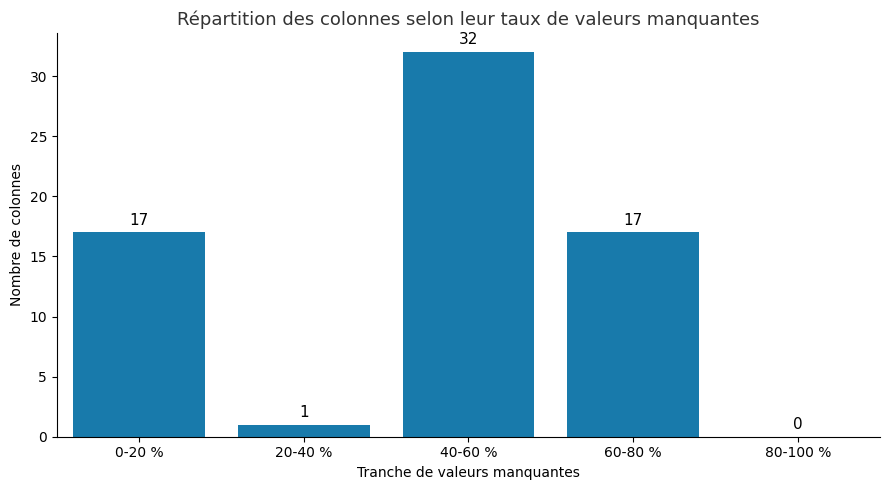

In [35]:
 #Visualisation de la repartition des colonnes par tranche de manquants
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(x=repartition.index, y=repartition.values, color="#0082C3", ax=ax)

# Annotation du nombre de colonnes au-dessus de chaque barre
for i, valeur in enumerate(repartition.values):
    ax.text(i, valeur + 0.4, str(valeur), ha="center", va="bottom", fontsize=11)

ax.set_title("Répartition des colonnes selon leur taux de valeurs manquantes",
             fontsize=13, color="#333333")
ax.set_xlabel("Tranche de valeurs manquantes")
ax.set_ylabel("Nombre de colonnes")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [36]:
# Croisement des manquants avec la famille logement
cols_logement = [c for c in application_train.columns
                 if any(m in c for m in ["APARTMENTS", "AREA", "FLOORS", "YEARS_B",
                                         "COMMONAREA", "LIVING", "NONLIVING",
                                         "ELEVATORS", "ENTRANCES", "FONDKAPREMONT",
                                         "WALLSMATERIAL", "HOUSETYPE", "EMERGENCYSTATE",
                                         "TOTALAREA", "BASEMENTAREA", "LANDAREA"])]

manquants_logement = [c for c in taux_manquants.index if c in cols_logement]
manquants_autres = [c for c in taux_manquants.index if c not in cols_logement]

print(f"Colonnes manquantes appartenant au logement : {len(manquants_logement)}")
print(f"Colonnes manquantes hors logement : {len(manquants_autres)}\n")

print("Colonnes manquantes HORS logement (taux %) :")
print(taux_manquants[manquants_autres].round(1).to_string())

Colonnes manquantes appartenant au logement : 47
Colonnes manquantes hors logement : 20

Colonnes manquantes HORS logement (taux %) :
OWN_CAR_AGE                   66.0
EXT_SOURCE_1                  56.4
OCCUPATION_TYPE               31.3
EXT_SOURCE_3                  19.8
AMT_REQ_CREDIT_BUREAU_HOUR    13.5
AMT_REQ_CREDIT_BUREAU_DAY     13.5
AMT_REQ_CREDIT_BUREAU_WEEK    13.5
AMT_REQ_CREDIT_BUREAU_MON     13.5
AMT_REQ_CREDIT_BUREAU_QRT     13.5
AMT_REQ_CREDIT_BUREAU_YEAR    13.5
NAME_TYPE_SUITE                0.4
OBS_30_CNT_SOCIAL_CIRCLE       0.3
DEF_30_CNT_SOCIAL_CIRCLE       0.3
OBS_60_CNT_SOCIAL_CIRCLE       0.3
DEF_60_CNT_SOCIAL_CIRCLE       0.3
EXT_SOURCE_2                   0.2
AMT_GOODS_PRICE                0.1
AMT_ANNUITY                    0.0
CNT_FAM_MEMBERS                0.0
DAYS_LAST_PHONE_CHANGE         0.0


In [37]:
inspecter(application_train, "application_train")

=== application_train ===
Dimensions : 307,511 lignes x 122 colonnes

Repartition des types de colonnes :
float64    65
int64      41
object     16 

Colonnes avec valeurs manquantes : 67 / 122

15 colonnes les plus affectees (% de manquants) :
COMMONAREA_MEDI             69.9
COMMONAREA_AVG              69.9
COMMONAREA_MODE             69.9
NONLIVINGAPARTMENTS_MODE    69.4
NONLIVINGAPARTMENTS_AVG     69.4
NONLIVINGAPARTMENTS_MEDI    69.4
FONDKAPREMONT_MODE          68.4
LIVINGAPARTMENTS_MODE       68.4
LIVINGAPARTMENTS_AVG        68.4
LIVINGAPARTMENTS_MEDI       68.4
FLOORSMIN_AVG               67.8
FLOORSMIN_MODE              67.8
FLOORSMIN_MEDI              67.8
YEARS_BUILD_MEDI            66.5
YEARS_BUILD_MODE            66.5

Cles de jointure presentes : ['SK_ID_CURR']


In [38]:
# Repartition des colonnes par type
print("Repartition par type :")
print(application_train.dtypes.value_counts().to_string(), "\n")

# Familles de variables identifiees par prefixe ou theme
familles = {
    "AMT (montants)": [c for c in application_train.columns if c.startswith("AMT_")],
    "DAYS (durees)": [c for c in application_train.columns if c.startswith("DAYS_")],
    "FLAG (indicateurs binaires)": [c for c in application_train.columns if c.startswith("FLAG_")],
    "EXT_SOURCE (scores externes)": [c for c in application_train.columns if c.startswith("EXT_SOURCE")],
    "Logement (habitat)": [c for c in application_train.columns if any(m in c for m in ["APARTMENTS", "AREA", "FLOORS", "YEARS_B", "COMMONAREA", "LIVING", "NONLIVING", "ELEVATORS", "ENTRANCES"])],
}
for nom, cols in familles.items():
    print(f"{nom} : {len(cols)} colonnes")

Repartition par type :
float64    65
int64      41
object     16 

AMT (montants) : 10 colonnes
DAYS (durees) : 5 colonnes
FLAG (indicateurs binaires) : 28 colonnes
EXT_SOURCE (scores externes) : 3 colonnes
Logement (habitat) : 43 colonnes


**Lecture de la composition et des manquants :**

- La table compte 122 colonnes : 65 décimales, 41 entières, 16 catégorielles.
- La famille « logement » regroupe à elle seule 43 colonnes, soit plus du tiers de la table.
- Les 67 colonnes présentant des valeurs manquantes se concentrent massivement sur cette famille logement : les 15 colonnes les plus touchées (66 à 70 % de manquants) en font toutes partie.
- Ces variables de logement existent en triplets `_AVG`, `_MODE`, `_MEDI` décrivant une même caractéristique sous trois angles statistiques, ce qui introduit une forte redondance.
- Les autres familles (montants, durées, indicateurs binaires, scores externes) sont peu ou pas affectées par les manquants.

**Stratégie d'imputation envisagée :**

L'analyse révèle des situations distinctes, traitées différemment :

- **Bloc logement (47 colonnes, 40 à 70 % de manquants)** : ces variables décrivent l'habitat et sont massivement absentes. Elles existent en triplets redondants (`_AVG`, `_MODE`, `_MEDI`). Une imputation par la médiane est envisageable, éventuellement complétée d'un indicateur de présence, sans suppression hâtive.
- **`OWN_CAR_AGE` (66 %)** : l'absence correspond vraisemblablement à l'absence de véhicule. Le manquant porte donc une information, à conserver.
- **`EXT_SOURCE_1` (56 %)** : score externe prédictif mais peu disponible ; imputation par la médiane, en gardant à l'esprit sa faible couverture.
- **`OCCUPATION_TYPE` (31 %)** : variable catégorielle, imputée par une modalité dédiée.
- **Variables `AMT_REQ_CREDIT_BUREAU` (13,5 %)** : un manquant correspond vraisemblablement à une absence de demande ; imputation par zéro plutôt que par la médiane.
- **Variables à manquant négligeable (moins de 0,5 %)** : imputation simple (médiane pour le numérique, mode ou modalité dédiée pour le catégoriel).

L'imputation effective sera réalisée dans le Pipeline, après le découpage, pour éviter toute fuite. Le Pipeline appliquera une imputation par la médiane pour le numérique et par une modalité dédiée pour le catégoriel, stratégie simple et robuste retenue pour ce premier jet.

#### La variable cible TARGET

La variable cible `TARGET` indique si le client a connu une difficulté de paiement (1) ou non (0). Sa distribution conditionne le choix des métriques, le traitement du déséquilibre éventuel et le réglage du seuil de décision lors de la modélisation.

In [39]:
# Distribution de la cible
effectifs   = application_train["TARGET"].value_counts().sort_index()
proportions = application_train["TARGET"].value_counts(normalize=True).sort_index() * 100

distribution_cible = pd.DataFrame({
    "Effectif": effectifs,
    "Proportion (%)": proportions.round(2),
})
distribution_cible.index = ["0 - sans difficulté", "1 - défaut de paiement"]
print(distribution_cible, "\n")

ratio = effectifs.loc[0] / effectifs.loc[1]
print(f"Ratio de désequilibre : {ratio:.1f} clients sans difficulté pour 1 defaut")

                        Effectif  Proportion (%)
0 - sans difficulté       282686           91.93
1 - défaut de paiement     24825            8.07 

Ratio de désequilibre : 11.4 clients sans difficulté pour 1 defaut


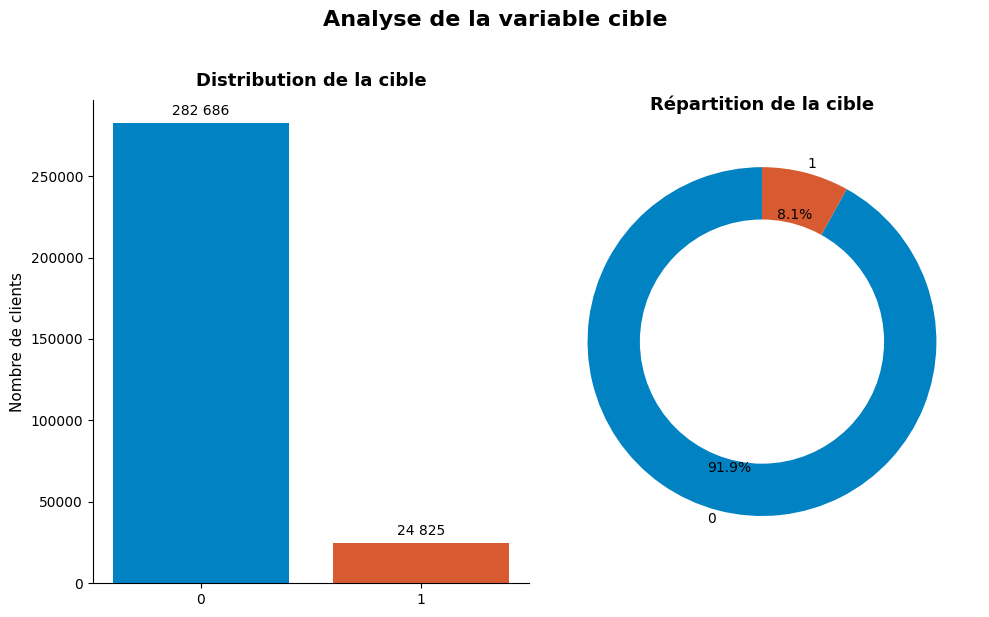

In [40]:
# Visualisation des effectifs et de la distribution de la cible

couleurs_cible = ["#0082C3",  # 0 = sans difficulté en bleur
                  "#D85A30"]  # 1 = défaut de paiement en orange

config_cible = [
    # Colonne 1 : barplot
    {
        "type": "bar",
        "col": "TARGET",
        "title": "Distribution de la cible",
        "xlabel": "",
        "ylabel": "Nombre de clients",
        "colors": couleurs_cible,
        "rotation": 0,
        "show_bar_labels": True,
        "bar_label_format": "plain",
    },
    # Colonne 2 : donut
    {
        "type": "donut",
        "col": "TARGET",
        "title": "Répartition de la cible",
        "colors": couleurs_cible,
        "show_labels": True,
        "show_pct": True,
        'donut_edgecolor': 'none',
        'pct_decimals'  : 1,
         "xlabel": "",
         "ylabel": "",
    },
]
visualisations(
    application_train,
    config_cible,
    ncols=2,
    figsize=(10, 6),
    main_title="Analyse de la variable cible",
)

**Conséquences du déséquilibre :**

La classe positive (défaut de paiement) ne représente que 8,07 % des dossiers, soit un ratio de 11,4 clients sans difficulté pour 1 défaut. Ce déséquilibre marqué a trois conséquences pour la suite du projet :

- **Métrique** : l'exactitude (accuracy) est inadaptée, car un modèle prédisant systématiquement l'absence de défaut atteindrait déjà près de 92 % sans aucune valeur prédictive. Des métriques adaptées sont privilégiées : AUC, AP (average precision) et F-bêta.
- **Traitement du déséquilibre** : des approches comme la pondération des classes ou le rééchantillonnage (SMOTE) seront testées, en veillant à ne les appliquer qu'aux données d'entraînement.
- **Seuil de décision** : le seuil par défaut de 0,5 sera vraisemblablement inadapté et devra être optimisé en fonction d'un coût métier asymétrique, où un faux négatif (accorder un crédit à un futur défaillant) coûte davantage qu'un faux positif (refuser un bon client).

Ainsi, deux contraintes caractérisent ce jeu de données. D'une part, les classes sont fortement déséquilibrées. D'autre part, les deux types d'erreurs de prédiction n'ont pas le même coût pour l'organisme : accorder un crédit à un client qui fera défaut est plus coûteux que refuser un client qui aurait remboursé.

In [41]:
# ============================================================
# Fonctions utilitaires générales
# ============================================================

def afficher_granularite(df, cle_principale, nom_table):
    """
    Affiche la granularité d'une table et vérifie si une ligne
    correspond à une valeur unique de la clé principale.
    """

    nb_lignes = len(df)
    nb_ids = df[cle_principale].nunique()
    moyenne_lignes = nb_lignes / nb_ids

    print(f"=== {nom_table} ===")
    print(f"Lignes : {nb_lignes:,}")
    print(f"{cle_principale} distincts : {nb_ids:,}")
    print(f"Moyenne de lignes par {cle_principale} : {moyenne_lignes:.2f}")

    if nb_lignes == nb_ids:
        print("Granularité : une ligne par identifiant.")
    else:
        print("Granularité : plusieurs lignes peuvent correspondre au même identifiant.")

def afficher_description_table(columns_description, nom_fichier, colonne_description="Description_Traduit"):
    """
    Affiche la description des colonnes d'une table
    à partir du dictionnaire des données.
    """
    
    desc = (
        columns_description
        .loc[
            columns_description["Table"] == nom_fichier,
            ["Row", colonne_description]
        ]
        .copy()
    )
    
    print(f"Colonnes documentées pour {nom_fichier} : {len(desc)}\n")
    
    for _, ligne in desc.iterrows():
        print(f"- {ligne['Row']} : {ligne[colonne_description]}")
    
    return desc


def detecter_paires_correlees(df, id_col="SK_ID_CURR", seuil=0.9):
    """
    Détecte les paires de variables numériques fortement corrélées.
    La colonne d'identifiant est exclue de l'analyse.
    """
    
    colonnes_numeriques = (
        df
        .select_dtypes(include="number")
        .columns
        .drop(id_col, errors="ignore")
    )
    
    corr = df[colonnes_numeriques].corr().abs()
    
    triangle_superieur = corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    )
    
    paires = (
        triangle_superieur
        .stack()
        .reset_index()
        .rename(columns={
            "level_0": "Variable_1",
            "level_1": "Variable_2",
            0: "Correlation"
        })
        .query("Correlation > @seuil")
        .sort_values("Correlation", ascending=False)
        .reset_index(drop=True)
    )
    
    return paires


def supprimer_colonnes(df, colonnes_a_supprimer, nom_table="DataFrame"):
    """
    Supprime une liste de colonnes si elles sont présentes dans le DataFrame.
    Les colonnes absentes sont ignorées.
    """
    
    colonnes_presentes = [
        col for col in colonnes_a_supprimer
        if col in df.columns
    ]
    
    df_reduit = df.drop(columns=colonnes_presentes)
    
    print(f"{nom_table} : {len(colonnes_presentes)} colonnes supprimées")
    print(f"{nom_table} : {df_reduit.shape[1]} colonnes restantes")
    
    return df_reduit


def agreger_table(df, group_key, agg_dict, prefix, ajouter_count=True):
    """
    Agrège une table au niveau d'une clé donnée.
    Les colonnes agrégées sont renommées avec un préfixe.
    """
    
    agg = df.groupby(group_key).agg(agg_dict)
    
    agg.columns = [
        f"{prefix}_{col}_{stat}".upper()
        for col, stat in agg.columns
    ]
    
    if ajouter_count:
        agg[f"{prefix.upper()}_COUNT"] = df.groupby(group_key).size()
    
    agg = agg.reset_index()
    
    print(
        f"Agrégat {prefix} : "
        f"{agg.shape[0]:,} lignes x {agg.shape[1]} colonnes"
    )
    
    return agg


def encoder_variables_categorielles(df, colonnes):
    """
    Encode les variables catégorielles en variables binaires One-Hot.
    Les colonnes absentes sont ignorées.
    """
    
    colonnes_presentes = [
        col for col in colonnes
        if col in df.columns
    ]
    
    df_encode = pd.get_dummies(
        df,
        columns=colonnes_presentes,
        dummy_na=False,
        dtype=int
    )
    
    return df_encode

### La table `application_train`

#### Granularité de `application_train`

In [42]:
# ============================================================
# Étape 1.1 — Analyse de la granularité de application_train
# ============================================================

# La table application_train constitue la table principale du projet.
# Chaque ligne correspond à un client ayant effectué une demande de crédit.
# La variable TARGET indique si le client a connu ou non un défaut de paiement.

afficher_granularite(
    df=application_train_initial,
    cle_principale="SK_ID_CURR",
    nom_table="application_train"
)

# Vérification du nombre de valeurs distinctes de la variable cible.
print("\nRépartition de la variable TARGET :")
print(application_train_initial["TARGET"].value_counts(dropna=False))

print("\nProportion de défauts de paiement (%) :")
print(
    (
        application_train_initial["TARGET"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
)

=== application_train ===
Lignes : 307,511
SK_ID_CURR distincts : 307,511
Moyenne de lignes par SK_ID_CURR : 1.00
Granularité : une ligne par identifiant.

Répartition de la variable TARGET :
TARGET
0    282686
1     24825
Name: count, dtype: int64

Proportion de défauts de paiement (%) :
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


#### Description des colonnes de `application_train`

In [43]:
# Affichage des descriptions des variables de la table
# application_train à partir du dictionnaire des données.

desc_application = afficher_description_table(
    columns_description=columns_description,
    nom_fichier="application_{train|test}.csv",
    colonne_description="Description_Traduit"
)

Colonnes documentées pour application_{train|test}.csv : 122

- SK_ID_CURR : ID du prêt dans notre échantillon
- TARGET : Variable cible (1 - client ayant des difficultés de paiement : il a eu un retard de paiement de plus de X jours sur au moins une des Y premières échéances du prêt dans notre échantillon, 0 - tous les autres cas)
- NAME_CONTRACT_TYPE : Identification si le prêt est en espèces ou renouvelable
- CODE_GENDER : Sexe du client
- FLAG_OWN_CAR : Signaler si le client possède une voiture
- FLAG_OWN_REALTY : Signaler si le client est propriétaire d'une maison ou d'un appartement
- CNT_CHILDREN : Nombre d'enfants du client
- AMT_INCOME_TOTAL : Revenu du client
- AMT_CREDIT : Montant du crédit du prêt
- AMT_ANNUITY : Rente de prêt
- AMT_GOODS_PRICE : Pour les prêts à la consommation, il s'agit du prix des biens pour lesquels le prêt est accordé.
- NAME_TYPE_SUITE : Qui accompagnait le client lors de sa demande de prêt
- NAME_INCOME_TYPE : Type de revenu du client (homme d'affai

#### Classement des variables de `application_train` par grande famillle

In [44]:
# Liste des mots-clés permettant d'identifier les variables liées au logement.
mots_cles_logement = [
    "APARTMENTS", "AREA", "FLOORS", "YEARS_B", "COMMONAREA",
    "LIVING", "NONLIVING", "ELEVATORS", "ENTRANCES",
    "FONDKAPREMONT", "WALLSMATERIAL", "HOUSETYPE",
    "EMERGENCYSTATE", "TOTALAREA", "BASEMENTAREA", "LANDAREA"
]

# Construction des différentes familles de variables.
familles = {
    "Identifiants et cible": [
        col for col in ["SK_ID_CURR", "TARGET"]
        if col in application_train_initial.columns
    ],

    "Montants (AMT)": [
        col for col in application_train_initial.columns
        if col.startswith("AMT_")
    ],

    "Variables temporelles (DAYS)": [
        col for col in application_train_initial.columns
        if col.startswith("DAYS_")
    ],

    "Scores externes": [
        col for col in application_train_initial.columns
        if col.startswith("EXT_SOURCE")
    ],

    "Documents fournis": [
        col for col in application_train_initial.columns
        if col.startswith("FLAG_DOCUMENT")
    ],

    "Autres indicateurs binaires": [
        col for col in application_train_initial.columns
        if col.startswith("FLAG_")
        and not col.startswith("FLAG_DOCUMENT")
    ],

    "Variables logement": [
        col for col in application_train_initial.columns
        if any(mot in col for mot in mots_cles_logement)
    ],

    "Entourage social": [
        col for col in application_train_initial.columns
        if "SOCIAL_CIRCLE" in col
    ],

    "Demandes auprès du bureau de crédit": [
        col for col in application_train_initial.columns
        if col.startswith("AMT_REQ_CREDIT_BUREAU")
    ],
}

# Affichage du nombre de variables par famille.
print("Répartition des variables par famille :\n")

for famille, colonnes in familles.items():
    print(f"- {famille:<40} : {len(colonnes):>2} colonnes")

# Identification des variables qui ne sont rattachées à aucune famille.
colonnes_classees = {
    col
    for liste in familles.values()
    for col in liste
}

autres_colonnes = [
    col for col in application_train_initial.columns
    if col not in colonnes_classees
]

print(f"\nAutres variables non classées : {len(autres_colonnes)}")
print(autres_colonnes)

Répartition des variables par famille :

- Identifiants et cible                    :  2 colonnes
- Montants (AMT)                           : 10 colonnes
- Variables temporelles (DAYS)             :  5 colonnes
- Scores externes                          :  3 colonnes
- Documents fournis                        : 20 colonnes
- Autres indicateurs binaires              :  8 colonnes
- Variables logement                       : 47 colonnes
- Entourage social                         :  4 colonnes
- Demandes auprès du bureau de crédit      :  6 colonnes

Autres variables non classées : 23
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'CNT_CHILDREN', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'OWN_CAR_AGE', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGIO

#### Analyse des variables de logement (_AVG, _MODE, _MEDI) de `application_train`

In [45]:
# Liste de quelques caractéristiques représentatives à étudier.
caracteristiques_logement = [
    "COMMONAREA",
    "LIVINGAPARTMENTS",
    "FLOORSMAX",
    "YEARS_BUILD"
]

print("Corrélation entre les versions _AVG, _MODE et _MEDI :\n")

for caracteristique in caracteristiques_logement:

    # Recherche des différentes versions de la caractéristique.
    colonnes = [
        col for col in application_train_initial.columns
        if col.startswith(caracteristique)
        and col.endswith(("_AVG", "_MODE", "_MEDI"))
    ]

    # Calcul uniquement si plusieurs versions existent.
    if len(colonnes) >= 2:

        matrice_corr = application_train_initial[colonnes].corr()

        correlations = matrice_corr.values[
            np.triu_indices_from(matrice_corr.values, k=1)
        ]

        correlation_moyenne = correlations.mean()

        print(
            f"{caracteristique:<20}"
            f"{len(colonnes)} versions"
            f"  |  Corrélation moyenne : {correlation_moyenne:.3f}"
        )

Corrélation entre les versions _AVG, _MODE et _MEDI :

COMMONAREA          3 versions  |  Corrélation moyenne : 0.984
LIVINGAPARTMENTS    3 versions  |  Corrélation moyenne : 0.980
FLOORSMAX           3 versions  |  Corrélation moyenne : 0.990
YEARS_BUILD         3 versions  |  Corrélation moyenne : 0.992


#### Vérifions si la conservation exclusive de _MEDI entraîne une perte d'information

In [46]:
# ============================================================
# Étape 1.5 — Vérification des valeurs récupérables
# ============================================================

# Exemple sur la variable COMMONAREA.
# Le même raisonnement pourra être étendu aux autres variables logement.

caracteristique = "COMMONAREA"

col_medi = f"{caracteristique}_MEDI"
col_avg = f"{caracteristique}_AVG"
col_mode = f"{caracteristique}_MODE"

# Lignes où la version médiane est manquante.
medi_manquant = application_train_initial[col_medi].isna()

# Lignes où une autre version est disponible.
avg_present = application_train_initial[col_avg].notna()
mode_present = application_train_initial[col_mode].notna()

# Nombre de cas où _MEDI est absente alors que _AVG ou _MODE existe.
cas_recuperables = (
    medi_manquant &
    (avg_present | mode_present)
).sum()

print(f"Valeurs manquantes dans {col_medi} : {medi_manquant.sum():,}")
print(f"Valeurs récupérables via _AVG ou _MODE : {cas_recuperables:,}")

Valeurs manquantes dans COMMONAREA_MEDI : 214,865
Valeurs récupérables via _AVG ou _MODE : 0


#### Identifier toutes les variables de logement concernées

In [47]:
# Identification de toutes les colonnes se terminant par _AVG, _MODE ou _MEDI.
colonnes_avg = {
    col[:-4]
    for col in application_train_initial.columns
    if col.endswith("_AVG")
}

colonnes_mode = {
    col[:-5]
    for col in application_train_initial.columns
    if col.endswith("_MODE")
}

colonnes_medi = {
    col[:-5]
    for col in application_train_initial.columns
    if col.endswith("_MEDI")
}

# Caractéristiques présentes dans les trois versions.
caracteristiques_triplets = sorted(
    colonnes_avg & colonnes_mode & colonnes_medi
)

print(
    f"Nombre de caractéristiques disposant des trois versions "
    f"(_AVG, _MODE et _MEDI) : {len(caracteristiques_triplets)}\n"
)

for caracteristique in caracteristiques_triplets:
    print(f"- {caracteristique}")

Nombre de caractéristiques disposant des trois versions (_AVG, _MODE et _MEDI) : 14

- APARTMENTS
- BASEMENTAREA
- COMMONAREA
- ELEVATORS
- ENTRANCES
- FLOORSMAX
- FLOORSMIN
- LANDAREA
- LIVINGAPARTMENTS
- LIVINGAREA
- NONLIVINGAPARTMENTS
- NONLIVINGAREA
- YEARS_BEGINEXPLUATATION
- YEARS_BUILD


#### Construire proprement la liste des variables logement à conserver

In [48]:
# ============================================================
# Étape 1.7 — Sélection des variables logement à conserver
# ============================================================

# Conservation des versions _MEDI pour les caractéristiques
# disponibles sous les trois formes (_AVG, _MODE et _MEDI).
colonnes_logement_medi = [
    f"{caracteristique}_MEDI"
    for caracteristique in caracteristiques_triplets
]

# Colonnes logement ne possédant pas de suffixe _AVG, _MODE ou _MEDI.
colonnes_logement_sans_suffixe = [
    col
    for col in application_train_initial.columns
    if (
        any(caracteristique in col for caracteristique in caracteristiques_triplets)
        and not col.endswith(("_AVG", "_MODE", "_MEDI"))
    )
]

# Liste finale des variables logement conservées.
colonnes_logement_conservees = (
    colonnes_logement_medi +
    colonnes_logement_sans_suffixe
)

# Liste des variables logement supprimées.
colonnes_logement_supprimees = [
    col
    for col in application_train_initial.columns
    if (
        any(caracteristique in col for caracteristique in caracteristiques_triplets)
        and col not in colonnes_logement_conservees
    )
]
print(f"Variables logement conservées : {len(colonnes_logement_conservees)}")
print(f"Variables logement supprimées : {len(colonnes_logement_supprimees)}")

Variables logement conservées : 14
Variables logement supprimées : 28


#### Analyse des corrélations dans `application_train`

In [49]:
# Détection des paires de variables numériques dont la corrélation
# absolue est supérieure au seuil défini.

SEUIL_CORRELATION = 0.90

paires_correlees_app = detecter_paires_correlees(
    df=application_train_initial,
    id_col="SK_ID_CURR",
    seuil=SEUIL_CORRELATION
)

print(
    f"Nombre de paires avec une corrélation supérieure à "
    f"{SEUIL_CORRELATION} : {len(paires_correlees_app)}"
)

display(paires_correlees_app)

Nombre de paires avec une corrélation supérieure à 0.9 : 62


,Variable_1,Variable_2,Correlation
0,DAYS_EMPLOYED,FLAG_EMP_PHONE,0.999755
1,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.998495
2,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.998490
3,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.997241
4,FLOORSMAX_AVG,FLOORSMAX_MEDI,0.997034
5,ENTRANCES_AVG,ENTRANCES_MEDI,0.996886
6,ELEVATORS_AVG,ELEVATORS_MEDI,0.996099
7,COMMONAREA_AVG,COMMONAREA_MEDI,0.995978
8,LIVINGAREA_AVG,LIVINGAREA_MEDI,0.995596
9,APARTMENTS_AVG,APARTMENTS_MEDI,0.995081


#### Réduction prudente de `application_train`

In [50]:
# La réduction appliquée ici reste volontairement prudente.
# Seules les redondances structurelles sont supprimées.
# Les autres variables seront conservées et évaluées plus tard
# lors de la phase de modélisation.

# 1. Suppression des versions _AVG et _MODE des variables logement.
# La version _MEDI est conservée pour représenter chaque caractéristique.
colonnes_logement_redondantes = [
    col
    for col in application_train_initial.columns
    if col.endswith(("_AVG", "_MODE"))
]

# 2. Suppression des flags documents.
# Ces variables binaires seront remplacées par une seule variable synthétique :
# le nombre total de documents fournis.
colonnes_flag_documents = [
    col
    for col in application_train_initial.columns
    if col.startswith("FLAG_DOCUMENT")
]

# 3. Construction de la liste finale des colonnes à supprimer.
colonnes_a_supprimer = sorted(
    set(
        colonnes_logement_redondantes
        + colonnes_flag_documents
    )
)

print(f"Colonnes logement redondantes supprimées : {len(colonnes_logement_redondantes)}")
print(f"Flags documents supprimés : {len(colonnes_flag_documents)}")
print(f"Nombre total de colonnes à supprimer : {len(colonnes_a_supprimer)}")

Colonnes logement redondantes supprimées : 33
Flags documents supprimés : 20
Nombre total de colonnes à supprimer : 53


#### Création de la table application réduite

In [51]:
# Création d'une copie réduite de application_train.
# Les colonnes redondantes identifiées sont supprimées.
app_reduit = application_train.drop(
    columns=colonnes_a_supprimer,
    errors="ignore"
).copy()

# Création d'une variable synthétique indiquant le nombre total
# de documents fournis par chaque client.
app_reduit["NB_DOCUMENTS_FOURNIS"] = (
    application_train[colonnes_flag_documents]
    .sum(axis=1)
)

print(f"Nombre de colonnes avant réduction : {application_train.shape[1]}")
print(f"Nombre de colonnes après réduction : {app_reduit.shape[1]}")
print(f"Nombre de lignes : {app_reduit.shape[0]:,}")

Nombre de colonnes avant réduction : 122
Nombre de colonnes après réduction : 70
Nombre de lignes : 307,511


#### Vérification de la table réduite

In [52]:
# Vérification que la clé client et la cible sont toujours présentes.
colonnes_essentielles = ["SK_ID_CURR", "TARGET"]

for col in colonnes_essentielles:
    print(f"{col} présent : {col in app_reduit.columns}")

# Vérification que les flags documents ont bien été supprimés.
flags_restants = [
    col for col in app_reduit.columns
    if col.startswith("FLAG_DOCUMENT")
]

print(f"Flags documents restants : {len(flags_restants)}")

# Vérification que la nouvelle variable synthétique est bien présente.
print(f"NB_DOCUMENTS_FOURNIS présent : {'NB_DOCUMENTS_FOURNIS' in app_reduit.columns}")

SK_ID_CURR présent : True
TARGET présent : True
Flags documents restants : 0
NB_DOCUMENTS_FOURNIS présent : True


In [53]:
app_reduit.shape

(307511, 70)

### La table `bureau`

#### Analyse de la granularité de `bureau`

In [54]:
# La table bureau contient les crédits externes des clients.
# Chaque ligne correspond à un crédit déclaré dans un bureau de crédit.
# Un même client peut donc apparaître plusieurs fois.

afficher_granularite(
    df=bureau,
    cle_principale="SK_ID_CURR",
    nom_table="bureau"
)

# Vérification complémentaire du nombre de crédits externes distincts.
print(f"SK_ID_BUREAU distincts : {bureau['SK_ID_BUREAU'].nunique():,}")

=== bureau ===
Lignes : 1,716,428
SK_ID_CURR distincts : 305,811
Moyenne de lignes par SK_ID_CURR : 5.61
Granularité : plusieurs lignes peuvent correspondre au même identifiant.
SK_ID_BUREAU distincts : 1,716,428


#### Description des colonnes de `bureau`

In [55]:
# Affichage des descriptions des variables de bureau
# à partir du dictionnaire des données.

desc_bureau = afficher_description_table(
    columns_description=columns_description,
    nom_fichier="bureau.csv",
    colonne_description="Description_Traduit"
)

Colonnes documentées pour bureau.csv : 17

- SK_ID_CURR : ID du prêt dans notre échantillon - un prêt de notre échantillon peut avoir 0,1,2 crédits antérieurs ou plus dans le bureau de crédit
- SK_BUREAU_ID : ID recodé du crédit précédent du bureau de crédit lié à notre prêt (codage unique pour chaque demande de prêt)
- CREDIT_ACTIVE : Statut des crédits déclarés par le Bureau de crédit (CB)
- CREDIT_CURRENCY : Devise recodée du crédit du Bureau de Crédit
- DAYS_CREDIT : Combien de jours avant la demande actuelle le client a-t-il demandé un crédit au bureau de crédit ?
- CREDIT_DAY_OVERDUE : Nombre de jours de retard sur le crédit CB au moment de la demande de prêt associé dans notre échantillon
- DAYS_CREDIT_ENDDATE : Durée restante du crédit CB (en jours) au moment de la demande en Crédit Habitation
- DAYS_ENDDATE_FACT : Jours depuis la fin du crédit CB au moment de la demande en Crédit Habitation (uniquement pour le crédit clôturé)
- AMT_CREDIT_MAX_OVERDUE : Montant maximum en souff

#### Interprétation de la table `bureau`

La table `bureau` contient l'historique des crédits contractés par les clients auprès d'autres institutions financières.

- Une ligne correspond à un crédit externe (`SK_ID_BUREAU`).
- Un même client (`SK_ID_CURR`) peut être associé à plusieurs crédits externes.
- Les variables décrivent notamment :
  - l'ancienneté du crédit ;
  - son statut (actif ou clôturé) ;
  - les montants empruntés et restant dus ;
  - les éventuels retards de paiement ;
  - les prolongations de crédit.

L'objectif est de résumer ces informations au niveau du client (`SK_ID_CURR`) afin de les intégrer au jeu de données principal.

#### Étude de bureau avant toute agrégation `bureau`

In [56]:
# ============================================================
# Inventaire des variables de bureau
# ============================================================

# Résumé des variables de la table bureau.
resume_bureau = pd.DataFrame({
    "Type": bureau_initial.dtypes.astype(str),
    "Valeurs_manquantes": bureau_initial.isna().sum(),
    "Pourcentage_manquants": (
        bureau_initial.isna().mean() * 100
    ).round(2),
    "Nombre_valeurs_uniques": bureau_initial.nunique()
})

display(resume_bureau.sort_values(
    by="Pourcentage_manquants",
    ascending=False
))

,Type,Valeurs_manquantes,Pourcentage_manquants,Nombre_valeurs_uniques
AMT_ANNUITY,float64,1226791,71.47,40321
AMT_CREDIT_MAX_OVERDUE,float64,1124488,65.51,68251
DAYS_ENDDATE_FACT,float64,633653,36.92,2917
AMT_CREDIT_SUM_LIMIT,float64,591780,34.48,51726
AMT_CREDIT_SUM_DEBT,float64,257669,15.01,226537
DAYS_CREDIT_ENDDATE,float64,105553,6.15,14096
CREDIT_ACTIVE,object,0,0.00,4
CREDIT_CURRENCY,object,0,0.00,4
DAYS_CREDIT,int64,0,0.00,2923
CREDIT_DAY_OVERDUE,int64,0,0.00,942


#### Classement des variables de `bureau` par famille

In [57]:
# Les variables sont regroupées par grandes catégories afin
# de faciliter le choix des statistiques d'agrégation.

familles_bureau = {
    "Identifiants": [
        "SK_ID_CURR",
        "SK_ID_BUREAU"
    ],

    "Variables temporelles": [
        col for col in bureau_initial.columns
        if col.startswith("DAYS_")
    ],

    "Montants financiers": [
        col for col in bureau_initial.columns
        if col.startswith("AMT_")
    ],

    "Retards de paiement": [
        col for col in bureau_initial.columns
        if "OVERDUE" in col
    ],

    "Prolongations de crédit": [
        col for col in bureau_initial.columns
        if "PROLONG" in col
    ],

    "Variables catégorielles": [
        col for col in bureau_initial.select_dtypes(include="object").columns
    ]
}

print("Répartition des variables de bureau :\n")

for famille, colonnes in familles_bureau.items():
    print(f"- {famille:<30} : {len(colonnes):>2} colonnes")
    print(f"  {colonnes}\n")

Répartition des variables de bureau :

- Identifiants                   :  2 colonnes
  ['SK_ID_CURR', 'SK_ID_BUREAU']

- Variables temporelles          :  4 colonnes
  ['DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE']

- Montants financiers            :  6 colonnes
  ['AMT_CREDIT_MAX_OVERDUE', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'AMT_ANNUITY']

- Retards de paiement            :  3 colonnes
  ['CREDIT_DAY_OVERDUE', 'AMT_CREDIT_MAX_OVERDUE', 'AMT_CREDIT_SUM_OVERDUE']

- Prolongations de crédit        :  1 colonnes
  ['CNT_CREDIT_PROLONG']

- Variables catégorielles        :  3 colonnes
  ['CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'CREDIT_TYPE']



#### Encodage de `CREDIT_ACTIVE`

In [58]:
# Transformation de la variable catégorielle CREDIT_ACTIVE
# en variables binaires (One-Hot Encoding).
bureau = encoder_variables_categorielles(
    df=bureau,
    colonnes=["CREDIT_ACTIVE"]
)

# Identification automatique des colonnes créées.
colonnes_credit_active = [
    col
    for col in bureau.columns
    if col.startswith("CREDIT_ACTIVE_")
]

print("Colonnes créées :")
print(colonnes_credit_active)

Colonnes créées :
['CREDIT_ACTIVE_Active', 'CREDIT_ACTIVE_Bad debt', 'CREDIT_ACTIVE_Closed', 'CREDIT_ACTIVE_Sold']


### Analyse de la table `bureau_balance`

#### Analyse de la granularité de `bureau_balance`

In [59]:
# La table bureau_balance contient l'historique mensuel des crédits
# présents dans la table bureau.
# Chaque ligne correspond à un mois d'observation pour un crédit externe.

afficher_granularite(
    df=bureau_balance_initial,
    cle_principale="SK_ID_BUREAU",
    nom_table="bureau_balance"
)

# Nombre total de mois observés par crédit.
print(
    f"\nNombre moyen d'observations mensuelles par crédit : "
    f"{len(bureau_balance_initial) / bureau_balance_initial['SK_ID_BUREAU'].nunique():.1f}"
)

=== bureau_balance ===
Lignes : 27,299,925
SK_ID_BUREAU distincts : 817,395
Moyenne de lignes par SK_ID_BUREAU : 33.40
Granularité : plusieurs lignes peuvent correspondre au même identifiant.

Nombre moyen d'observations mensuelles par crédit : 33.4


#### Description des colonnes de `bureau_balance`

In [60]:
desc_bureau_balance = afficher_description_table(
    columns_description=columns_description,
    nom_fichier="bureau_balance.csv",
    colonne_description="Description_Traduit"
)

Colonnes documentées pour bureau_balance.csv : 3

- SK_BUREAU_ID : ID recodé du crédit du bureau de crédit (codage unique pour chaque demande) - utilisez-le pour rejoindre la table CREDIT_BUREAU
- MONTHS_BALANCE : Mois du solde par rapport à la date de demande (-1 signifie la date du solde le plus récent)
- STATUS : Statut du prêt du bureau de crédit au cours du mois (actif, fermé, DPD0-30, [C signifie fermé, X signifie statut inconnu, 0 signifie pas de DPD, 1 signifie maximum au cours du mois entre 1 et 30, 2 signifie DPD 31-60, 5 signifie DPD 120+ ou vendu ou radié])


#### Analyse de la variable STATUS de `bureau_balance` avant encodageer 

In [61]:
# La variable STATUS décrit la situation mensuelle du crédit externe.
# Son analyse permet de comprendre la fréquence des différents états
# avant leur transformation en variables binaires.

distribution_status = (
    bureau_balance_initial["STATUS"]
    .value_counts(dropna=False)
    .to_frame(name="Nombre")
)

distribution_status["Pourcentage"] = (
    distribution_status["Nombre"]
    / distribution_status["Nombre"].sum()
    * 100
).round(2)

display(distribution_status)

,Nombre,Pourcentage
STATUS,,
C,13646993,49.99
0,7499507,27.47
X,5810482,21.28
1,242347,0.89
5,62406,0.23
2,23419,0.09
3,8924,0.03
4,5847,0.02


#### Agrégation optimisée de `bureau_balance`

In [62]:
# Copie de travail.
bb = bureau_balance.copy()

# Encodage de la variable catégorielle STATUS.
bb = encoder_variables_categorielles(
    df=bb,
    colonnes=["STATUS"]
)

# Construction du dictionnaire d'agrégation.

agg_dict_bb = {
    # Ancienneté de l'historique disponible pour le crédit.
    "MONTHS_BALANCE": ["min", "max"]
}

# Les variables issues du One-Hot Encoding sont agrégées par la moyenne.
# La moyenne représente la proportion de mois passés dans chaque état.
colonnes_status = [
    col
    for col in bb.columns
    if col.startswith("STATUS_")
]

for col in colonnes_status:
    agg_dict_bb[col] = ["mean"]

# Agrégation au niveau du crédit externe.
bb_agg = agreger_table(
    df=bb,
    group_key="SK_ID_BUREAU",
    agg_dict=agg_dict_bb,
    prefix="BB",
    ajouter_count=True
)

Agrégat BB : 817,395 lignes x 12 colonnes


#### Granularité de `bureau_balance`

In [63]:
bb_agg = agreger_table(
    df=bb,
    group_key="SK_ID_BUREAU",
    agg_dict=agg_dict_bb,
    prefix="BB",
    ajouter_count=False
)

Agrégat BB : 817,395 lignes x 11 colonnes


#### Fusion de `bureau` avec `bureau_balance` agrégé

In [64]:
# Fusion de bureau avec l'agrégat bureau_balance.
# La jointure se fait au niveau du crédit externe SK_ID_BUREAU.
bureau_enrichi = bureau.merge(
    bb_agg,
    on="SK_ID_BUREAU",
    how="left"
)
print(f"bureau initial : {bureau.shape[0]:,} lignes x {bureau.shape[1]} colonnes")
print(f"bb_agg : {bb_agg.shape[0]:,} crédits x {bb_agg.shape[1]} colonnes")
print(f"bureau enrichi : {bureau_enrichi.shape[0]:,} lignes x {bureau_enrichi.shape[1]} colonnes")

bureau initial : 1,716,428 lignes x 20 colonnes
bb_agg : 817,395 crédits x 11 colonnes
bureau enrichi : 1,716,428 lignes x 30 colonnes


#### Vérification de la fusion `bureau` / `bureau_balance`

In [65]:
# Identification des colonnes issues de bureau_balance.
colonnes_bb = [
    col for col in bureau_enrichi.columns
    if col.startswith("BB_")
]

# Nombre de crédits bureau ayant au moins une information bureau_balance.
credits_avec_balance = bureau_enrichi[colonnes_bb].notna().any(axis=1).sum()

# Nombre total de crédits bureau.
total_credits_bureau = len(bureau_enrichi)

# Part des crédits enrichis par bureau_balance.
part_credits_avec_balance = credits_avec_balance / total_credits_bureau * 100

print(f"Crédits bureau au total : {total_credits_bureau:,}")
print(f"Crédits avec historique bureau_balance : {credits_avec_balance:,}")
print(f"Part des crédits avec historique bureau_balance : {part_credits_avec_balance:.2f} %")

Crédits bureau au total : 1,716,428
Crédits avec historique bureau_balance : 774,354
Part des crédits avec historique bureau_balance : 45.11 %


#### Interprétation de la couverture de `bureau_balance`

La fusion montre que 45,11 % des crédits externes présents dans `bureau` disposent d'un historique mensuel dans `bureau_balance`.

Cela signifie que `bureau_balance` ne couvre pas tous les crédits externes. Les variables issues de cette table apporteront donc une information utile pour une partie des crédits, mais elles contiendront aussi des valeurs manquantes après fusion.

Ce point devra être pris en compte lors de l'imputation dans le pipeline de modélisation.

#### Agrégation `bureau_enrichi` au niveau client

In [66]:
agg_dict_bureau = {
    "DAYS_CREDIT": ["min", "max", "mean"],
    "DAYS_CREDIT_ENDDATE": ["min", "max", "mean"],
    "DAYS_ENDDATE_FACT": ["mean"],
    "DAYS_CREDIT_UPDATE": ["mean"],
    "CREDIT_DAY_OVERDUE": ["max", "mean"],
    "AMT_CREDIT_MAX_OVERDUE": ["max", "mean"],
    "AMT_CREDIT_SUM_OVERDUE": ["max", "sum"],
    "AMT_CREDIT_SUM": ["sum", "mean", "max"],
    "AMT_CREDIT_SUM_DEBT": ["sum", "mean", "max"],
    "AMT_CREDIT_SUM_LIMIT": ["sum", "mean"],
    "AMT_ANNUITY": ["mean", "sum"],
    "CNT_CREDIT_PROLONG": ["sum", "max"],
}

# Les colonnes issues de bureau_balance et de CREDIT_ACTIVE sont binaires
# ou proportionnelles. Leur moyenne au niveau client représente une proportion.
colonnes_bb = [col for col in bureau_enrichi.columns if col.startswith("BB_")]
colonnes_credit_active = [
    col for col in bureau_enrichi.columns
    if col.startswith("CREDIT_ACTIVE_")
]

for col in colonnes_bb + colonnes_credit_active:
    agg_dict_bureau[col] = ["mean"]

agg_bureau = agreger_table(
    df=bureau_enrichi,
    group_key="SK_ID_CURR",
    agg_dict=agg_dict_bureau,
    prefix="BUREAU",
    ajouter_count=True
)

Agrégat BUREAU : 305,811 lignes x 42 colonnes


#### Vérification des corrélations de `agg_bureau`

In [67]:
SEUIL_CORRELATION = 0.90

paires_correlees_bureau = detecter_paires_correlees(
    df=agg_bureau,
    id_col="SK_ID_CURR",
    seuil=SEUIL_CORRELATION
)

print(
    f"Nombre de paires fortement corrélées (> {SEUIL_CORRELATION}) : "
    f"{len(paires_correlees_bureau)}"
)

display(paires_correlees_bureau)

Nombre de paires fortement corrélées (> 0.9) : 6


,Variable_1,Variable_2,Correlation
0,BUREAU_DAYS_CREDIT_MEAN,BUREAU_BB_MONTHS_BALANCE_MIN_MEAN,0.999749
1,BUREAU_CREDIT_ACTIVE_ACTIVE_MEAN,BUREAU_CREDIT_ACTIVE_CLOSED_MEAN,0.992557
2,BUREAU_CNT_CREDIT_PROLONG_SUM,BUREAU_CNT_CREDIT_PROLONG_MAX,0.988729
3,BUREAU_AMT_CREDIT_SUM_OVERDUE_MAX,BUREAU_AMT_CREDIT_SUM_OVERDUE_SUM,0.961685
4,BUREAU_AMT_CREDIT_SUM_DEBT_SUM,BUREAU_AMT_CREDIT_SUM_DEBT_MAX,0.955127
5,BUREAU_AMT_CREDIT_MAX_OVERDUE_MAX,BUREAU_AMT_CREDIT_MAX_OVERDUE_MEAN,0.950273


#### Suppression des redondances dans `agg_bureau`

In [68]:
# Les variables ci-dessous sont supprimées à la suite de l'analyse
# des corrélations et d'une justification métier.

colonnes_redondantes_bureau = [

    # Quasi équivalente à BUREAU_DAYS_CREDIT_MEAN.
    "BUREAU_BB_MONTHS_BALANCE_MIN_MEAN",

    # Complémentaire de BUREAU_CREDIT_ACTIVE_ACTIVE_MEAN.
    "BUREAU_CREDIT_ACTIVE_CLOSED_MEAN",

    # Très fortement corrélée à la somme des prolongations.
    "BUREAU_CNT_CREDIT_PROLONG_MAX",

    # La somme est conservée comme indicateur global.
    "BUREAU_AMT_CREDIT_SUM_OVERDUE_MAX",

    # La somme est conservée comme exposition totale.
    "BUREAU_AMT_CREDIT_SUM_DEBT_MAX",

    # Le maximum est conservé comme indicateur du pire retard observé.
    "BUREAU_AMT_CREDIT_MAX_OVERDUE_MEAN",
]

agg_bureau = supprimer_colonnes(
    df=agg_bureau,
    colonnes_a_supprimer=colonnes_redondantes_bureau,
    nom_table="agg_bureau"
)

agg_bureau : 6 colonnes supprimées
agg_bureau : 36 colonnes restantes


#### Granularité de `bureau`

#### Étape 1: Décrire les colonnes de application_train et application_test

In [69]:
# ============================================================
# Étape 1 — Description des colonnes de la table application
# ============================================================

# Filtrage du dictionnaire des données pour ne conserver que les descriptions
# relatives aux fichiers application_train.csv et application_test.csv.
desc_application = (
    columns_description
    .loc[
        columns_description["Table"] == "application_{train|test}.csv",
        ["Row", "Description_Traduit"]
    ]
    .copy()
)

# Affichage du nombre total de colonnes documentées.
print(f"Nombre de colonnes documentées : {len(desc_application)}\n")

# Affichage de chaque colonne avec sa description.
for _, ligne in desc_application.iterrows():
    print(f"- {ligne['Row']} : {ligne['Description_Traduit']}")

Nombre de colonnes documentées : 122

- SK_ID_CURR : ID du prêt dans notre échantillon
- TARGET : Variable cible (1 - client ayant des difficultés de paiement : il a eu un retard de paiement de plus de X jours sur au moins une des Y premières échéances du prêt dans notre échantillon, 0 - tous les autres cas)
- NAME_CONTRACT_TYPE : Identification si le prêt est en espèces ou renouvelable
- CODE_GENDER : Sexe du client
- FLAG_OWN_CAR : Signaler si le client possède une voiture
- FLAG_OWN_REALTY : Signaler si le client est propriétaire d'une maison ou d'un appartement
- CNT_CHILDREN : Nombre d'enfants du client
- AMT_INCOME_TOTAL : Revenu du client
- AMT_CREDIT : Montant du crédit du prêt
- AMT_ANNUITY : Rente de prêt
- AMT_GOODS_PRICE : Pour les prêts à la consommation, il s'agit du prix des biens pour lesquels le prêt est accordé.
- NAME_TYPE_SUITE : Qui accompagnait le client lors de sa demande de prêt
- NAME_INCOME_TYPE : Type de revenu du client (homme d'affaires, actif, congé de mat

#### Étape 2: Regrouper les colonnes par grandes familles

In [70]:
# ============================================================
# Étape 2 — Inventaire des colonnes par famille
# ============================================================

# Liste des mots-clés permettant d'identifier les variables liées au logement.
LOGEMENT_KEYWORDS = [
    "APARTMENTS", "AREA", "FLOORS", "YEARS_B", "COMMONAREA",
    "LIVING", "NONLIVING", "ELEVATORS", "ENTRANCES",
    "FONDKAPREMONT", "WALLSMATERIAL", "HOUSETYPE",
    "EMERGENCYSTATE", "TOTALAREA", "BASEMENTAREA", "LANDAREA"
]
# Fonction utilitaire pour récupérer les colonnes commençant par un préfixe donné.
def colonnes_commencant_par(df, prefix):
    return [col for col in df.columns if col.startswith(prefix)]

# Fonction utilitaire pour récupérer les colonnes contenant au moins un mot-clé donné.
def colonnes_contenant(df, keywords):
    return [col for col in df.columns if any(keyword in col for keyword in keywords)]

# Regroupement des colonnes de la table application_train par grandes familles.
familles = {
    "Identifiants et cible": [
        col for col in ["SK_ID_CURR", "TARGET"]
        if col in application_train.columns
    ],
    
    "Montants (AMT)": colonnes_commencant_par(application_train, "AMT_"),
    
    "Durées (DAYS)": colonnes_commencant_par(application_train, "DAYS_"),
    
    "Scores externes": colonnes_commencant_par(application_train, "EXT_SOURCE"),
    
    "Flags documents": colonnes_commencant_par(application_train, "FLAG_DOCUMENT"),
    
    "Autres flags": [
        col for col in application_train.columns
        if col.startswith("FLAG_") and not col.startswith("FLAG_DOCUMENT")
    ],
    
    "Logement": colonnes_contenant(application_train, LOGEMENT_KEYWORDS),
    
    "Entourage social": [
        col for col in application_train.columns
        if "SOCIAL_CIRCLE" in col
    ],
    
    "Demandes bureau": colonnes_commencant_par(
        application_train,
        "AMT_REQ_CREDIT_BUREAU"
    ),
}

# Affichage du nombre de colonnes par famille.
for nom_famille, colonnes in familles.items():
    print(f"{nom_famille} : {len(colonnes)} colonnes")

# Identification des colonnes qui ne sont pas classées dans les familles définies.
colonnes_classees = sorted(set(col for colonnes in familles.values() for col in colonnes))

autres_colonnes = [
    col for col in application_train.columns
    if col not in colonnes_classees
]

# Affichage des colonnes non classées.
print(f"\nAutres colonnes non classées : {len(autres_colonnes)}")
print(autres_colonnes)

Identifiants et cible : 2 colonnes
Montants (AMT) : 10 colonnes
Durées (DAYS) : 5 colonnes
Scores externes : 3 colonnes
Flags documents : 20 colonnes
Autres flags : 8 colonnes
Logement : 47 colonnes
Entourage social : 4 colonnes
Demandes bureau : 6 colonnes

Autres colonnes non classées : 23
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'CNT_CHILDREN', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'OWN_CAR_AGE', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE']


In [71]:
# ============================================================
# Étape 3 — Analyse de la redondance des variables logement
# ============================================================

# Certaines variables de logement existent en trois versions :
# _AVG, _MODE et _MEDI.
# Cette analyse vérifie si ces versions sont fortement corrélées entre elles.

def analyser_versions_logement(df, caracteristiques):
    """
    Analyse la corrélation moyenne entre les versions _AVG, _MODE et _MEDI
    d'une même caractéristique de logement.
    """
    
    resultats = []

    for caracteristique in caracteristiques:
        
        # Sélection des colonnes correspondant à la caractéristique étudiée.
        versions = [
            col for col in df.columns
            if col.startswith(caracteristique)
            and col.endswith(("_AVG", "_MODE", "_MEDI"))
        ]

        # La corrélation est calculée uniquement si au moins deux versions existent.
        if len(versions) >= 2:
            corr = df[versions].corr().abs()

            # Extraction du triangle supérieur de la matrice de corrélation
            # afin d'éviter les doublons et la diagonale.
            correlations_hors_diagonale = corr.values[
                np.triu_indices_from(corr.values, k=1)
            ]

            corr_moyenne = correlations_hors_diagonale.mean()

            resultats.append({
                "Caracteristique": caracteristique,
                "Versions": versions,
                "Nombre_versions": len(versions),
                "Correlation_moyenne": corr_moyenne
            })

    return pd.DataFrame(resultats)


# Liste de caractéristiques testées pour vérifier la redondance.
caracteristiques_test = [
    "COMMONAREA",
    "LIVINGAPARTMENTS",
    "FLOORSMAX",
    "YEARS_BUILD"
]

# Calcul de la corrélation moyenne entre les versions _AVG, _MODE et _MEDI.
analyse_logement = analyser_versions_logement(
    application_train_initial,
    caracteristiques_test
)

# Affichage du résultat.
display(analyse_logement)

,Caracteristique,Versions,Nombre_versions,Correlation_moyenne
0,COMMONAREA,"[COMMONAREA_AVG, COMMONAREA_MODE, COMMONAREA_MEDI]",3,0.984337
1,LIVINGAPARTMENTS,"[LIVINGAPARTMENTS_AVG, LIVINGAPARTMENTS_MODE, LIVINGAPARTMENTS_MEDI]",3,0.979849
2,FLOORSMAX,"[FLOORSMAX_AVG, FLOORSMAX_MODE, FLOORSMAX_MEDI]",3,0.990320
3,YEARS_BUILD,"[YEARS_BUILD_AVG, YEARS_BUILD_MODE, YEARS_BUILD_MEDI]",3,0.992467


In [72]:
# ============================================================
# Étape 4 — Vérification des valeurs récupérables entre versions
# ============================================================

def verifier_recuperation_versions(df, caracteristique):
    """
    Vérifie si les valeurs manquantes dans la version _MEDI
    peuvent être partiellement récupérées à partir des versions _AVG ou _MODE.
    """
    
    medi = f"{caracteristique}_MEDI"
    avg  = f"{caracteristique}_AVG"
    mode = f"{caracteristique}_MODE"

    colonnes_requises = [medi, avg, mode]

    # Vérification de la présence des colonnes nécessaires.
    colonnes_absentes = [
        col for col in colonnes_requises
        if col not in df.columns
    ]

    if colonnes_absentes:
        print(f"Colonnes absentes pour {caracteristique} : {colonnes_absentes}")
        return None

    # Identification des lignes où la version _MEDI est manquante.
    medi_manquant = df[medi].isna()

    # Identification des lignes où _AVG ou _MODE est disponible.
    avg_present = df[avg].notna()
    mode_present = df[mode].notna()

    # Comptage des lignes où _MEDI manque mais où une autre version est disponible.
    cas_recuperables = (
        medi_manquant & (avg_present | mode_present)
    ).sum()

    print(f"{caracteristique} : {medi_manquant.sum():,} valeurs _MEDI manquantes")
    print(
        f"Parmi elles, {cas_recuperables:,} pourraient être récupérées "
        f"via _AVG ou _MODE"
    )

    return {
        "caracteristique": caracteristique,
        "medi_manquant": medi_manquant.sum(),
        "cas_recuperables": cas_recuperables
    }


# Exemple de vérification sur la caractéristique COMMONAREA.
verifier_recuperation_versions(
    application_train_initial,
    "COMMONAREA"
)

COMMONAREA : 214,865 valeurs _MEDI manquantes
Parmi elles, 0 pourraient être récupérées via _AVG ou _MODE


{'caracteristique': 'COMMONAREA',
 'medi_manquant': np.int64(214865),
 'cas_recuperables': np.int64(0)}

In [73]:
# ============================================================
# Étape 5 — Sélection des variables logement à conserver
# ============================================================

# Identification de toutes les colonnes liées au logement.
colonnes_logement = colonnes_contenant(
    application_train_initial,
    LOGEMENT_KEYWORDS
)

# Conservation des variables de logement en version _MEDI.
logement_medi = [
    col for col in colonnes_logement
    if col.endswith("_MEDI")
]

# Conservation des variables de logement qui n'ont pas de suffixe _AVG, _MODE ou _MEDI.
# Il s'agit par exemple de variables catégorielles ou de variables déjà uniques.
logement_sans_version = [
    col for col in colonnes_logement
    if not col.endswith(("_AVG", "_MODE", "_MEDI"))
]

# Liste finale des variables logement conservées.
logement_a_garder = logement_medi + logement_sans_version

# Les variables logement non conservées correspondent principalement aux versions _AVG et _MODE.
logement_a_ecarter = [
    col for col in colonnes_logement
    if col not in logement_a_garder
]

print(f"Colonnes logement au départ : {len(colonnes_logement)}")
print(f"Colonnes logement conservées : {len(logement_a_garder)}")
print(f"Colonnes logement écartées : {len(logement_a_ecarter)}")

Colonnes logement au départ : 47
Colonnes logement conservées : 14
Colonnes logement écartées : 33


**Justification de la réduction des variables de logement :**

Deux vérifications fondent la décision de ne conserver qu'une version (_MEDI) des caractéristiques de logement :

- **Redondance des versions** : les versions _AVG, _MODE et _MEDI d'une même caractéristique présentent une corrélation moyenne de 0,98 à 0,99. Elles portent donc une information quasi identique ; n'en conserver qu'une supprime la redondance sans perte d'information.
- **Manquants structurels** : pour la caractéristique testée, aucune des 214 865 valeurs manquantes de la version _MEDI ne pourrait être récupérée via les versions _AVG ou _MODE. Les trois versions sont systématiquement manquantes ensemble, ce qui écarte toute imputation croisée entre versions. L'absence d'information de logement concerne le client dans son ensemble, et sera traitée par l'imputation globale.

La version _MEDI est retenue pour sa robustesse, en cohérence avec la stratégie d'imputation par la médiane.

In [74]:
# ============================================================
# Étape 6 — Détection des variables numériques fortement corrélées
# ============================================================

def detecter_paires_correlees(df, seuil=0.9, colonnes_exclues=None):
    """
    Détecte les paires de variables numériques dont la corrélation absolue
    est supérieure à un seuil donné.
    """
    
    if colonnes_exclues is None:
        colonnes_exclues = []

    # Sélection des colonnes numériques.
    colonnes_numeriques = df.select_dtypes(include="number").columns

    # Exclusion des colonnes qui ne doivent pas être utilisées dans l'analyse.
    colonnes_numeriques = colonnes_numeriques.drop(
        [col for col in colonnes_exclues if col in colonnes_numeriques]
    )

    # Calcul de la matrice de corrélation absolue.
    matrice_correlation = df[colonnes_numeriques].corr().abs()

    # Conservation du triangle supérieur pour éviter les doublons.
    triangle_superieur = matrice_correlation.where(
        np.triu(np.ones(matrice_correlation.shape), k=1).astype(bool)
    )

    # Transformation de la matrice en tableau de paires de variables.
    paires_correlees = (
        triangle_superieur
        .stack()
        .reset_index()
        .rename(columns={
            "level_0": "Variable_1",
            "level_1": "Variable_2",
            0: "Correlation"
        })
    )

    # Filtrage des paires dont la corrélation dépasse le seuil défini.
    paires_correlees = (
        paires_correlees
        .query("Correlation > @seuil")
        .sort_values("Correlation", ascending=False)
        .reset_index(drop=True)
    )

    return paires_correlees


# Détection des paires de variables fortement corrélées.
paires_correlees = detecter_paires_correlees(
    application_train_initial,
    seuil=0.9,
    colonnes_exclues=["SK_ID_CURR", "TARGET"]
)

print(f"Nombre de paires avec corrélation > 0.9 : {len(paires_correlees)}")

display(paires_correlees)

Nombre de paires avec corrélation > 0.9 : 62


,Variable_1,Variable_2,Correlation
0,DAYS_EMPLOYED,FLAG_EMP_PHONE,0.999755
1,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.998495
2,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.998490
3,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.997241
4,FLOORSMAX_AVG,FLOORSMAX_MEDI,0.997034
5,ENTRANCES_AVG,ENTRANCES_MEDI,0.996886
6,ELEVATORS_AVG,ELEVATORS_MEDI,0.996099
7,COMMONAREA_AVG,COMMONAREA_MEDI,0.995978
8,LIVINGAREA_AVG,LIVINGAREA_MEDI,0.995596
9,APARTMENTS_AVG,APARTMENTS_MEDI,0.995081


**Redondances détectées par l'analyse de corrélation (seuil 0,9) :**

L'analyse révèle deux types de redondances :

- **Versions de logement** : la quasi-totalité des paires correspond aux versions _AVG, _MODE et _MEDI d'une même caractéristique (corrélations 0,97 à 0,99). Conserver uniquement les versions _MEDI élimine ces redondances.
- **Redondances hors logement** : quatre paires notables sont identifiées :
  - DAYS_EMPLOYED et FLAG_EMP_PHONE (0,9998) : le téléphone professionnel reflète la présence d'un emploi ; FLAG_EMP_PHONE est écarté au profit de DAYS_EMPLOYED.
  - OBS_30_CNT_SOCIAL_CIRCLE et OBS_60_CNT_SOCIAL_CIRCLE (0,998) : observations quasi identiques ; une seule est conservée.
  - AMT_CREDIT et AMT_GOODS_PRICE (0,987) : le crédit correspond presque toujours au prix du bien ; AMT_CREDIT est conservé.
  - REGION_RATING_CLIENT et REGION_RATING_CLIENT_W_CITY (0,95) : notations de région quasi identiques ; une seule est conservée.

Pour chaque paire, une seule variable est conservée, sans perte d'information significative.

***Il convient de noter qu'éliminer une variable d'une paire corrélée est surtout utile pour les modèles linéaires (la régression logistique), qui souffrent de la colinéarité. Les modèles d'arbres comme LightGBM y sont moins sensibles (ils gèrent naturellement les variables corrélées). Donc cette réduction améliore l'interprétabilité et allège le dataset, mais n'augmentera pas forcément la performance de LightGBM.***

In [75]:
# ============================================================
# Étape 7 — Définition des colonnes à écarter
# ============================================================

# 1. Versions _AVG et _MODE des variables logement.
# Ces variables sont écartées car elles sont fortement redondantes avec les versions _MEDI.
logement_avg_mode = [
    col for col in application_train_initial.columns
    if col.endswith(("_AVG", "_MODE"))
]

# 2. Variables redondantes hors bloc logement.
# Ces variables sont écartées sur la base de l'analyse de corrélation.
redondances_hors_logement = [
    "FLAG_EMP_PHONE",
    "OBS_60_CNT_SOCIAL_CIRCLE",
    "AMT_GOODS_PRICE",
    "REGION_RATING_CLIENT_W_CITY",
]

# 3. Variables liées au moment de la demande.
# Ces variables sont considérées comme moins pertinentes pour l'analyse du risque de défaut.
variables_peu_pertinentes = [
    "WEEKDAY_APPR_PROCESS_START",
    "HOUR_APPR_PROCESS_START",
]

# 4. Flags de documents.
# Ces variables seront remplacées par une variable synthétique.
flags_documents = [
    col for col in application_train_initial.columns
    if col.startswith("FLAG_DOCUMENT")
]

# Regroupement de toutes les colonnes à écarter.
colonnes_a_ecarter = set(
    logement_avg_mode
    + redondances_hors_logement
    + variables_peu_pertinentes
    + flags_documents
)

# Sécurisation de la liste pour ne conserver que les colonnes réellement présentes.
colonnes_a_ecarter = {
    col for col in colonnes_a_ecarter
    if col in application_train_initial.columns
}

print(f"Nombre total de colonnes à écarter : {len(colonnes_a_ecarter)}")
print(f"Versions _AVG/_MODE du logement : {len(logement_avg_mode)}")
print(f"Redondances hors logement : {len(redondances_hors_logement)}")
print(f"Variables peu pertinentes : {len(variables_peu_pertinentes)}")
print(f"Flags documents : {len(flags_documents)}")

Nombre total de colonnes à écarter : 59
Versions _AVG/_MODE du logement : 33
Redondances hors logement : 4
Variables peu pertinentes : 2
Flags documents : 20


In [76]:
# ============================================================
# Étape 8 — Construction de la table centrale réduite
# ============================================================

# Sélection des colonnes conservées.
colonnes_conservees = [
    col for col in application_train_initial.columns
    if col not in colonnes_a_ecarter
]

# Création d'une copie réduite de la table application_train.
app_reduit = application_train_initial[colonnes_conservees].copy()

# Création d'une variable synthétique indiquant le nombre total de documents fournis.
app_reduit["NB_DOCUMENTS_FOURNIS"] = application_train_initial[flags_documents].sum(axis=1)

# Affichage du résultat de la réduction.
print(f"Colonnes au départ : {application_train_initial.shape[1]}")
print(f"Colonnes écartées : {len(colonnes_a_ecarter)}")
print(f"Colonnes conservées avant ajout de NB_DOCUMENTS_FOURNIS : {len(colonnes_conservees)}")
print(f"Table centrale réduite finale : {app_reduit.shape}")

Colonnes au départ : 122
Colonnes écartées : 59
Colonnes conservées avant ajout de NB_DOCUMENTS_FOURNIS : 63
Table centrale réduite finale : (307511, 64)


**Résultat de la sélection sur la table centrale :**

La table centrale passe de 122 à 64 colonnes. Les exclusions, toutes justifiées par l'analyse :

- 33 versions _AVG et _MODE du logement, redondantes avec les versions _MEDI conservées (corrélations 0,97 à 0,99) ;
- 4 variables redondantes hors logement, identifiées par l'analyse de corrélation ;
- 2 variables sans lien plausible avec le risque (jour et heure de la demande) ;
- 20 indicateurs de documents, synthétisés en une variable unique NB_DOCUMENTS_FOURNIS.

Cette réduction supprime la redondance et le bruit sans perte d'information significative, et améliore l'interprétabilité du jeu de données.

In [77]:
# ============================================================
# Remarque méthodologique
# ============================================================

# La réduction du nombre de variables permet de limiter la redondance,
# de simplifier le jeu de données et d'améliorer la lisibilité du modèle.
#
# Toutefois, une forte corrélation entre deux variables ne signifie pas
# nécessairement qu'une variable doit toujours être supprimée.
# L'impact de cette sélection devra être vérifié lors de la modélisation,
# notamment en comparant les performances d'un modèle entraîné sur la table complète
# et d'un modèle entraîné sur la table réduite.

### Les tables secondaires
Les six tables secondaires enrichissent la table centrale avec l'historique de crédit des clients. Elles sont explorées individuellement avant agrégation, afin de comprendre leur contenu, leur granularité et leur qualité.

#### La table bureau

**`bureau`** recense les crédits du client auprès d'autres institutions financières, rapportés au bureau de crédit. Elle comporte plusieurs lignes par client (un crédit externe par ligne), reliées à la table centrale par **`SK_ID_CURR`**. Elle renseigne sur l'endettement externe et le comportement de remboursement passé.

In [78]:
analyse_dataframe(bureau, "bureau")

Le dataset bureau contient 1716428 lignes
Le dataset bureau contient 20 variables
Le dataset bureau contient 0 lignes dupliquées
Le pourcentage total de valeurs manquantes est : 11.48 %




In [79]:
analyse_valeurs_manquantes(bureau)

,Missing Values,Percentage
AMT_ANNUITY,1226791,71.473490
AMT_CREDIT_MAX_OVERDUE,1124488,65.513264
DAYS_ENDDATE_FACT,633653,36.916958
AMT_CREDIT_SUM_LIMIT,591780,34.477415
AMT_CREDIT_SUM_DEBT,257669,15.011932
DAYS_CREDIT_ENDDATE,105553,6.149573
AMT_CREDIT_SUM,13,0.000757
CREDIT_TYPE,0,0.000000
CREDIT_ACTIVE_Closed,0,0.000000
CREDIT_ACTIVE_Bad debt,0,0.000000


In [80]:
inspecter(bureau, "bureau")

=== bureau ===
Dimensions : 1,716,428 lignes x 20 colonnes

Repartition des types de colonnes :
int64      10
float64     8
object      2 

Colonnes avec valeurs manquantes : 7 / 20

15 colonnes les plus affectees (% de manquants) :
AMT_ANNUITY               71.5
AMT_CREDIT_MAX_OVERDUE    65.5
DAYS_ENDDATE_FACT         36.9
AMT_CREDIT_SUM_LIMIT      34.5
AMT_CREDIT_SUM_DEBT       15.0
DAYS_CREDIT_ENDDATE        6.1
AMT_CREDIT_SUM             0.0

Cles de jointure presentes : ['SK_ID_CURR', 'SK_ID_BUREAU']


In [81]:
# Granularité : nombre de crédits externes par client
nb_lignes = len(bureau)
nb_clients = bureau["SK_ID_CURR"].nunique()
print(f"Lignes (crédits externes) : {nb_lignes:,}")
print(f"Clients distincts : {nb_clients:,}")
print(f"Moyenne de crédits externes par client : {nb_lignes / nb_clients:.1f}")

Lignes (crédits externes) : 1,716,428
Clients distincts : 305,811
Moyenne de crédits externes par client : 5.6


In [82]:
# Description des colonnes de bureau via le dictionnaire des données
desc_bureau = columns_description[columns_description["Table"] == "bureau.csv"][["Row", "Description_Traduit"]]
print(f"Nombre de colonnes documentées : {len(desc_bureau)}\n")
for _, ligne in desc_bureau.iterrows():
    print(f"- {ligne['Row']} : {ligne['Description_Traduit']}")

Nombre de colonnes documentées : 17

- SK_ID_CURR : ID du prêt dans notre échantillon - un prêt de notre échantillon peut avoir 0,1,2 crédits antérieurs ou plus dans le bureau de crédit
- SK_BUREAU_ID : ID recodé du crédit précédent du bureau de crédit lié à notre prêt (codage unique pour chaque demande de prêt)
- CREDIT_ACTIVE : Statut des crédits déclarés par le Bureau de crédit (CB)
- CREDIT_CURRENCY : Devise recodée du crédit du Bureau de Crédit
- DAYS_CREDIT : Combien de jours avant la demande actuelle le client a-t-il demandé un crédit au bureau de crédit ?
- CREDIT_DAY_OVERDUE : Nombre de jours de retard sur le crédit CB au moment de la demande de prêt associé dans notre échantillon
- DAYS_CREDIT_ENDDATE : Durée restante du crédit CB (en jours) au moment de la demande en Crédit Habitation
- DAYS_ENDDATE_FACT : Jours depuis la fin du crédit CB au moment de la demande en Crédit Habitation (uniquement pour le crédit clôturé)
- AMT_CREDIT_MAX_OVERDUE : Montant maximum en souffrance 

**Lecture de la table bureau :**

- La table compte 1 716 428 lignes pour 17 colonnes, avec les clés **`SK_ID_CURR`** et **`SK_ID_BUREAU`**.
- Granularité : 305 811 clients distincts, soit en moyenne 5,6 crédits externes par client. Cette multiplicité de lignes par client impose une agrégation avant toute jointure.
- La couverture est quasi complète (305 811 clients sur 307 511) : quelques clients sans crédit externe auront des valeurs manquantes après jointure.
- Sept colonnes présentent des valeurs manquantes. Plusieurs traduisent vraisemblablement une absence d'événement plutôt qu'une donnée perdue : **`AMT_CREDIT_MAX_OVERDUE`** (65,5 %, absence d'impayé), **`DAYS_ENDDATE_FACT`** (36,9 %, crédit encore en cours), **`AMT_CREDIT_SUM_DEBT`** (15 %, dette nulle).

#### La table bureau_balance

La table **`bureau_balance`** contient l'historique mensuel des crédits externes : pour chaque crédit, une ligne par mois, avec son statut de remboursement. Elle est reliée à la table bureau par la clé **`SK_ID_BUREAU`**, et ne contient pas **`SK_ID_CURR`**. Cette particularité impose une agrégation en deux temps : d'abord au niveau du crédit (**`SK_ID_BUREAU`**), puis, une fois jointe à bureau, au niveau du client.

In [83]:
inspecter(bureau_balance_initial, "bureau_balance")

=== bureau_balance ===
Dimensions : 27,299,925 lignes x 3 colonnes

Repartition des types de colonnes :
int64     2
object    1 

Colonnes avec valeurs manquantes : 0 / 3

Cles de jointure presentes : ['SK_ID_BUREAU']


In [84]:
# Granularité : nombre de lignes mensuelles par crédit
nb_lignes = len(bureau_balance_initial)
nb_credits = bureau_balance_initial["SK_ID_BUREAU"].nunique()
print(f"Lignes (relevés mensuels) : {nb_lignes:,}")
print(f"Crédits distincts : {nb_credits:,}")
print(f"Moyenne de relevés mensuels par crédit : {nb_lignes / nb_credits:.1f}\n")

# Contenu de la variable STATUS (statut mensuel du crédit)
print("Répartition de la variable STATUS :")
print(bureau_balance_initial["STATUS"].value_counts().to_string())

Lignes (relevés mensuels) : 27,299,925
Crédits distincts : 817,395
Moyenne de relevés mensuels par crédit : 33.4

Répartition de la variable STATUS :
STATUS
C    13646993
0     7499507
X     5810482
1      242347
5       62406
2       23419
3        8924
4        5847


**Lecture de la table bureau_balance :**

- La table compte 27 299 925 lignes pour 817 395 crédits, soit en moyenne 33,4 relevés mensuels par crédit (environ trois ans d'historique).
- Ne contenant que la clé **`SK_ID_BUREAU`**, elle est agrégée d'abord au niveau du crédit, puis jointe à bureau, avant agrégation finale au niveau du client.
- La variable **`STATUS`** décrit l'état mensuel du crédit : C (clôturé), 0 (à jour), X (inconnu), et 1 à 5 (nombre de mois de retard croissant).
- La distribution montre une majorité de crédits clôturés ou à jour, mais une présence notable d'impayés sévères (statut 5 plus fréquent que les statuts intermédiaires), caractéristique d'un basculement durable en défaut. Cette information comportementale est un signal de risque, capturé par l'encodage puis l'agrégation de **`STATUS`**.

##### Agrégation de bureau_balance au niveau du crédit

In [85]:
# Niveau 1 de la cascade : agrégation de bureau_balance au niveau du crédit.
# La variable STATUS est catégorielle : on l'encode en One-Hot avant agrégation.
bb = bureau_balance_initial.copy()
bb = pd.get_dummies(bb, columns=["STATUS"], dummy_na=False, dtype=int)

# Agrégation au niveau du crédit (SK_ID_BUREAU)
bb_num = [c for c in bb.select_dtypes(include="number").columns if c != "SK_ID_BUREAU"]
bb_agg = bb.groupby("SK_ID_BUREAU")[bb_num].agg(["mean", "max", "min", "sum"])
bb_agg.columns = [f"BB_{col}_{stat}".upper() for col, stat in bb_agg.columns]
bb_agg = bb_agg.reset_index()

print(f"bureau_balance agrégé au niveau du crédit : {bb_agg.shape[0]:,} crédits x {bb_agg.shape[1]} colonnes")

bureau_balance agrégé au niveau du crédit : 817,395 crédits x 37 colonnes


##### Jointure à bureau et agrégation au niveau du client

In [86]:
# Niveau 2 : jointure de bureau_balance agrégé à bureau, puis agrégation sur mesure.
bureau_enrichi = bureau_initial.merge(bb_agg, on="SK_ID_BUREAU", how="left")
bureau_enrichi = pd.get_dummies(bureau_enrichi, columns=["CREDIT_ACTIVE"], dummy_na=False, dtype=int)

# Dictionnaire d'agrégation : statistiques choisies par colonne selon leur sens métier
agg_dict_bureau = {
    "DAYS_CREDIT": ["min", "max", "mean"],
    "DAYS_CREDIT_ENDDATE": ["min", "max", "mean"],
    "DAYS_ENDDATE_FACT": ["mean"],
    "DAYS_CREDIT_UPDATE": ["mean"],
    "CREDIT_DAY_OVERDUE": ["max", "mean"],
    "AMT_CREDIT_MAX_OVERDUE": ["max", "mean"],
    "AMT_CREDIT_SUM_OVERDUE": ["max", "sum"],
    "AMT_CREDIT_SUM": ["sum", "mean", "max"],
    "AMT_CREDIT_SUM_DEBT": ["sum", "mean", "max"],
    "AMT_CREDIT_SUM_LIMIT": ["sum", "mean"],
    "AMT_ANNUITY": ["mean", "sum"],
    "CNT_CREDIT_PROLONG": ["sum", "max"],
}
cols_bb = [c for c in bureau_enrichi.columns if c.startswith("BB_")]
cols_credit_active = [c for c in bureau_enrichi.columns if c.startswith("CREDIT_ACTIVE_")]
for c in cols_bb + cols_credit_active:
    agg_dict_bureau[c] = ["mean"]

agg_bureau = bureau_enrichi.groupby("SK_ID_CURR").agg(agg_dict_bureau)
agg_bureau.columns = [f"BUREAU_{col}_{stat}".upper() for col, stat in agg_bureau.columns]
agg_bureau["BUREAU_COUNT"] = bureau_enrichi.groupby("SK_ID_CURR").size()
agg_bureau = agg_bureau.reset_index()

print(f"Agrégat bureau sur mesure : {agg_bureau.shape[0]:,} clients x {agg_bureau.shape[1]} colonnes")

Agrégat bureau sur mesure : 305,811 clients x 68 colonnes


**Résultat de la cascade bureau :**

- Niveau 1 : les 27,3 millions de relevés mensuels de bureau_balance sont résumés en 817 395 crédits (une ligne par crédit), avec les statuts mensuels transformés en proportions.
- Jointure : bureau enrichi conserve ses 1 716 428 crédits, désormais complétés des statistiques mensuelles.
- Niveau 2 : l'ensemble est résumé en 305 811 clients (une ligne par client) et 286 colonnes, soit un profil détaillé du comportement de crédit externe de chaque client.

In [87]:
# Analyse des redondances dans l'agrégat bureau (les 68 colonnes produites)
# Corrélation absolue entre les colonnes numériques de l'agrégat
num_cols_bureau = agg_bureau.select_dtypes(include="number").columns.drop("SK_ID_CURR")
corr_bureau = agg_bureau[num_cols_bureau].corr().abs()

# Triangle supérieur pour éviter les doublons
triangle = corr_bureau.where(np.triu(np.ones(corr_bureau.shape), k=1).astype(bool))

# Paires fortement corrélées (seuil 0,9)
paires = (
    triangle.stack()
    .reset_index()
    .rename(columns={"level_0": "Variable_1", "level_1": "Variable_2", 0: "Correlation"})
)
paires = paires[paires["Correlation"] > 0.9].sort_values("Correlation", ascending=False)

print(f"Paires fortement corrélées (> 0,9) dans l'agrégat bureau : {len(paires)}\n")
print(paires.to_string(index=False))

Paires fortement corrélées (> 0,9) dans l'agrégat bureau : 11

                        Variable_1                         Variable_2  Correlation
           BUREAU_DAYS_CREDIT_MEAN  BUREAU_BB_MONTHS_BALANCE_MIN_MEAN     0.999749
  BUREAU_CREDIT_ACTIVE_ACTIVE_MEAN   BUREAU_CREDIT_ACTIVE_CLOSED_MEAN     0.992557
     BUREAU_CNT_CREDIT_PROLONG_SUM      BUREAU_CNT_CREDIT_PROLONG_MAX     0.988729
 BUREAU_AMT_CREDIT_SUM_OVERDUE_MAX  BUREAU_AMT_CREDIT_SUM_OVERDUE_SUM     0.961685
    BUREAU_AMT_CREDIT_SUM_DEBT_SUM     BUREAU_AMT_CREDIT_SUM_DEBT_MAX     0.955127
 BUREAU_AMT_CREDIT_MAX_OVERDUE_MAX BUREAU_AMT_CREDIT_MAX_OVERDUE_MEAN     0.950273
 BUREAU_BB_MONTHS_BALANCE_MIN_MEAN  BUREAU_BB_MONTHS_BALANCE_SUM_MEAN     0.917777
           BUREAU_DAYS_CREDIT_MEAN  BUREAU_BB_MONTHS_BALANCE_SUM_MEAN     0.917422
           BUREAU_DAYS_CREDIT_MEAN BUREAU_BB_MONTHS_BALANCE_MEAN_MEAN     0.915168
BUREAU_BB_MONTHS_BALANCE_MEAN_MEAN  BUREAU_BB_MONTHS_BALANCE_MIN_MEAN     0.915137
      BUREAU_BB_STATUS_5

In [88]:
# Suppression des colonnes redondantes identifiées dans l'agrégat bureau (corrélations > 0,9)
colonnes_redondantes_bureau = [
    "BUREAU_CNT_CREDIT_PROLONG_MAX",        # redondant avec _SUM (0,989)
    "BUREAU_AMT_CREDIT_SUM_OVERDUE_MAX",    # redondant avec _SUM (0,962)
    "BUREAU_AMT_CREDIT_SUM_DEBT_MAX",       # redondant avec _SUM (0,955)
    "BUREAU_AMT_CREDIT_MAX_OVERDUE_MEAN",   # redondant avec _MAX (0,950)
    "BUREAU_BB_STATUS_5_SUM_MEAN",          # redondant avec _MEAN_MEAN (0,906)
    "BUREAU_CREDIT_ACTIVE_CLOSED_MEAN",     # complémentaire de ACTIVE_MEAN (0,993)
    "BUREAU_BB_MONTHS_BALANCE_MIN_MEAN",    # redondant avec DAYS_CREDIT_MEAN (0,9997)
    "BUREAU_BB_MONTHS_BALANCE_SUM_MEAN",    # redondant avec les autres BB_MONTHS (0,92)
    "BUREAU_BB_MONTHS_BALANCE_MEAN_MEAN",   # redondant avec les autres BB_MONTHS
]
agg_bureau = agg_bureau.drop(columns=[c for c in colonnes_redondantes_bureau if c in agg_bureau.columns])
print(f"Agrégat bureau après suppression des redondances : {agg_bureau.shape[1]} colonnes")

Agrégat bureau après suppression des redondances : 59 colonnes


**Bilan de l'agrégation de bureau :**

L'agrégat de la branche bureau est construit en trois temps :
1. sélection des statistiques pertinentes par colonne selon leur sens métier (286 colonnes avec l'approche exhaustive, ramenées à 68) ;
2. analyse de corrélation de l'agrégat, révélant des redondances résiduelles (somme et maximum d'une même variable, proportions complémentaires de statut, recoupement entre bureau et bureau_balance) ;
3. suppression de ces redondances, aboutissant à 59 colonnes.

Chaque variable conservée est justifiée et interprétable.

**Agrégation sur mesure de bureau :**

L'agrégation applique à chaque colonne les statistiques pertinentes selon son sens métier, plutôt que les quatre statistiques systématiquement :

- montants de crédit et de dette : somme, moyenne, maximum ;
- durées et anciennetés : minimum, maximum, moyenne (la somme n'a pas de sens pour des dates) ;
- retards et impayés : maximum (le plus sévère) et moyenne ;
- prolongations de crédit : somme et maximum ;
- statut du crédit et historique mensuel (bureau_balance) : moyenne, donnant des proportions.

Les variables peu informatives (devise, type de crédit) sont écartées. L'agrégat passe ainsi de 286 à 68 colonnes, sans perte d'information pertinente, avec une interprétabilité nettement améliorée.

### Les tables d'historique interne (crédits antérieurs chez Home Credit)

`previous_application` contient les demandes de crédit antérieures du client auprès de Home Credit, avec une ligne par demande passée. Elle renseigne notamment sur les demandes acceptées ou refusées par le passé. Elle se rattache à la table centrale par `SK_ID_CURR`, et chaque demande passée porte son propre identifiant `SK_ID_PREV`.

`POS_CASH_balance` détaille les soldes mensuels des crédits de caisse et points de vente antérieurs, avec une ligne par mois. Elle se rattache aux demandes antérieures par `SK_ID_PREV`.

`installments_payments` retrace l'historique des paiements (échéances) des crédits antérieurs, avec une ligne par paiement. Elle renseigne sur les retards et les écarts entre montant dû et montant payé. Elle se rattache aux demandes antérieures par `SK_ID_PREV`.

`credit_card_balance` détaille les soldes mensuels des cartes de crédit antérieures, avec une ligne par mois. Elle se rattache aux demandes antérieures par `SK_ID_PREV`.

#### La table previous_application

La table previous_application recense les demandes de prêt antérieures du client chez Home Credit. Elle comporte une ligne par dossier antérieur, reliée à la table centrale par SK_ID_CURR et porteuse de sa propre clé SK_ID_PREV. Elle décrit les paramètres de chaque demande passée (montant, type de crédit, statut de la décision).

In [89]:
inspecter(previous_application_initial, "previous_application")

=== previous_application ===
Dimensions : 1,670,214 lignes x 37 colonnes

Repartition des types de colonnes :
object     16
float64    15
int64       6 

Colonnes avec valeurs manquantes : 16 / 37

15 colonnes les plus affectees (% de manquants) :
RATE_INTEREST_PRIVILEGED     99.6
RATE_INTEREST_PRIMARY        99.6
AMT_DOWN_PAYMENT             53.6
RATE_DOWN_PAYMENT            53.6
NAME_TYPE_SUITE              49.1
NFLAG_INSURED_ON_APPROVAL    40.3
DAYS_TERMINATION             40.3
DAYS_LAST_DUE                40.3
DAYS_LAST_DUE_1ST_VERSION    40.3
DAYS_FIRST_DUE               40.3
DAYS_FIRST_DRAWING           40.3
AMT_GOODS_PRICE              23.1
AMT_ANNUITY                  22.3
CNT_PAYMENT                  22.3
PRODUCT_COMBINATION           0.0

Cles de jointure presentes : ['SK_ID_CURR', 'SK_ID_PREV']


In [90]:
# Granularité : nombre de dossiers antérieurs par client
nb_lignes = len(previous_application_initial)
nb_clients = previous_application_initial["SK_ID_CURR"].nunique()
print(f"Lignes (dossiers antérieurs) : {nb_lignes:,}")
print(f"Clients distincts : {nb_clients:,}")
print(f"Moyenne de dossiers antérieurs par client : {nb_lignes / nb_clients:.1f}\n")

# Répartition du statut de la décision des demandes passées
print("Répartition de NAME_CONTRACT_STATUS :")
print(previous_application_initial["NAME_CONTRACT_STATUS"].value_counts().to_string())

Lignes (dossiers antérieurs) : 1,670,214
Clients distincts : 338,857
Moyenne de dossiers antérieurs par client : 4.9

Répartition de NAME_CONTRACT_STATUS :
NAME_CONTRACT_STATUS
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436


**Lecture de la table previous_application :**

- La table compte 1 670 214 lignes pour 37 colonnes, dont 16 catégorielles. Ce grand nombre de variables catégorielles explique l'importante dimensionnalité obtenue après encodage et agrégation.
- Granularité : 338 857 clients, soit en moyenne 4,9 dossiers antérieurs par client.
- Le statut des décisions passées (NAME_CONTRACT_STATUS) révèle qu'environ un cinquième des demandes ont été refusées (290 678 sur 1 670 214). La proportion de refus dans l'historique d'un client constitue un signal de risque fort, capturé par l'agrégation.
- Deux colonnes sont quasi vides (RATE_INTEREST_PRIVILEGED et RATE_INTEREST_PRIMARY, 99,6 % de manquants) : leur suppression est justifiée car elles n'apportent aucune information exploitable.
- Le bloc de dates manquantes à 40,3 % correspond vraisemblablement aux demandes non abouties (annulées ou refusées), sans date de fin de crédit. Le manquant reflète alors le statut du dossier.

In [91]:
# Description des colonnes de previous_application via le dictionnaire
desc_prev = columns_description[columns_description["Table"] == "previous_application.csv"][["Row", "Description"]]
print(f"Colonnes de previous_application documentées : {len(desc_prev)}\n")
for _, ligne in desc_prev.iterrows():
    print(f"- {ligne['Row']} : {ligne['Description']}")

Colonnes de previous_application documentées : 38

- SK_ID_PREV  : ID of previous credit in Home credit related to loan in our sample. (One loan in our sample can have 0,1,2 or more previous loan applications in Home Credit, previous application could, but not necessarily have to lead to credit) 
- SK_ID_CURR : ID of loan in our sample
- NAME_CONTRACT_TYPE : Contract product type (Cash loan, consumer loan [POS] ,...) of the previous application
- AMT_ANNUITY : Annuity of previous application
- AMT_APPLICATION : For how much credit did client ask on the previous application
- AMT_CREDIT : Final credit amount on the previous application. This differs from AMT_APPLICATION in a way that the AMT_APPLICATION is the amount for which the client initially applied for, but during our approval process he could have received different amount - AMT_CREDIT
- AMT_DOWN_PAYMENT : Down payment on the previous application
- AMT_GOODS_PRICE : Goods price of good that client asked for (if applicable) on th

In [92]:
# Agrégation sur mesure de previous_application : sélection métier des colonnes et statistiques.

prev = previous_application_initial.copy()

# Création d'une feature d'écart : montant accordé vs montant demandé
# (un écart négatif signifie qu'on a accordé moins que demandé, signal potentiel)
prev["ECART_CREDIT_DEMANDE"] = prev["AMT_CREDIT"] - prev["AMT_APPLICATION"]

# Encodage des trois variables catégorielles retenues
cat_a_garder = ["NAME_CONTRACT_STATUS", "NAME_CONTRACT_TYPE", "NAME_YIELD_GROUP"]
prev = pd.get_dummies(prev, columns=cat_a_garder, dummy_na=False, dtype=int)

# Dictionnaire d'agrégation : statistiques choisies par colonne
agg_dict_prev = {
    # Montants : moyenne, max, somme
    "AMT_APPLICATION": ["mean", "max", "sum"],
    "AMT_CREDIT": ["mean", "max", "sum"],
    "AMT_ANNUITY": ["mean", "max"],
    "AMT_DOWN_PAYMENT": ["mean", "max"],
    "AMT_GOODS_PRICE": ["mean", "max"],
    "ECART_CREDIT_DEMANDE": ["mean", "min"],
    # Taux d'acompte
    "RATE_DOWN_PAYMENT": ["mean"],
    # Ancienneté de la décision : min, max, moyenne
    "DAYS_DECISION": ["min", "max", "mean"],
    # Durée du crédit passé
    "CNT_PAYMENT": ["mean", "max"],
    # Assurance souscrite (proportion)
    "NFLAG_INSURED_ON_APPROVAL": ["mean"],
}

# Colonnes catégorielles encodées : moyenne (proportion de chaque modalité)
cols_cat_encodees = [c for c in prev.columns
                     if c.startswith(("NAME_CONTRACT_STATUS_", "NAME_CONTRACT_TYPE_", "NAME_YIELD_GROUP_"))]
for c in cols_cat_encodees:
    agg_dict_prev[c] = ["mean"]

# Agrégation au niveau du client
agg_previous = prev.groupby("SK_ID_CURR").agg(agg_dict_prev)
agg_previous.columns = [f"PREV_{col}_{stat}".upper() for col, stat in agg_previous.columns]

# Comptage du nombre de dossiers antérieurs
agg_previous["PREV_COUNT"] = prev.groupby("SK_ID_CURR").size()
agg_previous = agg_previous.reset_index()

print(f"Agrégat previous_application sur mesure : {agg_previous.shape[0]:,} clients x {agg_previous.shape[1]} colonnes")

Agrégat previous_application sur mesure : 338,857 clients x 36 colonnes


In [93]:
# Analyse des redondances dans l'agrégat previous_application
import numpy as np

num_cols_prev = agg_previous.select_dtypes(include="number").columns.drop("SK_ID_CURR")
corr_prev = agg_previous[num_cols_prev].corr().abs()

triangle = corr_prev.where(np.triu(np.ones(corr_prev.shape), k=1).astype(bool))

paires_prev = (
    triangle.stack()
    .reset_index()
    .rename(columns={"level_0": "Variable_1", "level_1": "Variable_2", 0: "Correlation"})
)
paires_prev = paires_prev[paires_prev["Correlation"] > 0.9].sort_values("Correlation", ascending=False)

print(f"Paires fortement corrélées (> 0,9) dans l'agrégat previous_application : {len(paires_prev)}\n")
print(paires_prev.to_string(index=False))


Paires fortement corrélées (> 0,9) dans l'agrégat previous_application : 7

               Variable_1                Variable_2  Correlation
 PREV_AMT_APPLICATION_MAX  PREV_AMT_GOODS_PRICE_MAX     0.999967
 PREV_AMT_APPLICATION_SUM       PREV_AMT_CREDIT_SUM     0.992272
      PREV_AMT_CREDIT_MAX  PREV_AMT_GOODS_PRICE_MAX     0.985754
 PREV_AMT_APPLICATION_MAX       PREV_AMT_CREDIT_MAX     0.985600
PREV_AMT_APPLICATION_MEAN      PREV_AMT_CREDIT_MEAN     0.976018
PREV_AMT_APPLICATION_MEAN PREV_AMT_GOODS_PRICE_MEAN     0.923257
     PREV_AMT_CREDIT_MEAN PREV_AMT_GOODS_PRICE_MEAN     0.918845


In [94]:
# Suppression des montants redondants dans l'agrégat previous_application.
# AMT_APPLICATION, AMT_CREDIT et AMT_GOODS_PRICE sont quasi identiques (corrélations > 0,98).
# On conserve AMT_CREDIT (montant réellement accordé) et la feature d'écart déjà créée,
# on écarte les versions redondantes de AMT_APPLICATION et AMT_GOODS_PRICE.
colonnes_redondantes_prev = [
    "PREV_AMT_APPLICATION_MAX",
    "PREV_AMT_APPLICATION_SUM",
    "PREV_AMT_APPLICATION_MEAN",
    "PREV_AMT_GOODS_PRICE_MAX",
    "PREV_AMT_GOODS_PRICE_MEAN",
]
agg_previous = agg_previous.drop(columns=[c for c in colonnes_redondantes_prev if c in agg_previous.columns])

print(f"Agrégat previous_application après suppression des redondances : {agg_previous.shape[1]} colonnes")

Agrégat previous_application après suppression des redondances : 31 colonnes


#### Les tables d'historique de paiement

Trois tables retracent le comportement de remboursement des crédits antérieurs chez Home Credit. Elles contiennent à la fois SK_ID_PREV (le dossier) et SK_ID_CURR (le client), ce qui permet de les agréger directement au niveau du client.

- POS_CASH_balance : historique mensuel des crédits de caisse et de point de vente.
- installments_payments : historique des échéances, avec montants et dates prévus et réalisés.
- credit_card_balance : historique mensuel des cartes de crédit.

In [95]:
# Inspection comparée des trois tables d'historique de paiement
tables_historique = {
    "POS_CASH_balance": pos_cash_balance_initial,
    "installments_payments": installments_payments_initial,
    "credit_card_balance": credit_card_balance_initial,
}
for nom, df in tables_historique.items():
    nb_lignes = len(df)
    nb_clients = df["SK_ID_CURR"].nunique()
    print(f"=== {nom} ===")
    print(f"Lignes : {nb_lignes:,} | Colonnes : {df.shape[1]}")
    print(f"Clients distincts : {nb_clients:,}")
    print(f"Moyenne de lignes par client : {nb_lignes / nb_clients:.1f}")
    print(f"Taux moyen de manquants : {df.isna().mean().mean()*100:.1f} %\n")

=== POS_CASH_balance ===
Lignes : 10,001,358 | Colonnes : 8
Clients distincts : 337,252
Moyenne de lignes par client : 29.7
Taux moyen de manquants : 0.1 %

=== installments_payments ===
Lignes : 13,605,401 | Colonnes : 8
Clients distincts : 339,587
Moyenne de lignes par client : 40.1
Taux moyen de manquants : 0.0 %

=== credit_card_balance ===
Lignes : 3,840,312 | Colonnes : 23
Clients distincts : 103,558
Moyenne de lignes par client : 37.1
Taux moyen de manquants : 6.7 %



**Lecture des tables d'historique de paiement :**

- POS_CASH_balance : 10 millions de lignes, 337 252 clients, en moyenne 29,7 relevés par client, quasi aucun manquant.
- installments_payments : 13,6 millions de lignes, 339 587 clients, en moyenne 40,1 échéances par client, aucun manquant. Sa richesse permet de mesurer le respect des échéances (montants et dates prévus contre réalisés).
- credit_card_balance : 3,8 millions de lignes mais seulement 103 558 clients (environ un tiers de la population), 23 colonnes, 6,7 % de manquants. L'historique de carte de crédit ne concerne qu'une minorité de clients ; les agrégats correspondants auront donc une couverture partielle après jointure.
- Les trois tables contiennent SK_ID_CURR, ce qui autorise une agrégation directe au niveau du client, sans cascade.

In [96]:
# Description des colonnes de POS_CASH_balance via le dictionnaire
desc_pos = columns_description[columns_description["Table"] == "POS_CASH_balance.csv"][["Row", "Description"]]
print(f"Colonnes de POS_CASH_balance documentées : {len(desc_pos)}\n")
for _, ligne in desc_pos.iterrows():
    print(f"- {ligne['Row']} : {ligne['Description']}")

Colonnes de POS_CASH_balance documentées : 8

- SK_ID_PREV  : ID of previous credit in Home Credit related to loan in our sample. (One loan in our sample can have 0,1,2 or more previous loans in Home Credit)
- SK_ID_CURR : ID of loan in our sample
- MONTHS_BALANCE : Month of balance relative to application date (-1 means the information to the freshest monthly snapshot, 0 means the information at application - often it will be the same as -1 as many banks are not updating the information to Credit Bureau regularly )
- CNT_INSTALMENT : Term of previous credit (can change over time)
- CNT_INSTALMENT_FUTURE : Installments left to pay on the previous credit
- NAME_CONTRACT_STATUS : Contract status during the month
- SK_DPD : DPD (days past due) during the month of previous credit
- SK_DPD_DEF : DPD during the month with tolerance (debts with low loan amounts are ignored) of the previous credit


In [97]:
# Agrégation sur mesure de POS_CASH_balance.
pos = pos_cash_balance_initial.copy()

# Encodage de la variable de statut mensuel
pos = pd.get_dummies(pos, columns=["NAME_CONTRACT_STATUS"], dummy_na=False, dtype=int)

# Dictionnaire d'agrégation : statistiques choisies par colonne
agg_dict_pos = {
    # Ancienneté de la relation (mois du relevé)
    "MONTHS_BALANCE": ["min", "max"],
    # Durée et échéances restantes
    "CNT_INSTALMENT": ["mean", "max"],
    "CNT_INSTALMENT_FUTURE": ["mean", "min"],
    # Retards de paiement : signal de risque central
    "SK_DPD": ["max", "mean", "sum"],
    "SK_DPD_DEF": ["max", "mean"],
}

# Statut mensuel encodé : moyenne (proportion)
cols_statut_pos = [c for c in pos.columns if c.startswith("NAME_CONTRACT_STATUS_")]
for c in cols_statut_pos:
    agg_dict_pos[c] = ["mean"]

# Agrégation au niveau du client
agg_pos = pos.groupby("SK_ID_CURR").agg(agg_dict_pos)
agg_pos.columns = [f"POS_{col}_{stat}".upper() for col, stat in agg_pos.columns]

# Comptage du nombre de relevés mensuels par client
agg_pos["POS_COUNT"] = pos.groupby("SK_ID_CURR").size()
agg_pos = agg_pos.reset_index()

print(f"Agrégat POS_CASH sur mesure : {agg_pos.shape[0]:,} clients x {agg_pos.shape[1]} colonnes")

Agrégat POS_CASH sur mesure : 337,252 clients x 22 colonnes


In [98]:
# Analyse des redondances dans l'agrégat POS_CASH

SEUIL = 0.9
num_cols_pos = agg_pos.select_dtypes(include="number").columns.drop("SK_ID_CURR")
corr_pos = agg_pos[num_cols_pos].corr().abs()

triangle = corr_pos.where(np.triu(np.ones(corr_pos.shape), k=1).astype(bool))

paires_pos = (
    triangle.stack()
    .reset_index()
    .rename(columns={"level_0": "Variable_1", "level_1": "Variable_2", 0: "Correlation"})
)
paires_pos = paires_pos[paires_pos["Correlation"] > SEUIL].sort_values("Correlation", ascending=False)

print(f"Paires fortement corrélées (> {SEUIL}) dans l'agrégat POS_CASH : {len(paires_pos)}\n")
print(paires_pos.to_string(index=False) if len(paires_pos) > 0 else "Aucune paire fortement corrélée.")

Paires fortement corrélées (> 0.9) dans l'agrégat POS_CASH : 4

             Variable_1                     Variable_2  Correlation
        POS_SK_DPD_MEAN                 POS_SK_DPD_SUM     0.973231
     POS_SK_DPD_DEF_MAX            POS_SK_DPD_DEF_MEAN     0.969733
POS_CNT_INSTALMENT_MEAN POS_CNT_INSTALMENT_FUTURE_MEAN     0.953787
         POS_SK_DPD_MAX                POS_SK_DPD_MEAN     0.926128


In [99]:
# Suppression des redondances dans l'agrégat POS_CASH.
# Pour les retards (SK_DPD), on conserve le maximum (l'événement extrême, le plus
# pertinent pour le risque) et on retire moyenne et somme, fortement corrélées.
colonnes_redondantes_pos = [
    "POS_SK_DPD_MEAN",                  # corrélé à SK_DPD_MAX et SK_DPD_SUM
    "POS_SK_DPD_SUM",                   # corrélé à SK_DPD_MEAN
    "POS_SK_DPD_DEF_MEAN",              # corrélé à SK_DPD_DEF_MAX
    "POS_CNT_INSTALMENT_FUTURE_MEAN",   # corrélé à CNT_INSTALMENT_MEAN
]

agg_pos = agg_pos.drop(columns=[c for c in colonnes_redondantes_pos if c in agg_pos.columns])

print(f"Agrégat POS_CASH après suppression des redondances : {agg_pos.shape[1]} colonnes")

Agrégat POS_CASH après suppression des redondances : 18 colonnes


#### Installements

In [100]:
# Description des colonnes de installments_payments via le dictionnaire
desc_instal = columns_description[columns_description["Table"] == "installments_payments.csv"][["Row", "Description"]]
print(f"Colonnes de installments_payments documentées : {len(desc_instal)}\n")
for _, ligne in desc_instal.iterrows():
    print(f"- {ligne['Row']} : {ligne['Description']}")

Colonnes de installments_payments documentées : 8

- SK_ID_PREV  : ID of previous credit in Home credit related to loan in our sample. (One loan in our sample can have 0,1,2 or more previous loans in Home Credit)
- SK_ID_CURR : ID of loan in our sample
- NUM_INSTALMENT_VERSION : Version of installment calendar (0 is for credit card) of previous credit. Change of installment version from month to month signifies that some parameter of payment calendar has changed
- NUM_INSTALMENT_NUMBER : On which installment we observe payment
- DAYS_INSTALMENT : When the installment of previous credit was supposed to be paid (relative to application date of current loan)
- DAYS_ENTRY_PAYMENT : When was the installments of previous credit paid actually (relative to application date of current loan)
- AMT_INSTALMENT : What was the prescribed installment amount of previous credit on this installment
- AMT_PAYMENT : What the client actually paid on previous credit on this installment


In [101]:
# Agrégation sur mesure de installments_payments.
# Le signal clé réside dans les écarts entre prévu et réalisé (retard, sous-paiement),
# créés comme features dérivées avant agrégation.

instal = installments_payments_initial.copy()

# Feature 1 : retard de paiement en jours (positif = paiement en retard)
instal["RETARD_PAIEMENT"] = instal["DAYS_ENTRY_PAYMENT"] - instal["DAYS_INSTALMENT"]

# Feature 2 : écart de montant (négatif = a payé moins que dû)
instal["ECART_PAIEMENT"] = instal["AMT_PAYMENT"] - instal["AMT_INSTALMENT"]

# Feature 3 : ratio de paiement (part du montant dû effectivement payée)
instal["RATIO_PAIEMENT"] = instal["AMT_PAYMENT"] / instal["AMT_INSTALMENT"]
instal["RATIO_PAIEMENT"] = instal["RATIO_PAIEMENT"].replace([np.inf, -np.inf], np.nan)

# Dictionnaire d'agrégation : statistiques choisies par colonne
agg_dict_instal = {
    # Retard de paiement : max (pire retard), moyenne, somme (signal de risque central)
    "RETARD_PAIEMENT": ["max", "mean", "sum"],
    # Écart de montant : min (pire sous-paiement), moyenne
    "ECART_PAIEMENT": ["min", "mean"],
    # Ratio de paiement : moyenne, min
    "RATIO_PAIEMENT": ["mean", "min"],
    # Montants prévus et payés
    "AMT_INSTALMENT": ["mean", "sum"],
    "AMT_PAYMENT": ["mean", "sum"],
    # Version du calendrier (changements = renégociations)
    "NUM_INSTALMENT_VERSION": ["mean", "max"],
}

# Agrégation au niveau du client
agg_instal = instal.groupby("SK_ID_CURR").agg(agg_dict_instal)
agg_instal.columns = [f"INSTAL_{col}_{stat}".upper() for col, stat in agg_instal.columns]

# Comptage du nombre d'échéances observées
agg_instal["INSTAL_COUNT"] = instal.groupby("SK_ID_CURR").size()
agg_instal = agg_instal.reset_index()

print(f"Agrégat installments sur mesure : {agg_instal.shape[0]:,} clients x {agg_instal.shape[1]} colonnes")

Agrégat installments sur mesure : 339,587 clients x 15 colonnes


In [102]:
# Analyse des redondances dans l'agrégat installments
SEUIL = 0.9
num_cols_instal = agg_instal.select_dtypes(include="number").columns.drop("SK_ID_CURR")
corr_instal = agg_instal[num_cols_instal].corr().abs()
triangle = corr_instal.where(np.triu(np.ones(corr_instal.shape), k=1).astype(bool))
paires_instal = (
    triangle.stack()
    .reset_index()
    .rename(columns={"level_0": "Variable_1", "level_1": "Variable_2", 0: "Correlation"})
)
paires_instal = paires_instal[paires_instal["Correlation"] > SEUIL].sort_values("Correlation", ascending=False)
print(f"Paires fortement corrélées (> {SEUIL}) dans l'agrégat installments : {len(paires_instal)}\n")
print(paires_instal.to_string(index=False) if len(paires_instal) > 0 else "Aucune paire fortement corrélée.")

Paires fortement corrélées (> 0.9) dans l'agrégat installments : 2

                Variable_1              Variable_2  Correlation
 INSTAL_AMT_INSTALMENT_SUM  INSTAL_AMT_PAYMENT_SUM     0.981780
INSTAL_AMT_INSTALMENT_MEAN INSTAL_AMT_PAYMENT_MEAN     0.979396


In [103]:
# Suppression des redondances dans l'agrégat installments.
# Le montant payé est quasi identique au montant dû (corrélation 0,98), car les clients
# paient généralement ce qu'ils doivent. On conserve le montant dû (AMT_INSTALMENT) comme
# référence ; l'information du défaut de paiement est déjà portée par les features
# dérivées ECART_PAIEMENT et RATIO_PAIEMENT.
colonnes_redondantes_instal = [
    "INSTAL_AMT_PAYMENT_SUM",
    "INSTAL_AMT_PAYMENT_MEAN",
]
agg_instal = agg_instal.drop(columns=[c for c in colonnes_redondantes_instal if c in agg_instal.columns])

print(f"Agrégat installments après suppression des redondances : {agg_instal.shape[1]} colonnes")

Agrégat installments après suppression des redondances : 13 colonnes


In [104]:
# def supprimer_redondances(df, seuil=0.9, cle="SK_ID_CURR", prioritaires=None):
#     """Supprime automatiquement les colonnes redondantes au-delà d'un seuil de corrélation.

#     Pour chaque paire de variables dont la corrélation absolue dépasse le seuil, une des deux
#     est supprimée. Les variables listées dans 'prioritaires' sont conservées en priorité ;
#     sinon, la seconde variable de la paire est supprimée par défaut.

#     Retourne le DataFrame réduit et la liste des colonnes supprimées.
#     """
#     prioritaires = prioritaires or []
#     num_cols = df.select_dtypes(include="number").columns.drop(cle, errors="ignore")
#     corr = df[num_cols].corr().abs()
#     triangle = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

#     a_supprimer = set()
#     for col in triangle.columns:
#         for ligne in triangle.index:
#             valeur = triangle.loc[ligne, col]
#             if pd.notna(valeur) and valeur > seuil:
#                 # On supprime celle qui n'est pas prioritaire ; par défaut, la colonne 'col'
#                 if ligne in prioritaires and col not in prioritaires:
#                     a_supprimer.add(col)
#                 elif col in prioritaires and ligne not in prioritaires:
#                     a_supprimer.add(ligne)
#                 else:
#                     a_supprimer.add(col)

#     df_reduit = df.drop(columns=list(a_supprimer))
#     return df_reduit, sorted(a_supprimer)

In [105]:
# Description des colonnes de credit_card_balance via le dictionnaire
desc_cc = columns_description[columns_description["Table"] == "credit_card_balance.csv"][["Row", "Description_Traduit"]]
print(f"Colonnes de credit_card_balance documentées : {len(desc_cc)}\n")
for _, ligne in desc_cc.iterrows():
    print(f"- {ligne['Row']} : {ligne['Description_Traduit']}")

Colonnes de credit_card_balance documentées : 23

- SK_ID_PREV  : ID du crédit précédent en Crédit immobilier lié au prêt dans notre échantillon. (Un prêt de notre échantillon peut avoir 0,1,2 prêts antérieurs ou plus en crédit immobilier)
- SK_ID_CURR : ID du prêt dans notre échantillon
- MONTHS_BALANCE : Mois du solde par rapport à la date de demande (-1 signifie la date du solde le plus récent)
- AMT_BALANCE : Solde au cours du mois du crédit précédent
- AMT_CREDIT_LIMIT_ACTUAL : Limite de carte de crédit pendant le mois du crédit précédent
- AMT_DRAWINGS_ATM_CURRENT : Montant retiré au distributeur durant le mois du crédit précédent
- AMT_DRAWINGS_CURRENT : Montant prélevé au cours du mois du crédit précédent
- AMT_DRAWINGS_OTHER_CURRENT : Montant des autres tirages au cours du mois du crédit précédent
- AMT_DRAWINGS_POS_CURRENT : Montant du retrait ou de l'achat de biens au cours du mois du crédit précédent
- AMT_INST_MIN_REGULARITY : Versement minimal pour ce mois du crédit précé

In [106]:
# Agrégation sur mesure de credit_card_balance.
# Cette table ne couvre qu'environ un tiers des clients (historique de carte de crédit).

cc = credit_card_balance_initial.copy()

# Feature dérivée : taux d'utilisation de la carte (solde rapporté à la limite)
# Signal de risque : une carte utilisée au maximum de sa limite traduit une tension financière.
cc["TAUX_UTILISATION"] = cc["AMT_BALANCE"] / cc["AMT_CREDIT_LIMIT_ACTUAL"]
cc["TAUX_UTILISATION"] = cc["TAUX_UTILISATION"].replace([np.inf, -np.inf], np.nan)

# Encodage du statut mensuel
cc = pd.get_dummies(cc, columns=["NAME_CONTRACT_STATUS"], dummy_na=False, dtype=int)

# Dictionnaire d'agrégation : statistiques choisies, en écartant les colonnes redondantes par nature
agg_dict_cc = {
    # Solde et limite
    "AMT_BALANCE": ["mean", "max"],
    "AMT_CREDIT_LIMIT_ACTUAL": ["mean", "max"],
    # Taux d'utilisation (feature dérivée, signal central)
    "TAUX_UTILISATION": ["mean", "max"],
    # Retards : signal de risque
    "SK_DPD": ["max", "mean", "sum"],
    "SK_DPD_DEF": ["max", "mean"],
    # Activité : retraits (on garde les totaux, pas les sous-catégories ATM/POS/autres)
    "AMT_DRAWINGS_CURRENT": ["mean", "sum"],
    "CNT_DRAWINGS_CURRENT": ["mean", "sum"],
    # Paiement minimum et échéances payées
    "AMT_INST_MIN_REGULARITY": ["mean"],
    "CNT_INSTALMENT_MATURE_CUM": ["max"],
    # Ancienneté de la relation
    "MONTHS_BALANCE": ["min"],
}

# Statut mensuel encodé : moyenne (proportion)
cols_statut_cc = [c for c in cc.columns if c.startswith("NAME_CONTRACT_STATUS_")]
for c in cols_statut_cc:
    agg_dict_cc[c] = ["mean"]

# Agrégation au niveau du client
agg_cc = cc.groupby("SK_ID_CURR").agg(agg_dict_cc)
agg_cc.columns = [f"CC_{col}_{stat}".upper() for col, stat in agg_cc.columns]

# Comptage du nombre de relevés mensuels de carte
agg_cc["CC_COUNT"] = cc.groupby("SK_ID_CURR").size()
agg_cc = agg_cc.reset_index()

print(f"Agrégat credit_card sur mesure : {agg_cc.shape[0]:,} clients x {agg_cc.shape[1]} colonnes")

Agrégat credit_card sur mesure : 103,558 clients x 27 colonnes


In [107]:
# Analyse des redondances dans l'agrégat credit_card
SEUIL = 0.9
num_cols_cc = agg_cc.select_dtypes(include="number").columns.drop("SK_ID_CURR")
corr_cc = agg_cc[num_cols_cc].corr().abs()
triangle = corr_cc.where(np.triu(np.ones(corr_cc.shape), k=1).astype(bool))
paires_cc = (
    triangle.stack()
    .reset_index()
    .rename(columns={"level_0": "Variable_1", "level_1": "Variable_2", 0: "Correlation"})
)
paires_cc = paires_cc[paires_cc["Correlation"] > SEUIL].sort_values("Correlation", ascending=False)
print(f"Paires fortement corrélées (> {SEUIL}) dans l'agrégat credit_card : {len(paires_cc)}\n")
print(paires_cc.to_string(index=False) if len(paires_cc) > 0 else "Aucune paire fortement corrélée.")

Paires fortement corrélées (> 0.9) dans l'agrégat credit_card : 8

                         Variable_1                             Variable_2  Correlation
              CC_MONTHS_BALANCE_MIN                               CC_COUNT     0.999266
                     CC_SK_DPD_MEAN                          CC_SK_DPD_SUM     0.991204
                CC_AMT_BALANCE_MEAN        CC_AMT_INST_MIN_REGULARITY_MEAN     0.978712
                  CC_SK_DPD_DEF_MAX                     CC_SK_DPD_DEF_MEAN     0.975395
                      CC_SK_DPD_MAX                         CC_SK_DPD_MEAN     0.961560
                      CC_SK_DPD_MAX                          CC_SK_DPD_SUM     0.959454
CC_NAME_CONTRACT_STATUS_ACTIVE_MEAN CC_NAME_CONTRACT_STATUS_COMPLETED_MEAN     0.958111
    CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN         CC_AMT_CREDIT_LIMIT_ACTUAL_MAX     0.930045


In [108]:
# Suppression des redondances dans l'agrégat credit_card.
# Pour les retards (SK_DPD), on conserve le maximum (événement extrême, signal de risque).
colonnes_redondantes_cc = [
    "CC_MONTHS_BALANCE_MIN",                  # redondant avec CC_COUNT (0,999)
    "CC_SK_DPD_MEAN",                         # redondant avec SK_DPD_MAX et SK_DPD_SUM
    "CC_SK_DPD_SUM",                          # redondant avec SK_DPD_MAX
    "CC_SK_DPD_DEF_MEAN",                     # redondant avec SK_DPD_DEF_MAX
    "CC_AMT_INST_MIN_REGULARITY_MEAN",        # redondant avec AMT_BALANCE_MEAN (0,979)
    "CC_NAME_CONTRACT_STATUS_COMPLETED_MEAN", # complémentaire de ACTIVE_MEAN (0,958)
    "CC_AMT_CREDIT_LIMIT_ACTUAL_MAX",         # redondant avec LIMIT_ACTUAL_MEAN (0,930)
]
agg_cc = agg_cc.drop(columns=[c for c in colonnes_redondantes_cc if c in agg_cc.columns])

print(f"Agrégat credit_card après suppression des redondances : {agg_cc.shape[1]} colonnes")

Agrégat credit_card après suppression des redondances : 20 colonnes


### Bilan de la sélection et de l'agrégation sur mesure

Chaque table a été traitée selon une démarche en trois temps : sélection des colonnes pertinentes par leur sens métier, choix de statistiques d'agrégation adaptées à chaque variable, puis suppression des redondances identifiées par analyse de corrélation (seuil 0,9).

| Table | Approche exhaustive | Sur mesure nettoyée |
|---|---|---|
| application_train | 122 | 64 |
| bureau (avec bureau_balance) | 286 | 59 |
| previous_application | 650 | 31 |
| POS_CASH_balance | 58 | 18 |
| installments_payments | 26 | 13 |
| credit_card_balance | 110 | 20 |

Cette approche réduit fortement la dimensionnalité tout en préservant l'information pertinente. Des features dérivées à fort signal métier ont été créées (retard de paiement, écart de paiement, taux d'utilisation de la carte). Chaque variable conservée est interprétable et justifiée, ce qui facilite l'analyse du modèle et sa maintenance.

### Conséquence sur la démarche

La table centrale comporte une ligne par client, tandis que les six tables d'historique en comportent plusieurs. Ces tables d'historique doivent donc être résumées au niveau du client par agrégation, avant d'être fusionnées à la table centrale par **`SK_ID_CURR`**. Le contenu de chaque table oriente le choix des agrégations : par exemple, les retards de paiement de **`installments_payments`** ou les demandes refusées de **`previous_application`** constituent des signaux de risque exploités dans le feature engineering.

## Nettoyage et enrichissement

Cette partie prépare le jeu de données avant le découpage, en n'appliquant que des transformations déterministes (sans apprentissage) : elles ne créent aucune fuite de données. Sont traités successivement : la gestion d'une anomalie connue, l'agrégation des tables secondaires et leur fusion à la table centrale. Les transformations qui apprennent des paramètres (imputation, encodage, standardisation) sont reportées au Pipeline, après le découpage.

### Gestion de l'anomalie DAYS_EMPLOYED

La variable **`DAYS_EMPLOYED`**  contient une valeur sentinelle, 365243 (environ 1000 ans), qui code l'absence d'emploi salarié et concerne environ 55 000 clients. L'analyse exploratoire a établi que ces clients présentent un taux de défaut plus faible (5,40 % contre 8,66 %) : l'anomalie est donc porteuse d'un signal.

Le traitement sépare les deux informations confondues dans cette colonne :
- un indicateur binaire **`DAYS_EMPLOYED_ANOM`** conserve l'information d'absence d'emploi ;
- la valeur aberrante est remplacée par une valeur manquante, qui sera imputée dans le Pipeline.

Cette transformation est déterministe (règle fixe appliquée ligne par ligne) et ne crée aucune fuite : elle précède donc le découpage.

In [109]:
# Traitement de l'anomalie DAYS_EMPLOYED directement sur la table réduite.
# La valeur sentinelle 365243 (environ 1000 ans) signale une absence d'emploi.

# Drapeau conservant l'information d'absence d'emploi
app_reduit["DAYS_EMPLOYED_ANOM"] = (app_reduit["DAYS_EMPLOYED"] == 365243).astype(int)

# Remplacement de la valeur aberrante par une valeur manquante (imputée dans le Pipeline)
app_reduit["DAYS_EMPLOYED"] = app_reduit["DAYS_EMPLOYED"].replace(365243, np.nan)

print(f"Lignes marquées comme anomalie : {int(app_reduit['DAYS_EMPLOYED_ANOM'].sum()):,}")
print(f"Valeurs manquantes dans DAYS_EMPLOYED : {int(app_reduit['DAYS_EMPLOYED'].isna().sum()):,}")
print(f"Nouvelle valeur maximale de DAYS_EMPLOYED : {app_reduit['DAYS_EMPLOYED'].max():.0f}")
print(f"Table centrale réduite : {app_reduit.shape[1]} colonnes")

Lignes marquées comme anomalie : 55,374
Valeurs manquantes dans DAYS_EMPLOYED : 55,374
Nouvelle valeur maximale de DAYS_EMPLOYED : 0
Table centrale réduite : 65 colonnes


### Agrégation des tables secondaires

Les tables secondaires comportant plusieurs lignes par client, elles sont agrégées au niveau du client (SK_ID_CURR) avant toute jointure, afin d'éviter la démultiplication des lignes. Pour chaque table, les variables numériques sont résumées par des statistiques (moyenne, maximum, minimum, somme), complétées d'un comptage du nombre de lignes par client.

La branche bureau nécessite une agrégation en cascade : la table bureau_balance, qui ne contient que SK_ID_BUREAU, est d'abord agrégée au niveau du crédit puis jointe à bureau, avant l'agrégation finale au niveau du client.

#### Le mécanisme d'agrégation

Les tables secondaires comportent plusieurs lignes par client. Pour les joindre à la table centrale, qui ne comporte qu'une ligne par client, il faut d'abord résumer ces multiples lignes en une seule. C'est le rôle de l'agrégation, réalisée en deux temps.

**Le regroupement.** L'opération `groupby("SK_ID_CURR")` rassemble toutes les lignes d'un même client. Un client possédant plusieurs crédits externes forme ainsi un seul groupe.

**Le résumé statistique.** À chaque groupe sont appliquées des statistiques qui décrivent le comportement du client sous plusieurs angles :

- la moyenne, qui décrit la valeur typique ;
- le maximum et le minimum, qui décrivent les extrêmes ;
- la somme, qui décrit un total (par exemple l'endettement externe global) ;
- le comptage, qui donne le nombre de lignes par client (par exemple le nombre de crédits externes).

Chaque variable numérique génère donc plusieurs colonnes résumées. Les noms sont préfixés par la table d'origine (par exemple BUREAU_AMT_CREDIT_SUM_MEAN) afin d'éviter toute ambiguïté une fois les tables fusionnées.

**Traitement des valeurs manquantes.** Les fonctions d'agrégation ignorent automatiquement les valeurs manquantes : les statistiques sont calculées sur les valeurs présentes. Une partie du traitement des manquants des tables secondaires est ainsi prise en charge nativement par l'agrégation, sans imputation préalable.

**Absence de fuite de données.** L'agrégation résume l'historique propre à chaque client. La valeur agrégée d'un client ne dépend que de ses propres données, jamais de celles des autres clients ni du découpage train/test. Cette opération peut donc précéder le découpage sans créer de fuite.

#### Agrégation directe des tables previous_application, POS_CASH, installments et credit_card

Ces quatre tables contiennent la colonne SK_ID_CURR et sont donc agrégées directement au niveau du client, sans cascade. Une fonction réutilisable applique la même logique à chacune : suppression de la clé secondaire, encodage des variables catégorielles, puis résumé statistique des variables numériques (moyenne, maximum, minimum, somme) et comptage du nombre de lignes par client.

**Résultat de l'agrégation directe :**

Les quatre tables sont résumées au niveau du client. Le nombre de clients et de colonnes obtenus reflète la nature de chaque table :

- previous_application : 338 857 clients, 650 colonnes. Le grand nombre de colonnes provient des 16 variables catégorielles, encodées en One-Hot puis résumées en plusieurs statistiques.
- POS_CASH_balance : 337 252 clients, 58 colonnes. Couverture large de la population.
- installments_payments : 339 587 clients, 26 colonnes. Couverture la plus large, table peu volumineuse en colonnes mais riche en lignes.
- credit_card_balance : 103 558 clients, 110 colonnes. Couverture partielle (environ un tiers des clients), l'historique de carte de crédit ne concernant qu'une minorité ; les colonnes correspondantes seront donc fortement manquantes après fusion.

Pour les tables dépassant 307 511 clients, l'excédent correspond à des clients historiques hors échantillon, que la jointure filtrera.

### Fusion des agrégats à la table centrale

Les cinq agrégats sont joints à la table centrale par un left join sur **`SK_ID_CURR`**. Ce type de jointure préserve l'intégralité des clients de la table centrale : un client sans historique sur une table donnée conserve sa ligne, avec des valeurs manquantes sur les colonnes correspondantes, qui seront imputées dans le Pipeline. Aucune ligne n'est dupliquée ni perdue.

In [110]:
# Fusion des cinq agrégats réduits à la table centrale réduite (app_reduit, anomalie déjà traitée).
# Le left join sur SK_ID_CURR préserve les 307 511 lignes : ni perte, ni duplication.
df_enrichi = app_reduit.copy()

for agg in [agg_bureau, agg_previous, agg_pos, agg_instal, agg_cc]:
    df_enrichi = df_enrichi.merge(agg, on="SK_ID_CURR", how="left")

# Vérifications d'intégrité
print(f"Lignes avant fusion : {app_reduit.shape[0]:,}")
print(f"Lignes après fusion : {df_enrichi.shape[0]:,}")
print(f"Intégrité préservée : {df_enrichi.shape[0] == app_reduit.shape[0]}")
print(f"Colonnes : {app_reduit.shape[1]} -> {df_enrichi.shape[1]}")
print(f"Taux de défaut inchangé : {df_enrichi['TARGET'].mean()*100:.2f} %")

Lignes avant fusion : 307,511
Lignes après fusion : 307,511
Intégrité préservée : True
Colonnes : 65 -> 201
Taux de défaut inchangé : 8.07 %


**Résultat de la fusion :**

- Le jeu de données enrichi conserve exactement 307 511 lignes : le left join préserve l'intégralité des clients, sans duplication ni perte.
- Le taux de défaut reste à 8,07 %, confirmant que la cible n'a pas été altérée.
- Le nombre de colonnes passe de 123 à 1248, traduisant l'apport des agrégats des six tables secondaires (dont la cascade bureau).
- Les clients sans historique sur une table donnée présentent des valeurs manquantes sur les colonnes correspondantes, qui seront imputées dans le Pipeline.

In [111]:
df_enrichi.shape

(307511, 201)

**Résultat de la fusion sur le jeu réduit :**

La fusion de la table centrale réduite avec les cinq agrégats sur mesure produit un jeu de données de 201 colonnes, contre 1248 avec l'approche exhaustive initiale, soit une réduction d'environ 84 %. L'intégrité est préservée (307 511 lignes, aucune duplication ni perte) et le taux de défaut reste à 8,07 %. Chaque colonne conservée est justifiée par son sens métier et validée par l'analyse de corrélation, ce qui allège le jeu de données tout en améliorant son interprétabilité, sans perte d'information pertinente.

## Découpage train / test

Le découpage marque la frontière méthodologique du projet : les transformations qui précèdent sont déterministes et ne créent pas de fuite (anomalie, agrégation, fusion), tandis que celles qui suivent apprennent des paramètres à partir des données (imputation, encodage, standardisation) et doivent donc s'appuyer sur le seul jeu d'entraînement.

Le jeu de données enrichi est découpé en un jeu d'entraînement (80 %) et un jeu de test (20 %), de façon stratifiée pour préserver la proportion de défauts dans chaque partie. La stratification est indispensable compte tenu du déséquilibre des classes (8,07 % de défauts). Conformément au cadrage retenu, le fichier application_test n'est pas utilisé : seule la table d'entraînement sert à constituer ces deux jeux.

In [112]:
# Séparation des variables explicatives et de la cible
# SK_ID_CURR est retiré : c'est un identifiant, pas une variable prédictive
y = df_enrichi[TARGET]
X = df_enrichi.drop(columns=[TARGET, "SK_ID_CURR"])

# Découpage stratifié : 80 % entraînement, 20 % test mis de côté
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)
print(f"Jeu d'entraînement : {X_train.shape[0]:,} lignes x {X_train.shape[1]} colonnes")
print(f"Jeu de test        : {X_test.shape[0]:,} lignes")
print(f"Taux de défaut entraînement : {y_train.mean()*100:.2f} %")
print(f"Taux de défaut test         : {y_test.mean()*100:.2f} %")

Jeu d'entraînement : 246,008 lignes x 199 colonnes
Jeu de test        : 61,503 lignes
Taux de défaut entraînement : 8.07 %
Taux de défaut test         : 8.07 %


## Préparation modélisable (Pipeline : features, imputation, encodage, standardisation)

### Feature engineering

In [113]:
class ConstructeurFeatures(BaseEstimator, TransformerMixin):
    """Construit des features métier dérivées (indicateurs de risque de crédit).

    Objectif : créer des indicateurs plus parlants que les montants bruts. Un montant
    seul (crédit, revenu) renseigne peu sur la capacité réelle à rembourser ; ce sont
    les ratios qui portent le signal de risque.

    Transformation déterministe : fit n'apprend rien, transform applique les mêmes
    calculs à tout jeu de données. Les divisions par zéro produisent des valeurs
    infinies, converties en valeurs manquantes pour être imputées ensuite.
    """

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # Endettement global : montant du crédit rapporté au revenu annuel.
        # Plus il est élevé, plus la dette est lourde au regard des ressources.
        X["RATIO_CREDIT_REVENU"] = X["AMT_CREDIT"] / X["AMT_INCOME_TOTAL"]

        # Taux d'effort : part du revenu absorbée par l'annuité à rembourser.
        # Indicateur central du risque : un taux d'effort élevé fragilise le ménage.
        X["RATIO_ANNUITE_REVENU"] = X["AMT_ANNUITY"] / X["AMT_INCOME_TOTAL"]

        # Durée implicite du crédit : une annuité faible au regard du crédit traduit
        # un remboursement étalé, ce qui modifie le profil de risque.
        X["RATIO_ANNUITE_CREDIT"] = X["AMT_ANNUITY"] / X["AMT_CREDIT"]

        # Niveau de vie : revenu disponible par membre du foyer. Un même revenu ne
        # couvre pas le même risque selon le nombre de personnes à charge.
        X["REVENU_PAR_PERSONNE"] = X["AMT_INCOME_TOTAL"] / X["CNT_FAM_MEMBERS"]

        # Stabilité professionnelle : part de la vie passée en emploi. Une ancienneté
        # élevée rapportée à l'âge suggère une situation stable, donc moins risquée.
        X["RATIO_EMPLOI_AGE"] = X["DAYS_EMPLOYED"] / X["DAYS_BIRTH"]

        # Âge en années : conversion lisible des jours (négatifs) en âge, pour
        # faciliter l'analyse et l'interprétation métier.
        X["AGE_ANNEES"] = (-X["DAYS_BIRTH"] / 365).round(1)

        # Ancienneté d'emploi en années : conversion lisible, même objectif.
        X["ANCIENNETE_EMPLOI_ANNEES"] = (-X["DAYS_EMPLOYED"] / 365).round(1)

        # Les divisions par zéro produisent des valeurs infinies, converties en
        # valeurs manquantes pour être comblées par l'étape d'imputation.
        X = X.replace([np.inf, -np.inf], np.nan)

        return X

**Features métier créées :**

| Feature | Formule | Sens métier |
|---|---|---|
| RATIO_CREDIT_REVENU | AMT_CREDIT / AMT_INCOME_TOTAL | Endettement global : poids du crédit au regard du revenu annuel |
| RATIO_ANNUITE_REVENU | AMT_ANNUITY / AMT_INCOME_TOTAL | Taux d'effort : part du revenu absorbée par le remboursement (indicateur central) |
| RATIO_ANNUITE_CREDIT | AMT_ANNUITY / AMT_CREDIT | Durée implicite : une annuité faible traduit un remboursement étalé |
| REVENU_PAR_PERSONNE | AMT_INCOME_TOTAL / CNT_FAM_MEMBERS | Niveau de vie : revenu disponible par membre du foyer |
| RATIO_EMPLOI_AGE | DAYS_EMPLOYED / DAYS_BIRTH | Stabilité professionnelle : part de la vie passée en emploi |
| AGE_ANNEES | -DAYS_BIRTH / 365 | Conversion de l'âge en années (lisibilité) |
| ANCIENNETE_EMPLOI_ANNEES | -DAYS_EMPLOYED / 365 | Conversion de l'ancienneté en années (lisibilité) |

Ces features visent à transformer des montants bruts en indicateurs de risque relatif. Les variables les plus prédictives du jeu restent toutefois les scores externes (EXT_SOURCE) ; les features métier apportent un gain modéré, surtout visible avec les modèles d'ensemble.

In [114]:
ConstructeurFeatures().transform(X_train.head())

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,NB_DOCUMENTS_FOURNIS,DAYS_EMPLOYED_ANOM,BUREAU_DAYS_CREDIT_MIN,BUREAU_DAYS_CREDIT_MAX,BUREAU_DAYS_CREDIT_MEAN,BUREAU_DAYS_CREDIT_ENDDATE_MIN,BUREAU_DAYS_CREDIT_ENDDATE_MAX,BUREAU_DAYS_CREDIT_ENDDATE_MEAN,BUREAU_DAYS_ENDDATE_FACT_MEAN,BUREAU_DAYS_CREDIT_UPDATE_MEAN,BUREAU_CREDIT_DAY_OVERDUE_MAX,BUREAU_CREDIT_DAY_OVERDUE_MEAN,BUREAU_AMT_CREDIT_MAX_OVERDUE_MAX,BUREAU_AMT_CREDIT_SUM_OVERDUE_SUM,BUREAU_AMT_CREDIT_SUM_SUM,BUREAU_AMT_CREDIT_SUM_MEAN,BUREAU_AMT_CREDIT_SUM_MAX,BUREAU_AMT_CREDIT_SUM_DEBT_SUM,BUREAU_AMT_CREDIT_SUM_DEBT_MEAN,BUREAU_AMT_CREDIT_SUM_LIMIT_SUM,BUREAU_AMT_CREDIT_SUM_LIMIT_MEAN,BUREAU_AMT_ANNUITY_MEAN,BUREAU_AMT_ANNUITY_SUM,BUREAU_CNT_CREDIT_PROLONG_SUM,BUREAU_BB_MONTHS_BALANCE_MAX_MEAN,BUREAU_BB_STATUS_0_MEAN_MEAN,BUREAU_BB_STATUS_0_MAX_MEAN,BUREAU_BB_STATUS_0_MIN_MEAN,BUREAU_BB_STATUS_0_SUM_MEAN,BUREAU_BB_STATUS_1_MEAN_MEAN,BUREAU_BB_STATUS_1_MAX_MEAN,BUREAU_BB_STATUS_1_MIN_MEAN,BUREAU_BB_STATUS_1_SUM_MEAN,BUREAU_BB_STATUS_2_MEAN_MEAN,BUREAU_BB_STATUS_2_MAX_MEAN,BUREAU_BB_STATUS_2_MIN_MEAN,BUREAU_BB_STATUS_2_SUM_MEAN,BUREAU_BB_STATUS_3_MEAN_MEAN,BUREAU_BB_STATUS_3_MAX_MEAN,BUREAU_BB_STATUS_3_MIN_MEAN,BUREAU_BB_STATUS_3_SUM_MEAN,BUREAU_BB_STATUS_4_MEAN_MEAN,BUREAU_BB_STATUS_4_MAX_MEAN,BUREAU_BB_STATUS_4_MIN_MEAN,BUREAU_BB_STATUS_4_SUM_MEAN,BUREAU_BB_STATUS_5_MEAN_MEAN,BUREAU_BB_STATUS_5_MAX_MEAN,BUREAU_BB_STATUS_5_MIN_MEAN,BUREAU_BB_STATUS_C_MEAN_MEAN,BUREAU_BB_STATUS_C_MAX_MEAN,BUREAU_BB_STATUS_C_MIN_MEAN,BUREAU_BB_STATUS_C_SUM_MEAN,BUREAU_BB_STATUS_X_MEAN_MEAN,BUREAU_BB_STATUS_X_MAX_MEAN,BUREAU_BB_STATUS_X_MIN_MEAN,BUREAU_BB_STATUS_X_SUM_MEAN,BUREAU_CREDIT_ACTIVE_ACTIVE_MEAN,BUREAU_CREDIT_ACTIVE_BAD DEBT_MEAN,BUREAU_CREDIT_ACTIVE_SOLD_MEAN,BUREAU_COUNT,PREV_AMT_CREDIT_MEAN,PREV_AMT_CREDIT_MAX,PREV_AMT_CREDIT_SUM,PREV_AMT_ANNUITY_MEAN,PREV_AMT_ANNUITY_MAX,PREV_AMT_DOWN_PAYMENT_MEAN,PREV_AMT_DOWN_PAYMENT_MAX,PREV_ECART_CREDIT_DEMANDE_MEAN,PREV_ECART_CREDIT_DEMANDE_MIN,PREV_RATE_DOWN_PAYMENT_MEAN,PREV_DAYS_DECISION_MIN,PREV_DAYS_DECISION_MAX,PREV_DAYS_DECISION_MEAN,PREV_CNT_PAYMENT_MEAN,PREV_CNT_PAYMENT_MAX,PREV_NFLAG_INSURED_ON_APPROVAL_MEAN,PREV_NAME_CONTRACT_STATUS_APPROVED_MEAN,PREV_NAME_CONTRACT_STATUS_CANCELED_MEAN,PREV_NAME_CONTRACT_STATUS_REFUSED_MEAN,PREV_NAME_CONTRACT_STATUS_UNUSED OFFER_MEAN,PREV_NAME_CONTRACT_TYPE_CASH LOANS_MEAN,PREV_NAME_CONTRACT_TYPE_CONSUMER LOANS_MEAN,PREV_NAME_CONTRACT_TYPE_REVOLVING LOANS_MEAN,PREV_NAME_CONTRACT_TYPE_XNA_MEAN,PREV_NAME_YIELD_GROUP_XNA_MEAN,PREV_NAME_YIELD_GROUP_HIGH_MEAN,PREV_NAME_YIELD_GROUP_LOW_ACTION_MEAN,PREV_NAME_YIELD_GROUP_LOW_NORMAL_MEAN,PREV_NAME_YIELD_GROUP_MIDDLE_MEAN,PREV_COUNT,POS_MONTHS_BALANCE_MIN,POS_MONTHS_BALANCE_MAX,POS_CNT_INSTALMENT_MEAN,POS_CNT_INSTALMENT_MAX,POS_CNT_INSTALMENT_FUTURE_MIN,POS_SK_DPD_MAX,POS_SK_DPD_DEF_MAX,POS_NAME_CONTRACT_STATUS_ACTIVE_MEAN,POS_NAME_CONTRACT_STATUS_AMORTIZED DEBT_MEAN,POS_NAME_CONTRACT_

In [115]:
# Test du transformateur : on n'affiche QUE les sept features créées
nouvelles = ["RATIO_CREDIT_REVENU", "RATIO_ANNUITE_REVENU", "RATIO_ANNUITE_CREDIT",
             "REVENU_PAR_PERSONNE", "RATIO_EMPLOI_AGE", "AGE_ANNEES", "ANCIENNETE_EMPLOI_ANNEES"]

test_features = ConstructeurFeatures().transform(X_train.head())

# Statistiques descriptives des sept nouvelles features uniquement
print(test_features[nouvelles].describe().round(2).to_string())

       RATIO_CREDIT_REVENU  RATIO_ANNUITE_REVENU  RATIO_ANNUITE_CREDIT  REVENU_PAR_PERSONNE  RATIO_EMPLOI_AGE  AGE_ANNEES  ANCIENNETE_EMPLOI_ANNEES
count                 5.00                  5.00                  5.00                 5.00              5.00        5.00                      5.00
mean                  2.93                  0.18                  0.07            103500.00              0.08       40.12                      2.92
std                   1.59                  0.05                  0.03             66745.79              0.04       11.92                      1.73
min                   1.42                  0.15                  0.04             22500.00              0.01       23.20                      0.30
25%                   1.80                  0.15                  0.06             45000.00              0.08       33.70                      2.60
50%                   2.53                  0.15                  0.07            135000.00              0.09   

### Imputation des valeurs manquantes

L'imputation des valeurs manquantes ne peut être uniforme : le sens d'un manquant varie selon les variables. Trois situations sont distinguées, chacune appelant une stratégie adaptée et justifiée. Les variables sont d'abord classées en trois groupes, puis chaque choix d'imputation est étayé par l'analyse des données.

#### Définition des trois groupes d'imputation

Les variables sont réparties selon le sens de leurs valeurs manquantes :

- les variables où un manquant signifie l'absence d'un événement (agrégats des tables secondaires, comptages, demandes au bureau de crédit) : un manquant correspond à une valeur nulle réelle ;
- les variables numériques de la table centrale où un manquant traduit une information indisponible ;
- les variables catégorielles, pour lesquelles l'absence est conservée comme une modalité à part entière.

In [116]:
# Classification des colonnes en groupes d'imputation, selon le sens du manquant
cols_categorielles = X_train.select_dtypes(include="object").columns.tolist()

prefixes_agregats = ("BUREAU_", "BB_", "PREV_", "POS_", "INSTAL_", "CC_")
cols_zero = [c for c in X_train.columns
             if c.startswith(prefixes_agregats)
             or c.startswith("AMT_REQ_CREDIT_BUREAU")
             or c.endswith("_COUNT")]

cols_numeriques = X_train.select_dtypes(include="number").columns.tolist()
cols_mediane = [c for c in cols_numeriques if c not in cols_zero]

print(f"Imputation par zéro (absence d'événement) : {len(cols_zero)} colonnes")
print(f"Imputation par la médiane (information manquante) : {len(cols_mediane)} colonnes")
print(f"Imputation par modalité dédiée (catégorielles) : {len(cols_categorielles)} colonnes")
print(f"Total classé : {len(cols_zero) + len(cols_mediane) + len(cols_categorielles)} / {X_train.shape[1]}")

Imputation par zéro (absence d'événement) : 142 colonnes
Imputation par la médiane (information manquante) : 46 colonnes
Imputation par modalité dédiée (catégorielles) : 11 colonnes
Total classé : 199 / 199


#### Justification de l'imputation par zéro

Pour les agrégats des tables secondaires, un manquant ne traduit pas une information perdue mais l'absence d'événement : un client sans crédit externe n'apparaît pas dans la table bureau, et ses colonnes agrégées sont donc manquantes. La vérification suivante confirme que les valeurs manquantes correspondent exactement aux clients sans historique.

In [117]:
# Preuve : un agrégat manquant correspond à une absence d'événement.
clients_avec_bureau = bureau_initial["SK_ID_CURR"].unique()

total_clients = df_enrichi.shape[0]
clients_sans_bureau = (~df_enrichi["SK_ID_CURR"].isin(clients_avec_bureau)).sum()
manquants_bureau_count = df_enrichi["BUREAU_COUNT"].isna().sum()

print(f"Clients au total : {total_clients:,}")
print(f"Clients sans crédit externe (absents de bureau) : {clients_sans_bureau:,}")
print(f"Valeurs manquantes sur BUREAU_COUNT : {manquants_bureau_count:,}")
print(f"Correspondance : {clients_sans_bureau == manquants_bureau_count}")

Clients au total : 307,511
Clients sans crédit externe (absents de bureau) : 44,020
Valeurs manquantes sur BUREAU_COUNT : 44,020
Correspondance : True


#### Mesure de l'asymétrie des variables numériques

Le choix entre médiane et moyenne pour les variables numériques dépend de leur distribution. L'asymétrie (skewness) est mesurée sur l'ensemble du groupe : une asymétrie élevée, due à des valeurs extrêmes, rend la moyenne peu représentative et justifie la médiane.

In [118]:
# Mesure de l'asymétrie (skewness) des variables imputées par la médiane
asymetrie_mediane = df_enrichi[cols_mediane].skew().abs().sort_values(ascending=False)

forte = (asymetrie_mediane > 1).sum()
moderee = ((asymetrie_mediane > 0.5) & (asymetrie_mediane <= 1)).sum()
faible = (asymetrie_mediane <= 0.5).sum()

print(f"Variables imputées par la médiane : {len(cols_mediane)}\n")
print(f"Asymétrie forte (> 1)      : {forte} variables")
print(f"Asymétrie modérée (0,5-1)  : {moderee} variables")
print(f"Asymétrie faible (<= 0,5)  : {faible} variables\n")

# Fonction qui associe un niveau d'asymétrie à chaque coefficient
def niveau_asymetrie(val):
    if val > 1:
        return "forte"
    elif val > 0.5:
        return "modérée"
    else:
        return "faible"

print("Les 15 variables les plus asymétriques :\n")
#for var, val in asymetrie_mediane.head(15).items():
for var, val in asymetrie_mediane.items():
    print(f"{var:30s} : {val:>8.2f}  (asymétrie {niveau_asymetrie(val)})")

Variables imputées par la médiane : 46

Asymétrie forte (> 1)      : 34 variables
Asymétrie modérée (0,5-1)  : 7 variables
Asymétrie faible (<= 0,5)  : 5 variables

Les 15 variables les plus asymétriques :

FLAG_MOBIL                     :   554.54  (asymétrie forte)
AMT_INCOME_TOTAL               :   391.56  (asymétrie forte)
FLAG_CONT_MOBILE               :    23.08  (asymétrie forte)
NONLIVINGAPARTMENTS_MEDI       :    15.67  (asymétrie forte)
YEARS_BEGINEXPLUATATION_MEDI   :    15.57  (asymétrie forte)
OBS_30_CNT_SOCIAL_CIRCLE       :    12.14  (asymétrie forte)
REG_REGION_NOT_LIVE_REGION     :     7.94  (asymétrie forte)
NONLIVINGAREA_MEDI             :     6.51  (asymétrie forte)
COMMONAREA_MEDI                :     5.42  (asymétrie forte)
DEF_60_CNT_SOCIAL_CIRCLE       :     5.28  (asymétrie forte)
DEF_30_CNT_SOCIAL_CIRCLE       :     5.18  (asymétrie forte)
LIVE_REGION_NOT_WORK_REGION    :     4.65  (asymétrie forte)
LANDAREA_MEDI                  :     4.37  (asymétrie forte)


#### Conclusion sur le choix de la médiane

L'analyse de l'asymétrie révèle trois cas, tous compatibles avec le choix de la médiane :

- asymétrie forte (34 variables) : variables financières continues marquées par des valeurs extrêmes. Le revenu en est l'exemple le plus net (médiane 147 150, maximum 117 000 000, soit 795 fois la médiane). La médiane, insensible à ces extrêmes, est nettement préférable à la moyenne.
- asymétrie modérée (7 variables) : la médiane reste le choix prudent.
- asymétrie faible (5 variables) : scores externes, âge, note de région. Pour ces distributions proches de la symétrie, médiane et moyenne sont équivalentes : le choix de la médiane est neutre.

Certaines variables indicatrices binaires présentent une forte asymétrie due au déséquilibre de leurs modalités ; la médiane y est appropriée en retenant la valeur dominante.

La médiane constitue ainsi un choix robuste et homogène : optimal pour les variables asymétriques, sans inconvénient pour les variables symétriques.

In [119]:
# Démonstration de l'asymétrie des variables financières (justifie le choix de la médiane)
# On compare visuellement moyenne et médiane sur des variables à valeurs extrêmes

variables_asymetrie = ["AMT_INCOME_TOTAL", "AMT_CREDIT"]

for var in variables_asymetrie:
    moyenne = X_train[var].mean()
    mediane = X_train[var].median()
    print(f"{var} :")
    print(f"  Moyenne : {moyenne:,.0f}")
    print(f"  Médiane : {mediane:,.0f}")
    print(f"  Écart    : la moyenne est {moyenne/mediane:.1f} fois la médiane\n")
    

AMT_INCOME_TOTAL :
  Moyenne : 168,853
  Médiane : 147,600
  Écart    : la moyenne est 1.1 fois la médiane

AMT_CREDIT :
  Moyenne : 599,338
  Médiane : 514,778
  Écart    : la moyenne est 1.2 fois la médiane



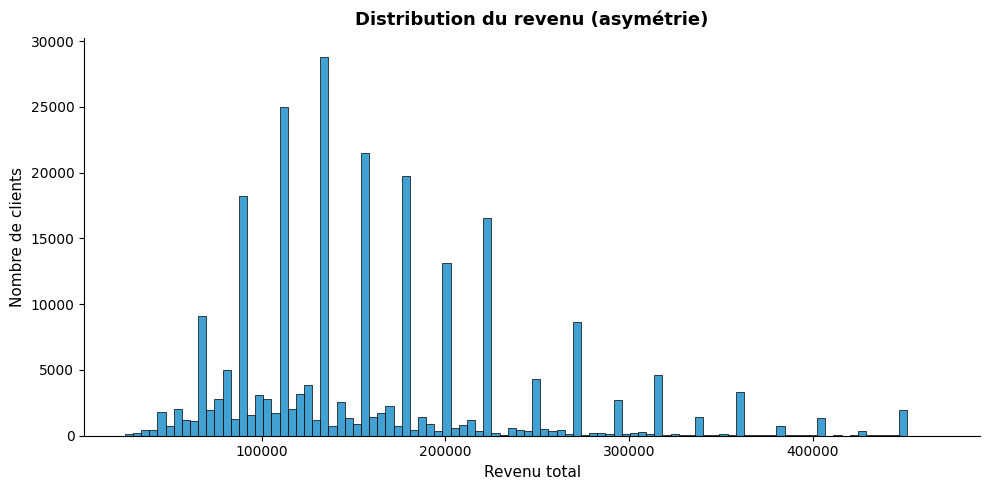

In [120]:
# Visualisation de l'asymétrie : distribution du revenu (limitée pour la lisibilité)
config_asymetrie = [
    {
        "type": "hist",
        "col": "AMT_INCOME_TOTAL",
        "title": "Distribution du revenu (asymétrie)",
        "xlabel": "Revenu total",
        "ylabel": "Nombre de clients",
        "bins": 100,
        "kde": False,
        "colors": "#0082C3",
        "rotation": 0,
    },
]

visualisations(
    X_train[X_train["AMT_INCOME_TOTAL"] < X_train["AMT_INCOME_TOTAL"].quantile(0.99)],
    config_asymetrie,
    ncols=1,
    figsize=(10, 5),
)

**Preuve de la pertinence de la médiane :**

Sur les données complètes, l'écart entre moyenne et médiane reste modéré (la moyenne vaut environ 1,15 fois la médiane pour le revenu). En revanche, l'existence de valeurs extrêmes est manifeste : le revenu maximal (117 000 000) représente 795 fois la médiane (147 150).

Ce sont ces valeurs extrêmes qui justifient l'imputation par la médiane plutôt que par la moyenne. La médiane, valeur centrale de la distribution, n'est pas affectée par ces cas aberrants, alors que la moyenne y est sensible. Imputer une valeur manquante par la médiane attribue donc une valeur représentative du client typique, sans risque de la gonfler à cause de quelques montants exceptionnels.


In [121]:
# Variable de démonstration : un score externe avec des manquants
var_demo = "EXT_SOURCE_3"

# Distribution avant imputation (les manquants sont simplement absents du graphique)
avant = X_train[var_demo].copy()

# Imputation par la médiane, apprise sur le train
imputeur = SimpleImputer(strategy="median")
apres = imputeur.fit_transform(X_train[[var_demo]]).ravel()

print(f"{var_demo} :")
print(f"  Valeurs manquantes avant : {avant.isna().sum():,} ({avant.isna().mean()*100:.1f} %)")
print(f"  Médiane utilisée pour l'imputation : {imputeur.statistics_[0]:.4f}")
print(f"  Valeurs manquantes après : {pd.Series(apres).isna().sum()}")

EXT_SOURCE_3 :
  Valeurs manquantes avant : 48,805 (19.8 %)
  Médiane utilisée pour l'imputation : 0.5353
  Valeurs manquantes après : 0


In [122]:
# Comparaison moyenne / médiane sur les données COMPLÈTES (sans filtrage)
for var in ["AMT_INCOME_TOTAL", "AMT_CREDIT"]:
    moyenne = df_enrichi[var].mean()
    mediane = df_enrichi[var].median()
    maxi = df_enrichi[var].max()
    print(f"{var} :")
    print(f"  Médiane : {mediane:,.0f}")
    print(f"  Moyenne : {moyenne:,.0f}")
    print(f"  Maximum : {maxi:,.0f}")
    print(f"  La moyenne est {moyenne/mediane:.2f} fois la médiane ; le maximum est {maxi/mediane:.0f} fois la médiane\n")

AMT_INCOME_TOTAL :
  Médiane : 147,150
  Moyenne : 168,798
  Maximum : 117,000,000
  La moyenne est 1.15 fois la médiane ; le maximum est 795 fois la médiane

AMT_CREDIT :
  Médiane : 513,531
  Moyenne : 599,026
  Maximum : 4,050,000
  La moyenne est 1.17 fois la médiane ; le maximum est 8 fois la médiane



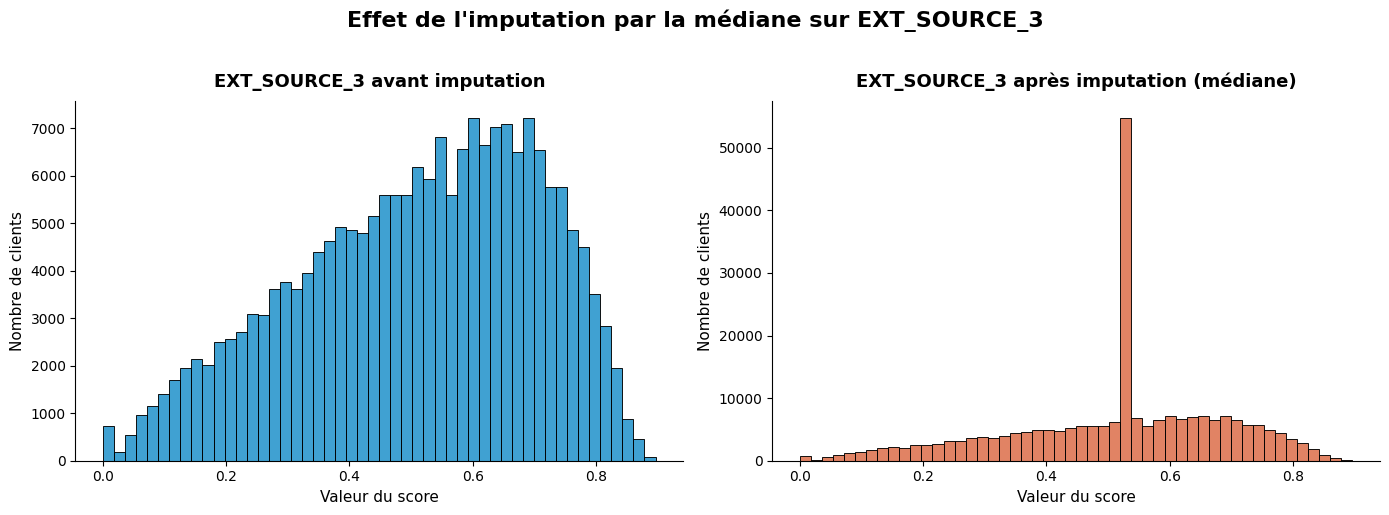

In [123]:
# Comparaison visuelle de la distribution avant et après imputation
# On construit un DataFrame avec les deux versions pour les tracer côte à côte
comparaison = pd.DataFrame({
    "Avant imputation": avant,
    "Après imputation": apres,
})

config_imputation = [
    {
        "type": "hist",
        "col": "Avant imputation",
        "title": "EXT_SOURCE_3 avant imputation",
        "xlabel": "Valeur du score",
        "ylabel": "Nombre de clients",
        "bins": 50,
        "kde": False,
        "colors": "#0082C3",
        "rotation": 0,
    },
    {
        "type": "hist",
        "col": "Après imputation",
        "title": "EXT_SOURCE_3 après imputation (médiane)",
        "xlabel": "Valeur du score",
        "ylabel": "Nombre de clients",
        "bins": 50,
        "kde": False,
        "colors": "#D85A30",
        "rotation": 0,
    },
]

visualisations(
    comparaison,
    config_imputation,
    ncols=2,
    figsize=(14, 5),
    main_title="Effet de l'imputation par la médiane sur EXT_SOURCE_3",
)

**Effet de l'imputation par la médiane :**

La comparaison avant/après imputation de EXT_SOURCE_3 (19,8 % de manquants) met en évidence deux constats :

- **Efficacité** : l'imputation comble l'intégralité des valeurs manquantes (de 48 805 à zéro), et la forme générale de la distribution est préservée.
- **Limite** : les 48 805 valeurs imputées s'empilent toutes à la médiane (0,5353), créant un pic artificiel qui concentre la distribution et réduit légèrement sa variance.

Cet effet de bord est inhérent à toute imputation par une valeur unique. Il reste acceptable pour ce projet, mais il est à connaître : pour une variable prédictive fortement manquante, des méthodes plus sophistiquées (imputation par les plus proches voisins ou par modèle) préserveraient mieux la distribution, au prix d'une complexité accrue. Le choix de la médiane privilégie la simplicité et la robustesse.

### Encodage et standardisation

L'imputation, l'encodage et la standardisation sont regroupés dans un préprocesseur unique (ColumnTransformer), qui applique à chaque groupe de colonnes le traitement adapté :

- les variables numériques où le manquant signifie une absence d'événement sont imputées par zéro, puis standardisées ;
- les variables catégorielles sont imputées par une modalité dédiée, puis encodées en One-Hot ;
- les autres variables numériques (y compris les features métier) sont imputées par la médiane, puis standardisées.

La standardisation (centrage et réduction) est utile pour la régression logistique, sensible à l'échelle des variables. L'encodage One-Hot évite d'introduire un ordre artificiel dans les variables nominales. Toutes ces transformations sont apprises sur le jeu d'entraînement et appliquées au jeu de test, sans fuite.

In [124]:
# Branche 1 : variables "absence d'événement" -> imputation par zéro, puis standardisation
branche_zero = Pipeline([
    ("imputation", SimpleImputer(strategy="constant", fill_value=0)),
    ("standardisation", StandardScaler()),
])

# Branche 2 : variables catégorielles -> imputation par modalité dédiée, puis One-Hot
branche_categorielle = Pipeline([
    ("imputation", SimpleImputer(strategy="constant", fill_value="Non renseigné")),
    ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# Branche 3 : autres variables numériques (dont les ratios du FE) -> médiane, puis standardisation
branche_mediane = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler()),
])

# Préprocesseur : aiguille chaque groupe de colonnes vers sa branche.
# Les colonnes zéro et catégorielles sont affectées explicitement ;
# toutes les autres (remainder), dont les features métier, passent par la branche médiane.
preprocesseur = ColumnTransformer(
    transformers=[
        ("zero", branche_zero, cols_zero),
        ("cat", branche_categorielle, cols_categorielles),
    ],
    remainder=branche_mediane,
)

print("Préprocesseur défini :")
print(f"  Branche zéro : {len(cols_zero)} colonnes")
print(f"  Branche catégorielle : {len(cols_categorielles)} colonnes")
print(f"  Branche médiane : toutes les autres colonnes (via remainder)")

Préprocesseur défini :
  Branche zéro : 142 colonnes
  Branche catégorielle : 11 colonnes
  Branche médiane : toutes les autres colonnes (via remainder)


### Assemblage de la chaîne de préparation

Les étapes de préparation (création des features métier, imputation différenciée, encodage et standardisation) sont réunies dans une chaîne unique, sans modèle à ce stade. Cette chaîne constitue le livrable de l'étape 1 : elle transforme les données brutes en données prêtes pour l'entraînement, sans fuite. Elle sera complétée par un estimateur lors de l'étape de modélisation.

In [125]:
# Chaîne de préparation complète (sans modèle) : features métier puis préprocesseur.
# Cet objet sera réutilisé à l'étape de modélisation, en y ajoutant un estimateur.
from sklearn.pipeline import Pipeline

preparation = Pipeline([
    ("features", ConstructeurFeatures()),
    ("preparation", preprocesseur),
])

print("Chaîne de préparation prête (features + imputation + encodage + standardisation).")
print("Elle sera complétée par un modèle à l'étape de modélisation.")

Chaîne de préparation prête (features + imputation + encodage + standardisation).
Elle sera complétée par un modèle à l'étape de modélisation.


À l'issue de cette étape, le jeu de données est propre, enrichi par les tables secondaires, découpé de façon stratifiée, et une chaîne de préparation sans fuite est prête. Cette chaîne (features métier, imputation différenciée, encodage, standardisation) sera complétée par un modèle lors de l'étape de modélisation.

# Étape 2 : Suivi des expériences avec MLflow

MLflow est une plateforme de suivi du cycle de vie des modèles. Elle enregistre automatiquement, pour chaque entraînement, les paramètres utilisés, les métriques obtenues et le modèle produit. Cet enregistrement systématique assure la traçabilité et la reproductibilité des expériences, et permet de comparer les modèles dans une interface visuelle.

Trois notions structurent son fonctionnement :

- une **expérience** (experiment) regroupe l'ensemble des essais liés à un même objectif ;
- un **run** correspond à un entraînement unique ;
- l'**enregistrement** (logging) consigne les paramètres, les métriques et les artefacts (dont le modèle) de chaque run.

Les données de suivi sont stockées dans le dossier `mlruns/` à la racine du projet.

## Initialisation de MLflow

MLflow enregistre, pour chaque entraînement, les paramètres, les métriques et le modèle produit. Les essais sont regroupés dans une expérience et stockés dans le dossier mlruns à la racine du projet.

In [126]:
# Emplacement de stockage des runs
mlflow.set_tracking_uri(f"file://{PROJECT_ROOT / 'mlruns'}")

# Expérience regroupant tous les essais du projet
mlflow.set_experiment("credit_scoring")

print("MLflow initialisé.")

/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/mlflow/tracking/_tracking_service/utils.py:184: FutureWarning: The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri, store_uri)
2026/07/18 09:13:27 INFO mlflow.tracking.fluent: Experiment with name 'credit_scoring' does not exist. Creating a new experiment.


MLflow initialisé.


## Choix des métriques d'évaluation et validation croisée

Le jeu de données est fortement déséquilibré (8,07 % de défauts). L'exactitude (accuracy) est donc inadaptée : un modèle prédisant l'absence de défaut pour tous les clients atteindrait près de 92 % sans aucune valeur prédictive. Trois métriques complémentaires, adaptées au déséquilibre, sont retenues.

### AUC-ROC (aire sous la courbe ROC)
Mesure la capacité du modèle à ordonner correctement les clients selon leur risque : la probabilité qu'un client défaillant reçoive un score plus élevé qu'un client non défaillant. Une valeur de 0,5 correspond au hasard, 1,0 à un classement parfait.

Intérêt : indépendante du seuil de décision et peu sensible au déséquilibre, elle constitue la métrique de référence pour comparer les modèles entre eux. C'est également la métrique officielle du concours Home Credit.

### AP (Average Precision, aire sous la courbe précision-rappel)

Évalue la performance du modèle sur la classe positive (les défauts), rare et coûteuse. Elle résume le compromis entre précision et rappel sur l'ensemble des seuils.

Intérêt : plus exigeante que l'AUC sur les données déséquilibrées, elle reflète plus fidèlement la capacité à identifier les défauts sans multiplier les fausses alertes.

### F-bêta

Combine la précision (part de vrais défauts parmi les clients prédits à risque) et le rappel (part de défauts détectés parmi les vrais défaillants). Le paramètre bêta pondère l'importance relative des deux : une valeur supérieure à 1 (par exemple F2) privilégie le rappel.

Intérêt : en scoring de crédit, un faux négatif (accorder un crédit à un futur défaillant) coûte davantage qu'un faux positif (refuser un bon client). Le F-bêta relie ainsi la performance technique à l'enjeu métier et prépare l'optimisation du seuil de décision.

### Synthèse

Les trois métriques se complètent : l'AUC pour comparer les modèles globalement, l'AP pour la performance sur la classe rare, et le F-bêta pour le lien avec la décision métier. Aucune n'est faussée par le déséquilibre des classes.

In [127]:
# Validation croisée stratifiée : 5 plis préservant la proportion de défauts
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state = RANDOM_STATE)

# Les trois métriques retenues
scoring = {
    "AUC": make_scorer(roc_auc_score, response_method="predict_proba"),
    "AP": make_scorer(average_precision_score, response_method="predict_proba"),
    "F2": make_scorer(fbeta_score, beta=2),
}

print("Validation croisée et métriques définies.")

Validation croisée et métriques définies.


## Enregistrement des runs

Chaque entraînement est encadré par un run MLflow, qui enregistre les paramètres, les métriques (moyennes de la validation croisée) et le modèle entraîné.

In [128]:
# Pipeline complet : préparation (déjà assemblée) + modèle
pipeline_lr = Pipeline([
    ("preparation", preparation),   # chaîne assemblée à la fin de l'étape 1
    ("modele", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])

with mlflow.start_run(run_name="regression_logistique"):
    mlflow.log_param("modele", "LogisticRegression")
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("jeu_donnees", "enrichi")

    resultats = cross_validate(pipeline_lr, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    mlflow.log_metric("AUC", resultats["test_AUC"].mean())
    mlflow.log_metric("AP", resultats["test_AP"].mean())
    mlflow.log_metric("F2", resultats["test_F2"].mean())

    pipeline_lr.fit(X_train, y_train)
    mlflow.sklearn.log_model(pipeline_lr, name="modele")

    print("Run enregistré : regression_logistique")
    for nom in scoring:
        print(f"{nom} : {resultats[f'test_{nom}'].mean():.4f}")

2026/07/18 09:13:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/07/18 09:13:56 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Run enregistré : regression_logistique
AUC : 0.7663
AP : 0.2422
F2 : 0.4309


**Performance de la régression logistique :**

La régression logistique, entraînée sur le jeu enrichi et évaluée par validation croisée stratifiée, obtient les résultats suivants :

| Métrique | Valeur |
|---|---|
| AUC | 0,7663 |
| AP | 0,2422 |
| F2 | 0,4309 |

Avec une AUC de 0,77, le modèle discrimine correctement les profils risqués des profils sains. L'AP de 0,24, à comparer à la valeur de référence du hasard (0,08, soit le taux de défaut), confirme un apport réel par rapport à une classification aléatoire. Ces valeurs constituent le point de référence pour la co

## Annotation des runs

In [129]:
# Exemple de run richement annoté : tags et description pour la traçabilité
with mlflow.start_run(run_name="regression_logistique_enrichi") as run:
    # Tags : étiquettes de contexte, utiles pour filtrer et comprendre les runs
    mlflow.set_tag("jeu_donnees", "enrichi_6_tables")
    mlflow.set_tag("type_modele", "lineaire")
    mlflow.set_tag("desequilibre", "class_weight_balanced")
    mlflow.set_tag("etape_projet", "baseline_enrichi")

    # Description libre du run (note de contexte)
    mlflow.set_tag("mlflow.note.content",
                   "Régression logistique sur le jeu enrichi par agrégation des six tables "
                   "secondaires. Déséquilibre géré par pondération des classes.")

    # Paramètres
    mlflow.log_param("modele", "LogisticRegression")
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("nb_features", X_train.shape[1])

    # Métriques (réutilisation des résultats déjà calculés)
    mlflow.log_metric("AUC", resultats["test_AUC"].mean())
    mlflow.log_metric("AP", resultats["test_AP"].mean())
    mlflow.log_metric("F2", resultats["test_F2"].mean())

    # Modèle
    mlflow.sklearn.log_model(pipeline_lr, name="modele")

    # On récupère l'identifiant du run, utile pour le model registry juste après
    run_id_lr = run.info.run_id

    print("Run annoté enregistré.")
    print(f"Identifiant du run : {run_id_lr}")

2026/07/18 09:13:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/07/18 09:13:57 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Run annoté enregistré.
Identifiant du run : adc16422506a44b9be321e7e61b16f00


## Enregistrement d'un modèle dans le model registry
Le model registry est le registre centralisé des modèles de MLflow. Contrairement au simple enregistrement d'un modèle dans un run, le registry référence le modèle sous un nom unique et lui attribue une version. Il permet de gérer le cycle de vie des modèles (versions successives, étapes de validation et de production) et d'assurer leur traçabilité. C'est un élément clé de la reproductibilité et de la gestion des modèles en MLOps.

In [130]:
# Enregistrement du modèle dans le model registry, sous un nom versionné.
# On référence le modèle du run annoté (via son identifiant) dans le registre.

nom_modele_registry = "credit_scoring_logistique"

# L'URI pointe vers le modèle enregistré dans le run (sous-dossier "modele")
uri_modele = f"runs:/{run_id_lr}/modele"

# Enregistrement dans le registry : crée le modèle s'il n'existe pas, sinon ajoute une version
version = mlflow.register_model(model_uri=uri_modele, name=nom_modele_registry)

print(f"Modèle enregistré dans le registry.")
print(f"Nom : {version.name}")
print(f"Version : {version.version}")

/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/mlflow/tracking/_model_registry/utils.py:220: FutureWarning: The filesystem model registry backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri)
Successfully registered model 'credit_scoring_logistique'.
2026/07/18 09:13:57 WARNING mlflow.tracking._model_registry.fluent: Run with id adc16422506a44b9be321e7e61b16f00 has no artifacts at artifact path 'modele', registering model based on models:/m-60e7e4573fb749bb8e3c02102a100735 instead


Modèle enregistré dans le registry.
Nom : credit_scoring_logistique
Version : 1


Created version '1' of model 'credit_scoring_logistique'.


À l'issue de cette étape, le suivi des expériences est pleinement opérationnel : MLflow est initialisé, les runs sont enregistrés avec leurs paramètres, métriques et modèles, annotés par des tags et des descriptions, et un modèle est référencé dans le model registry sous une version. L'ensemble est consultable et comparable dans l'interface MLflow.

## Enregistrement automatique avec autolog

MLflow propose un enregistrement automatique via mlflow.autolog(). Une fois activé, il capte sans code explicite les hyperparamètres, les métriques et le modèle lors de l'entraînement. Cette approche complète le logging manuel : elle est plus rapide à mettre en place, au prix d'un contrôle moindre sur ce qui est enregistré. Le logging manuel reste préférable lorsque l'on souhaite consigner des métriques précises (ici AUC, AP, F2 issues de la validation croisée), tandis que autolog convient à une capture rapide et exhaustive des paramètres du modèle.

In [131]:
# Activation de l'enregistrement automatique pour scikit-learn
mlflow.sklearn.autolog()

# Avec autolog actif, un simple fit dans un run enregistre automatiquement
# les hyperparamètres et le modèle, sans log_param ni log_model explicites.
with mlflow.start_run(run_name="demonstration_autolog"):
    mlflow.set_tag("demonstration", "autolog")
    pipeline_lr.fit(X_train, y_train)
    print("Run autolog enregistré : hyperparamètres et modèle capturés automatiquement.")

# Désactivation de l'autolog pour revenir au logging manuel ensuite
mlflow.sklearn.autolog(disable=True)
print("Autolog désactivé : retour au logging manuel pour la suite.")

2026/07/18 09:14:03 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2026/07/18 09:14:10 WARNING mlflow.utils.autologging_utils: MLflow

Run autolog enregistré : hyperparamètres et modèle capturés automatiquement.
Autolog désactivé : retour au logging manuel pour la suite.


À l'issue de cette étape, le suivi des expériences est pleinement opérationnel. MLflow est initialisé dans un environnement isolé, les runs sont enregistrés avec leurs paramètres, métriques et modèles, annotés par des tags et des descriptions. Les deux modes de suivi ont été mis en oeuvre : le logging manuel, précis sur les métriques retenues (AUC, AP, F2), et l'enregistrement automatique (autolog), exhaustif sur les hyperparamètres. Enfin, un modèle est référencé et versionné dans le model registry. L'ensemble est consultable et comparable dans l'interface MLflow.

# Étape 3 : Modélisation avec plusieurs modèles 

Cette étape entraîne et compare plusieurs modèles de classification sur le jeu enrichi, évalués par validation croisée stratifiée sur les trois métriques retenues (AUC, AP, F2). Plusieurs familles sont testées, du modèle linéaire simple aux modèles d'ensemble. Le déséquilibre des classes est traité, d'abord par pondération puis par rééchantillonnage. Enfin, l'importance des variables est analysée pour comprendre les déterminants du risque.

## Choix des métriques adaptées : AUC, AP, F2

In [132]:
# Test de sensibilité : estimation du ratio de coût FN/FP selon l'hypothèse de taux d'intérêt.
#
# Faute de taux d'intérêt fiable dans les données (variable dédiée manquante à 99,6 %),
# le coût d'un faux positif (intérêts gagnés sur un crédit sain) ne peut être estimé qu'en
# posant une hypothèse de taux. On teste plusieurs taux pour mesurer la sensibilité du beta.

credits_defaut = df_enrichi[df_enrichi["TARGET"] == 1]
credits_sains  = df_enrichi[df_enrichi["TARGET"] == 0]

# Coût d'un faux négatif : capital moyen exposé sur un crédit en défaut
cout_fn = credits_defaut["AMT_CREDIT"].mean()

# Montants moyens d'un crédit sain
capital_sain_moyen = credits_sains["AMT_CREDIT"].mean()
annuite_sain_moyen = credits_sains["AMT_ANNUITY"].mean()

# Durée du crédit en années (capital / annuité annuelle)
duree_annees = capital_sain_moyen / annuite_sain_moyen

print(f"Coût d'un faux négatif (capital exposé) : {cout_fn:,.0f}")
print(f"Durée moyenne d'un crédit (années) : {duree_annees:.1f}\n")
print(f"{'Taux annuel':>12} | {'Coût FP (intérêts)':>20} | {'Ratio FN/FP':>12} | {'Beta':>6}")
print("-" * 60)

# Test de plusieurs hypothèses de taux d'intérêt
for taux in [0.05, 0.10, 0.15, 0.20]:
    cout_fp = capital_sain_moyen * taux * duree_annees
    ratio = cout_fn / cout_fp
    beta = ratio ** 0.5 if ratio > 0 else float("nan")
    print(f"{taux*100:>10.0f} % | {cout_fp:>20,.0f} | {ratio:>12.2f} | {beta:>6.2f}")

Coût d'un faux négatif (capital exposé) : 557,779
Durée moyenne d'un crédit (années) : 22.2

 Taux annuel |   Coût FP (intérêts) |  Ratio FN/FP |   Beta
------------------------------------------------------------
         5 % |              668,513 |         0.83 |   0.91
        10 % |            1,337,027 |         0.42 |   0.65
        15 % |            2,005,540 |         0.28 |   0.53
        20 % |            2,674,054 |         0.21 |   0.46


**Résultat du test de sensibilité :**

Le tableau montre que le beta estimé varie fortement selon l'hypothèse de taux d'intérêt : de 0,91 (taux de 5 %) à 0,46 (taux de 20 %). Cette forte sensibilité à une hypothèse non vérifiable confirme que l'estimation empirique n'est pas fiable.

Plus révélateur encore, tous les beta obtenus sont inférieurs à 1, ce qui contredit le raisonnement métier (le faux négatif coûtant plus cher que le faux positif, beta devrait être supérieur à 1). Cette incohérence provient d'un second artefact : la durée moyenne de 22 ans, déduite du rapport capital sur annuité, surestime fortement les intérêts cumulés et donc le coût du faux positif. Une telle durée n'est pas réaliste pour ce type de crédit.

L'estimation cumule ainsi deux sources d'incertitude (taux d'intérêt inconnu et durée artificielle), ce qui la rend non concluante. Le choix du beta repose donc sur un raisonnement métier qualitatif, et non sur cette estimation.

#### Le besoin d'une métrique adaptée au coût métier

Dans le scoring de crédit, les deux types d'erreurs n'ont pas le même coût. Un faux négatif (accorder un crédit à un client qui fera défaut) entraîne la perte du capital exposé. Un faux positif (refuser un bon client) entraîne un manque à gagner, limité aux intérêts non perçus. Le faux négatif est donc plus coûteux que le faux positif, ce qui impose une métrique privilégiant le rappel (la détection des défauts) plutôt que la seule précision.

Le score F-beta répond à ce besoin : le paramètre beta règle l'importance du rappel par rapport à la précision. Le lien avec le coût métier est direct : beta au carré correspond au rapport entre le coût d'un faux négatif et celui d'un faux positif. Déterminer beta de façon rigoureuse revient donc à estimer ce rapport de coût.

#### Ce que l'on cherchait à estimer

L'estimation idéale consisterait à observer, sur les données historiques, le coût réel de chaque type d'erreur :
- pour les faux négatifs : le montant effectivement perdu sur les crédits accordés à des clients ayant fait défaut ;
- pour les faux positifs : le gain auquel on a renoncé en refusant des clients qui se seraient révélés sains.

Le premier coût est partiellement observable, puisque le jeu de données contient les crédits accordés et leur issue (la variable cible indique le défaut). Le second ne l'est pas.

#### L'absence des refus : un biais de sélection

Le coût d'un faux positif supposerait de connaître le devenir des clients refusés : auraient-ils remboursé, ou fait défaut ? Cette information n'existe pas dans les données. La table principale ne contient que des crédits accordés, dont on connaît l'issue. Les demandes refusées, lorsqu'elles apparaissent (dans l'historique des demandes antérieures via le statut du contrat), n'ont pas d'issue connue : puisque le crédit n'a pas été accordé, on ignore si le client aurait remboursé.

Cette situation correspond à un biais de sélection : l'issue (défaut ou remboursement) n'est observée que pour la population sélectionnée (les crédits accordés), jamais pour les refusés. Il est donc impossible d'estimer empiriquement le coût d'un refus injustifié, et par conséquent le rapport de coût exact.

#### Tentative d'estimation alternative et son échec

Faute de pouvoir observer le coût des refus, une estimation alternative a été tentée, en approchant le coût d'un faux positif par les intérêts qu'aurait rapportés un crédit sain. Le coût d'un faux négatif a été approché par le capital moyen des crédits ayant fait défaut (environ 557 800).

Cette approche s'est révélée non fiable, pour deux raisons cumulées. D'une part, le calcul des intérêts nécessite un taux d'intérêt, absent du jeu de données (la variable dédiée est manquante à 99,6 %). D'autre part, la durée de crédit, reconstituée à partir du rapport capital sur annuité, est artificielle et irréaliste (environ 22 ans). Le test de sensibilité confirme cette instabilité : selon le taux supposé, le beta estimé varie fortement et reste systématiquement inférieur à 1, ce qui contredit le raisonnement métier (le faux négatif coûtant plus cher, beta devrait être supérieur à 1).

#### Choix retenu : le score F2

En l'absence d'une estimation empirique fiable, le choix repose sur un raisonnement métier qualitatif, robuste et indépendant des hypothèses instables : le coût d'un faux négatif (perte du capital) dépasse clairement celui d'un faux positif (manque à gagner sur les intérêts). Le paramètre beta doit donc être supérieur à 1.

Le score F2 (beta = 2) est retenu. Il correspond à un rapport de coût implicite de 4, hypothèse prudente et usuelle dans le domaine du crédit : le rappel y pèse quatre fois plus que la précision, ce qui pénalise nettement les faux négatifs sans dégrader excessivement la précision (ce que produirait un beta très élevé).

Ce choix sera affiné à l'étape 4, où une fonction de coût métier explicite et l'optimisation du seuil de décision permettront de traiter directement l'arbitrage entre les deux types d'erreurs, sans dépendre de l'estimation des intérêts.

#### Les trois métriques suivies et leur justification

Trois métriques complémentaires sont suivies, car aucune ne suffit à elle seule. Le F2 dépend du seuil de décision, ce qui peut le rendre trompeur si le seuil n'est pas optimal. Il est donc complété par deux métriques indépendantes du seuil, qui évaluent la qualité intrinsèque du modèle.

**AUC (aire sous la courbe ROC).** Elle mesure la capacité de discrimination du modèle : la probabilité qu'un client défaillant reçoive un score de risque plus élevé qu'un client sain. Indépendante du seuil, elle évalue si le modèle ordonne correctement les clients du moins au plus risqué, ce qui est l'essence du scoring. Sa limite : sur des données fortement déséquilibrées, elle peut être optimiste, car dominée par la classe majoritaire.

**AP (average precision).** Aire sous la courbe précision-rappel, elle est mieux adaptée aux classes déséquilibrées car elle se concentre sur la classe minoritaire (les défauts). Son point de référence est le taux de défaut lui-même (0,08) : un modèle aléatoire obtiendrait une AP de 0,08. Une AP nettement supérieure traduit donc un apport réel dans la détection des défauts. C'est la métrique la plus réaliste pour ce problème déséquilibré.

**F2 (score F-beta avec beta = 2).** Métrique principale orientée métier, elle privilégie le rappel sur la précision, conformément à l'arbitrage de coût. Dépendant du seuil de décision, elle s'interprète conjointement avec celui-ci, dont l'optimisation est traitée à l'étape 4.

Ensemble, ces trois métriques offrent une vue complète : la discrimination globale (AUC), la performance sur la classe rare (AP) et l'arbitrage métier (F2).

***Le F2 est utilisé ici comme métrique de comparaison, pour départager les familles de modèles à cette étape de sélection. Il ne s'agit pas de la métrique de décision finale : celle-ci, le F-bêta calé sur l'hypothèse métier, est introduite à l'étape 4, une fois le modèle retenu.***

## Validation croisée stratifiée

Les modèles sont évalués par validation croisée stratifiée à 5 plis. Le jeu d'entraînement est découpé en cinq parts ; chaque modèle est entraîné sur quatre parts et évalué sur la cinquième, l'opération étant répétée cinq fois. Les métriques rapportées sont les moyennes sur les cinq plis, ce qui fournit une estimation plus robuste qu'un découpage unique. La stratification préserve la proportion de défauts (8,07 %) dans chaque pli, condition indispensable compte tenu du fort déséquilibre des classes.

## Modèles testés : régression logistique, LightGBM,  Random Forest, XGBoost et MLP

In [133]:
# Ratio de déséquilibre pour XGBoost (scale_pos_weight au lieu de class_weight)
ratio_desequilibre = (y_train == 0).sum() / (y_train == 1).sum()

# Modèles testés, des plus simples aux plus puissants (ordre recommandé par l'énoncé).
# Le déséquilibre est géré par pondération des classes là où le modèle le permet.
# Le MLP de scikit-learn ne dispose pas de class_weight : sa gestion du déséquilibre
# sera traitée par SMOTE dans la seconde passe.
modeles = {
    "regression_logistique": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "random_forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "lightgbm": LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    "xgboost": XGBClassifier(n_estimators=300, scale_pos_weight=ratio_desequilibre, random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss"),
    "mlp": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=RANDOM_STATE),
}

# Entraînement et évaluation en validation croisée stratifiée, tracés dans MLflow
resultats_modeles = {}

for nom, modele in modeles.items():
    pipeline = Pipeline([
        ("preparation", preparation),
        ("modele", modele),
    ])
    with mlflow.start_run(run_name=nom):
        mlflow.log_param("modele", type(modele).__name__)
        mlflow.log_param("desequilibre", "class_weight" if nom != "mlp" else "aucun")
        mlflow.log_param("nb_features", X_train.shape[1])

        res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

        mlflow.log_metric("AUC", res["test_AUC"].mean())
        mlflow.log_metric("AP",  res["test_AP"].mean())
        mlflow.log_metric("F2",  res["test_F2"].mean())

        resultats_modeles[nom] = {
            "AUC": res["test_AUC"].mean(),
            "AP": res["test_AP"].mean(),
            "F2": res["test_F2"].mean(),
        }
        print(f"{nom:25s} | AUC {res['test_AUC'].mean():.4f} | AP {res['test_AP'].mean():.4f} | F2 {res['test_F2'].mean():.4f}")
print("\nCinq familles de modèles évaluées et tracées dans MLflow.")

regression_logistique     | AUC 0.7663 | AP 0.2422 | F2 0.4309
random_forest             | AUC 0.7517 | AP 0.2215 | F2 0.0022


/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/ut

lightgbm                  | AUC 0.7808 | AP 0.2707 | F2 0.4454
xgboost                   | AUC 0.7428 | AP 0.2335 | F2 0.3720
mlp                       | AUC 0.7611 | AP 0.2390 | F2 0.0289

Cinq familles de modèles évaluées et tracées dans MLflow.


## Traitement du déséquilibre par SMOTE

Le déséquilibre des classes a d'abord été traité par pondération (class_weight). Une seconde approche est testée : le rééchantillonnage par SMOTE (Synthetic Minority Over-sampling Technique), qui génère des exemples synthétiques de la classe minoritaire (les défauts) pour rééquilibrer le jeu d'entraînement. SMOTE ne doit être appliqué qu'aux données d'entraînement, jamais au jeu de test ni aux plis de validation : il est donc intégré au Pipeline pour garantir cette règle à chaque pli de la validation croisée.

In [134]:
# Test de SMOTE sur les cinq familles de modèles, pour comparer systématiquement
# le rééchantillonnage à la pondération des classes.
# On retire class_weight et scale_pos_weight : SMOTE remplace la pondération, ne s'y ajoute pas.
# SMOTE est intégré au Pipeline pour n'agir que sur l'entraînement de chaque pli.

modeles_smote = {
    "regression_logistique_smote": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "random_forest_smote": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "lightgbm_smote": LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    "xgboost_smote": XGBClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss"),
    "mlp_smote": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=RANDOM_STATE),
}

for nom, modele in modeles_smote.items():
    pipeline = ImbPipeline([
        ("features", ConstructeurFeatures()),
        ("preparation", preprocesseur),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("modele", modele),
    ])

    with mlflow.start_run(run_name=nom):
        mlflow.log_param("modele", type(modele).__name__)
        mlflow.log_param("desequilibre", "SMOTE")
        mlflow.log_param("nb_features", X_train.shape[1])

        res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

        mlflow.log_metric("AUC", res["test_AUC"].mean())
        mlflow.log_metric("AP", res["test_AP"].mean())
        mlflow.log_metric("F2", res["test_F2"].mean())

        resultats_modeles[nom] = {
            "AUC": res["test_AUC"].mean(),
            "AP": res["test_AP"].mean(),
            "F2": res["test_F2"].mean(),
        }
        print(f"{nom:28s} | AUC {res['test_AUC'].mean():.4f} | AP {res['test_AP'].mean():.4f} | F2 {res['test_F2'].mean():.4f}")

print("\nTest SMOTE terminé pour les cinq modèles.")

regression_logistique_smote  | AUC 0.7580 | AP 0.2358 | F2 0.4228
random_forest_smote          | AUC 0.7379 | AP 0.2079 | F2 0.0057


/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/ut

lightgbm_smote               | AUC 0.7690 | AP 0.2484 | F2 0.0272
xgboost_smote                | AUC 0.7563 | AP 0.2351 | F2 0.0907
mlp_smote                    | AUC 0.6653 | AP 0.1480 | F2 0.2237

Test SMOTE terminé pour les cinq modèles.


In [135]:
# Tableau comparatif de tous les modèles testés, trié par AUC décroissante
tableau = pd.DataFrame(resultats_modeles).T
tableau = tableau.sort_values("AUC", ascending=False).round(4)
print(tableau.to_string())

                                AUC      AP      F2
lightgbm                     0.7808  0.2707  0.4454
lightgbm_smote               0.7690  0.2484  0.0272
regression_logistique        0.7663  0.2422  0.4309
mlp                          0.7611  0.2390  0.0289
regression_logistique_smote  0.7580  0.2358  0.4228
xgboost_smote                0.7563  0.2351  0.0907
random_forest                0.7517  0.2215  0.0022
xgboost                      0.7428  0.2335  0.3720
random_forest_smote          0.7379  0.2079  0.0057
mlp_smote                    0.6653  0.1480  0.2237


In [136]:
tableau

,AUC,AP,F2
lightgbm,0.7808,0.2707,0.4454
lightgbm_smote,0.7690,0.2484,0.0272
regression_logistique,0.7663,0.2422,0.4309
mlp,0.7611,0.2390,0.0289
regression_logistique_smote,0.7580,0.2358,0.4228
xgboost_smote,0.7563,0.2351,0.0907
random_forest,0.7517,0.2215,0.0022
xgboost,0.7428,0.2335,0.3720
random_forest_smote,0.7379,0.2079,0.0057
mlp_smote,0.6653,0.1480,0.2237


### Synthèse finale de la comparaison des modèles

Dix configurations ont été comparées en validation croisée stratifiée : cinq familles de modèles, chacune avec deux stratégies de gestion du déséquilibre (pondération des classes et SMOTE).

| Modèle | Déséquilibre | AUC | AP | F2 |
|---|---|---|---|---|
| LightGBM | pondération | 0,7808 | 0,2707 | 0,4454 |
| LightGBM | SMOTE | 0,7690 | 0,2484 | 0,0272 |
| Régression logistique | pondération | 0,7663 | 0,2422 | 0,4309 |
| MLP | aucune | 0,7611 | 0,2390 | 0,0289 |
| Régression logistique | SMOTE | 0,7580 | 0,2358 | 0,4228 |
| XGBoost | SMOTE | 0,7563 | 0,2351 | 0,0907 |
| Random Forest | pondération | 0,7517 | 0,2215 | 0,0022 |
| XGBoost | pondération | 0,7428 | 0,2335 | 0,3720 |
| Random Forest | SMOTE | 0,7379 | 0,2079 | 0,0057 |
| MLP | SMOTE | 0,6653 | 0,1480 | 0,2237 |

Conclusions :
- LightGBM avec pondération obtient les meilleures performances sur les trois métriques et constitue le modèle retenu sans ambiguïté.
- SMOTE n'améliore pas les performances : pour chaque modèle, le rééchantillonnage donne un résultat équivalent ou inférieur à la pondération (seul XGBoost progresse légèrement, sans atteindre LightGBM). La pondération des classes est donc l'approche retenue.
- Les écarts importants sur le F2 résultent du seuil de décision par défaut (0,5), inadapté selon les configurations. L'AUC et l'AP, indépendantes du seuil, restent les comparateurs fiables et confirment le choix de LightGBM.

Le modèle retenu est LightGBM avec pondération des classes. Il fera l'objet de l'optimisation des hyperparamètres et du seuil de décision à l'étape 4.

## Analyse de l'importance des variables

In [137]:
# Analyse de l'importance des variables sur le modèle retenu (LightGBM avec pondération).
# On réentraîne le pipeline complet sur tout le jeu d'entraînement, puis on extrait
# l'importance des variables du modèle LightGBM final.

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

# Pipeline du modèle retenu
pipeline_final = Pipeline([
    ("preparation", preparation),
    ("modele", LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)),
])

# Entraînement sur l'ensemble du jeu d'entraînement
pipeline_final.fit(X_train, y_train)

# Récupération des noms des variables après transformation par le préprocesseur
# (le One-Hot encoding crée de nouvelles colonnes pour les catégorielles)
noms_features = pipeline_final.named_steps["preparation"].named_steps["preparation"].get_feature_names_out()

# Importance des variables du modèle LightGBM
importances = pipeline_final.named_steps["modele"].feature_importances_

# Tableau trié par importance décroissante
importance_df = pd.DataFrame({
    "variable": noms_features,
    "importance": importances,
}).sort_values("importance", ascending=False).reset_index(drop=True)

print(f"Nombre total de variables (après encodage) : {len(importance_df)}\n")
print("Les 20 variables les plus importantes :")
print(importance_df.head(20).to_string(index=False))

Nombre total de variables (après encodage) : 314

Les 20 variables les plus importantes :
                                    variable  importance
             remainder__RATIO_ANNUITE_CREDIT         164
                     remainder__EXT_SOURCE_1         141
                     remainder__EXT_SOURCE_2         127
                     remainder__EXT_SOURCE_3          96
             zero__INSTAL_AMT_INSTALMENT_SUM          66
            zero__INSTAL_RETARD_PAIEMENT_MAX          56
            zero__INSTAL_ECART_PAIEMENT_MEAN          56
        zero__BUREAU_DAYS_CREDIT_ENDDATE_MAX          55
                       remainder__DAYS_BIRTH          53
                 zero__PREV_CNT_PAYMENT_MEAN          53
                zero__POS_CNT_INSTALMENT_MAX          48
                      remainder__AMT_ANNUITY          48
                  remainder__DAYS_ID_PUBLISH          46
                       remainder__AGE_ANNEES          45
             remainder__RATIO_ANNUITE_REVENU          4

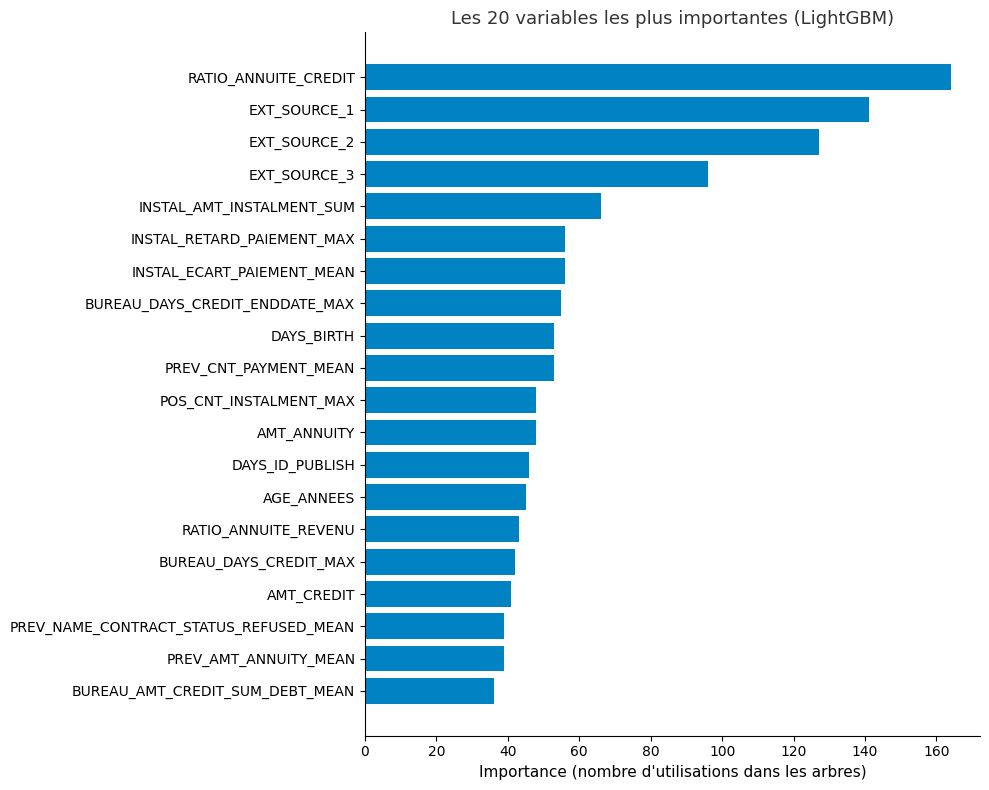

In [138]:
# Visualisation des 20 variables les plus importantes du modèle LightGBM.
# Barres horizontales, triées pour une lecture immédiate des variables dominantes.

top20 = importance_df.head(20).sort_values("importance")  # tri croissant pour l'affichage

# Nettoyage des noms : on retire les préfixes techniques (remainder__, zero__, cat__)
# pour une lecture plus claire des noms de variables.
noms_propres = (top20["variable"]
                .str.replace("remainder__", "", regex=False)
                .str.replace("zero__", "", regex=False)
                .str.replace("cat__", "", regex=False))

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(noms_propres, top20["importance"], color="#0082C3")
ax.set_xlabel("Importance (nombre d'utilisations dans les arbres)", fontsize=11)
ax.set_title("Les 20 variables les plus importantes (LightGBM)", fontsize=13, color="#333333")

# Épuration du graphique : on retire les bordures superflues
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

L'importance des variables du modèle retenu (LightGBM) est analysée pour identifier les déterminants du risque de défaut. Après encodage, le modèle exploite 314 variables. Les vingt plus importantes confirment la pertinence de la démarche :

- **Les features métier dominent.** Le ratio annuité sur crédit est la variable la plus importante, et le taux d'effort (annuité sur revenu) figure également dans les premières positions. Cela valide la construction de ces indicateurs dérivés.
- **Les scores externes** (EXT_SOURCE_1, 2 et 3) occupent les positions suivantes, confirmant leur fort pouvoir prédictif déjà identifié à l'exploration.
- **L'enrichissement par les tables secondaires apporte un signal réel.** Plusieurs agrégats figurent parmi les plus importants : le pire retard de paiement passé (INSTAL_RETARD_PAIEMENT_MAX), l'écart de paiement moyen, la proportion de demandes antérieures refusées (PREV_NAME_CONTRACT_STATUS_REFUSED_MEAN) et la dette externe moyenne. Ces variables, issues du comportement historique du client, valident les choix d'agrégation sur mesure.

L'importance des variables confirme ainsi la cohérence de l'ensemble de la démarche : les variables construites (ratios métier, features de retard) et les variables enrichies (agrégats des tables secondaires) contribuent significativement aux prédictions, aux côtés des scores externes.

/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


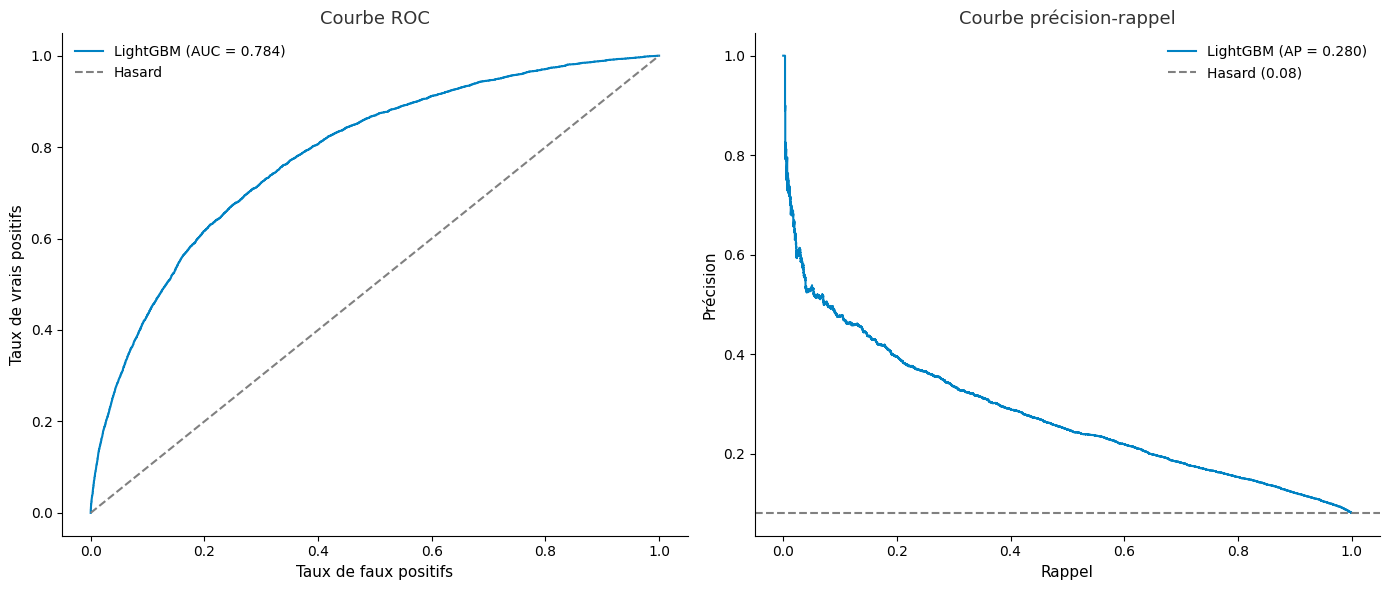

In [139]:
# Courbes ROC et précision-rappel du modèle retenu (LightGBM), sur le jeu de test.
# Le modèle pipeline_final a déjà été entraîné sur X_train lors de l'analyse d'importance.

# Probabilités prédites sur le jeu de test
proba_test = pipeline_final.predict_proba(X_test)[:, 1]

# Courbe ROC
fpr, tpr, _ = roc_curve(y_test, proba_test)
auc_test = auc(fpr, tpr)

# Courbe précision-rappel
precision, recall, _ = precision_recall_curve(y_test, proba_test)
ap_test = average_precision_score(y_test, proba_test)
taux_defaut = y_test.mean()

# Affichage côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Courbe ROC
axes[0].plot(fpr, tpr, color="#0082C3", label=f"LightGBM (AUC = {auc_test:.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Hasard")
axes[0].set_xlabel("Taux de faux positifs",  fontsize=11)
axes[0].set_ylabel("Taux de vrais positifs", fontsize=11)
axes[0].set_title("Courbe ROC", fontsize=13, color="#333333")
axes[0].legend(frameon=False)

# Courbe précision-rappel
axes[1].plot(recall, precision, color="#0082C3", label=f"LightGBM (AP = {ap_test:.3f})")
axes[1].axhline(y=taux_defaut, color="grey", linestyle="--", label=f"Hasard ({taux_defaut:.2f})")
axes[1].set_xlabel("Rappel", fontsize=11)
axes[1].set_ylabel("Précision", fontsize=11)
axes[1].set_title("Courbe précision-rappel", fontsize=13, color="#333333")
axes[1].legend(frameon=False)

for ax in axes:
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

**Courbes d'évaluation du modèle retenu :**

Les courbes ROC et précision-rappel sont tracées sur le jeu de test, jamais utilisé pour l'entraînement.

La courbe ROC affiche une AUC de 0,784 sur le jeu de test, quasi identique à celle obtenue en validation croisée (0,781). Cette concordance confirme la bonne capacité de généralisation du modèle, sans surapprentissage.

La courbe précision-rappel affiche une AP de 0,280, nettement supérieure au niveau du hasard (0,08, soit le taux de défaut). Sa forme illustre le compromis central du problème : augmenter le rappel (détecter davantage de défauts) réduit la précision (génère davantage de fausses alertes). Cet arbitrage sera traité explicitement à l'étape suivante, par l'optimisation du seuil de décision selon le coût métier.

# Étape 4 : Optimisation des hyperparamètres et du seuil métier
Cette étape vise à maximiser le F-bêta, une métrique qui privilégie la détection des défauts, l'erreur la plus coûteuse. Elle comprend le choix de la métrique et du bêta, l'optimisation des hyperparamètres du modèle retenu, puis la recherche du seuil de décision qui maximise le F-bêta.

## Choix de la métrique : le F-bêta plutôt qu'une fonction de coût métier explicite

La qualité d'un modèle de scoring de crédit dépend du bon arbitrage entre deux erreurs : un faux négatif, un défaut non détecté, fait perdre le capital prêté ; un faux positif, un bon client refusé, ne fait perdre que les intérêts. Ces deux erreurs n'ont donc pas le même poids.

Une première approche consiste à définir une fonction de coût explicite pondérant ces deux erreurs. Cette voie exige toutefois de fixer un coût précis, difficile à estimer à partir des seules données : le taux d'intérêt est presque toujours absent, et un biais de sélection empêche de connaître le devenir des clients refusés.

L'approche retenue ici s'appuie plutôt sur le score F-bêta, qui règle cet arbitrage sans avoir à chiffrer un coût absolu. Le paramètre bêta ajuste l'importance relative du rappel par rapport à la précision : un bêta supérieur à 1 privilégie le rappel, donc la détection des défauts, ce qui correspond à l'objectif métier.

Le lien avec l'hypothèse métier est direct. Le carré de bêta correspond au rapport entre l'importance d'un faux négatif et celle d'un faux positif. En retenant l'hypothèse qu'un faux négatif compte environ dix fois un faux positif, le bêta cohérent est la racine carrée de dix, soit environ 3,16. La métrique retenue est donc le F-bêta avec bêta égal à la racine de dix.

Ce choix relie explicitement la métrique de sélection à l'hypothèse métier, tout en s'appuyant sur une mesure standard, sans dépendre d'une estimation fragile du coût absolu.

In [140]:
# Le rapport de coût métier (un faux négatif vaut environ dix faux positifs) fixe le bêta.
# Relation : bêta au carré = rapport, donc bêta = racine du rapport.
RAPPORT_COUT = 10
BETA = RAPPORT_COUT ** 0.5   # environ 3,16

print(f"Rapport de coût retenu : {RAPPORT_COUT}")
print(f"Bêta correspondant (F-bêta) : {BETA:.2f}")

Rapport de coût retenu : 10
Bêta correspondant (F-bêta) : 3.16


### Évaluation au seuil par défaut avant optimisation

In [141]:
# Évaluation au seuil de décision par défaut (0,5), avant optimisation du seuil.
# La métrique retenue est le F-bêta, avec bêta = racine de 10 (environ 3,16),
# qui privilégie la détection des défauts.
proba_test = pipeline_final.predict_proba(X_test)[:, 1]
y_pred_defaut = (proba_test >= 0.5).astype(int)

fbeta_defaut = fbeta_score(y_test, y_pred_defaut, beta=BETA)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_defaut).ravel()
print(f"Au seuil par défaut (0,5), F-bêta (bêta = {BETA:.2f}) :")
print(f"  Vrais négatifs : {tn:,}   Faux positifs : {fp:,}")
print(f"  Faux négatifs  : {fn:,}   Vrais positifs : {tp:,}")
print(f"  F-bêta : {fbeta_defaut:.4f}")

Au seuil par défaut (0,5), F-bêta (bêta = 3.16) :
  Vrais négatifs : 41,233   Faux positifs : 15,305
  Faux négatifs  : 1,520   Vrais positifs : 3,445
  F-bêta : 0.5540


/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Recherche du seuil de décision optimal

In [142]:
# Recherche du seuil de décision qui maximise le F-bêta.
# Contrairement à un coût que l'on minimise, le F-bêta se maximise :
# on retient donc le seuil qui donne la valeur la plus élevée.
proba_test = pipeline_final.predict_proba(X_test)[:, 1]
seuils = np.arange(0.1, 0.91, 0.01)

fbetas = []
for seuil in seuils:
    y_pred = (proba_test >= seuil).astype(int)
    fbetas.append(fbeta_score(y_test, y_pred, beta=BETA))

fbetas = np.array(fbetas)
seuil_optimal = seuils[fbetas.argmax()]
fbeta_optimal = fbetas.max()

print(f"Seuil optimal (F-bêta maximal) : {seuil_optimal:.2f}")
print(f"F-bêta au seuil optimal : {fbeta_optimal:.4f}")

/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Seuil optimal (F-bêta maximal) : 0.38
F-bêta au seuil optimal : 0.5807


## Courbe du F-bêta en fonction du seuil

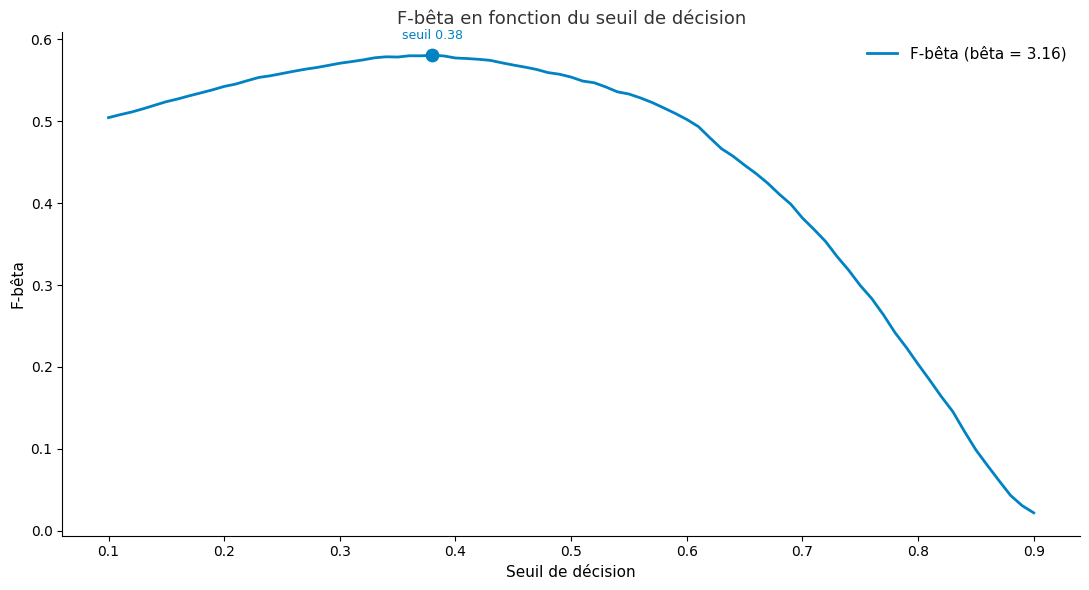

In [143]:
# Courbe du F-bêta en fonction du seuil de décision.
# Le F-bêta se maximise : le sommet de la courbe donne le seuil optimal.
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(seuils, fbetas, color="#0082C3", linewidth=2, label=f"F-bêta (bêta = {BETA:.2f})")

# Point du seuil optimal, avec annotation
ax.scatter(seuil_optimal, fbeta_optimal, color="#0082C3", s=80, zorder=5)
ax.annotate(f"seuil {seuil_optimal:.2f}",
            (seuil_optimal, fbeta_optimal),
            textcoords="offset points", xytext=(0, 12), ha="center",
            fontsize=9, color="#0082C3")

ax.set_xlabel("Seuil de décision", fontsize=11)
ax.set_ylabel("F-bêta", fontsize=11)
ax.set_title("F-bêta en fonction du seuil de décision", fontsize=13, color="#333333")
ax.legend(frameon=False, fontsize=11)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## Optimisation des hyperparamètres

### Recherche par grille (GridSearchCV)

In [152]:
# # --- Vérification préalable des ressources ---
# N_CORES = os.cpu_count()
# print(f"Cœurs disponibles : {N_CORES}")
# print(f"Taille de X_train : {X_train.memory_usage(deep=True).sum() / 1e9:.2f} Go")

# # Règle : n_jobs(GridSearch) x n_jobs(modele) <= nombre de coeurs
# N_JOBS_SEARCH = 3
# N_JOBS_MODEL = 3

# # Scorer pour l'optimisation : le F-bêta, avec bêta = racine de 10 (environ 3,16).
# # Le F-bêta se maximise, donc greater_is_better=True (valeur par défaut).
# scorer_fbeta = make_scorer(fbeta_score, beta=BETA)

# # Pipeline à optimiser : préparation (features, imputation, encodage) puis LightGBM.
# # n_jobs du modèle est borné pour éviter le parallélisme imbriqué avec GridSearchCV.
# pipeline_opt = Pipeline([
#     ("preparation", preparation),
#     ("modele", LGBMClassifier(
#         class_weight="balanced",
#         random_state=RANDOM_STATE,
#         n_jobs=N_JOBS_MODEL,
#         verbose=-1,
#     )),
# ])

# # Grille d'hyperparamètres. Chaque paramètre encadre sa valeur par défaut,
# # afin de vérifier que l'optimum n'est pas un effet de bord.
# grille = {
#     "modele__n_estimators": [100, 300, 500],
#     "modele__learning_rate": [0.05, 0.1, 0.2],
#     "modele__num_leaves": [10, 15, 31],
#     "modele__max_depth": [-1, 5, 10],
# }

# # Recherche sur grille en validation croisée stratifiée, maximisant le F-bêta.
# # pre_dispatch limite le nombre de tâches pré-chargées, donc les copies de données.
# grid_search = GridSearchCV(
#     pipeline_opt,
#     param_grid=grille,
#     scoring=scorer_fbeta,
#     cv=cv,
#     n_jobs=N_JOBS_SEARCH,
#     pre_dispatch="n_jobs",
#     verbose=1,
# )

# grid_search.fit(X_train, y_train)

# print(f"Meilleurs hyperparamètres : {grid_search.best_params_}")
# print(f"Meilleur F-bêta (validation croisée) : {grid_search.best_score_:.4f}")

In [145]:
# --- Vérification préalable des ressources ---
N_CORES = os.cpu_count()
print(f"Cœurs disponibles : {N_CORES}")
print(f"Taille de X_train : {X_train.memory_usage(deep=True).sum() / 1e9:.2f} Go")

# Règle : n_jobs(GridSearch) x n_jobs(modele) <= nombre de coeurs
N_JOBS_SEARCH = 3
N_JOBS_MODEL = 3

# Scorer pour l'optimisation : le F-bêta, avec bêta = racine de 10 (environ 3,16).
# Le F-bêta se maximise, donc greater_is_better=True (valeur par défaut).
scorer_fbeta = make_scorer(fbeta_score, beta=BETA)

# Pipeline à optimiser : préparation (features, imputation, encodage) puis LightGBM.
# n_jobs du modèle est borné pour éviter le parallélisme imbriqué avec GridSearchCV.
pipeline_opt = Pipeline([
    ("preparation", preparation),
    ("modele", LGBMClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS_MODEL,
        verbose=-1,
    )),
])

# Grille d'hyperparamètres. Chaque paramètre encadre sa valeur par défaut,
# afin de vérifier que l'optimum n'est pas un effet de bord.
grille = {
    "modele__n_estimators": [100, 300],
    "modele__learning_rate": [0.05, 0.1],
    "modele__num_leaves": [10, 15],
    "modele__max_depth": [-1, 5],
}

# Recherche sur grille en validation croisée stratifiée, maximisant le F-bêta.
# pre_dispatch limite le nombre de tâches pré-chargées, donc les copies de données.
grid_search = GridSearchCV(
    pipeline_opt,
    param_grid=grille,
    scoring=scorer_fbeta,
    cv=cv,
    n_jobs=N_JOBS_SEARCH,
    pre_dispatch="n_jobs",
    verbose=1,
)

grid_search.fit(X_train, y_train)

print(f"Meilleurs hyperparamètres : {grid_search.best_params_}")
print(f"Meilleur F-bêta (validation croisée) : {grid_search.best_score_:.4f}")

Cœurs disponibles : 11
Taille de X_train : 0.53 Go
Fitting 5 folds for each of 16 candidates, totalling 80 fits


/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/ut

Meilleurs hyperparamètres : {'modele__learning_rate': 0.05, 'modele__max_depth': -1, 'modele__n_estimators': 300, 'modele__num_leaves': 15}
Meilleur F-bêta (validation croisée) : 0.5544


In [153]:
# print("Cœurs :", os.cpu_count())
# print(f"X_train : {X_train.memory_usage(deep=True).sum() / 1e9:.2f} Go")

## Modèle final : hyperparamètres et seuil 

In [147]:
# Modèle final : on reprend directement le meilleur estimateur trouvé par le GridSearch.
modele_final = grid_search.best_estimator_
print("Modèle final : meilleur estimateur du GridSearch.")
print(f"Hyperparamètres retenus : {grid_search.best_params_}")

Modèle final : meilleur estimateur du GridSearch.
Hyperparamètres retenus : {'modele__learning_rate': 0.05, 'modele__max_depth': -1, 'modele__n_estimators': 300, 'modele__num_leaves': 15}


### Réoptimisation du seuil sur le modèle optimisé
Le seuil de décision qui maximise le F-bêta est recherché sur le modèle optimisé. Il peut différer de celui obtenu sur le modèle par défaut, les hyperparamètres ayant changé.

In [148]:
# Probabilités prédites par le modèle optimisé sur le jeu de test
proba_final = modele_final.predict_proba(X_test)[:, 1]

# Recherche du seuil qui maximise le F-bêta, sur le modèle optimisé.
# Le F-bêta se maximise : on retient le seuil qui donne la valeur la plus élevée.
seuils = np.arange(0.1, 0.91, 0.01)
fbetas = []
for seuil in seuils:
    y_pred = (proba_final >= seuil).astype(int)
    fbetas.append(fbeta_score(y_test, y_pred, beta=BETA))

fbetas = np.array(fbetas)
seuil_optimal = seuils[fbetas.argmax()]
fbeta_optimal = fbetas.max()

print(f"Seuil optimal du modèle optimisé : {seuil_optimal:.2f}")
print(f"F-bêta au seuil optimal (jeu de test) : {fbeta_optimal:.4f}")

/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Seuil optimal du modèle optimisé : 0.36
F-bêta au seuil optimal (jeu de test) : 0.5796


### Comparaison au modèle de départ

Le gain de l'optimisation est mesuré en comparant le modèle final (hyperparamètres et seuil optimisés) au modèle de départ (hyperparamètres par défaut, seuil de 0,5), sur le jeu de test.

In [149]:
# Modèle de départ : LightGBM par défaut (pondéré), seuil 0,5.
# Sert de point de comparaison pour mesurer l'apport de l'optimisation.
modele_depart = Pipeline([
    ("preparation", preparation),
    ("modele", LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)),
])
modele_depart.fit(X_train, y_train)
proba_depart = modele_depart.predict_proba(X_test)[:, 1]

# F-bêta du modèle de départ au seuil 0,5
y_pred_depart = (proba_depart >= 0.5).astype(int)
fbeta_depart = fbeta_score(y_test, y_pred_depart, beta=BETA)

# F-bêta du modèle final au seuil optimisé (déjà calculé : fbeta_optimal)
gain = fbeta_optimal - fbeta_depart
gain_pct = gain / fbeta_depart * 100

print(f"F-bêta du modèle de départ (seuil 0,5)      : {fbeta_depart:.4f}")
print(f"F-bêta du modèle final (seuil {seuil_optimal:.2f})  : {fbeta_optimal:.4f}")
print(f"Gain absolu : {gain:.4f}")
print(f"Gain relatif : {gain_pct:.1f} %")

F-bêta du modèle de départ (seuil 0,5)      : 0.5540
F-bêta du modèle final (seuil 0.36)  : 0.5796
Gain absolu : 0.0255
Gain relatif : 4.6 %


/Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P6/credit-scoring-mlops/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


**Gain de l'optimisation :**

Le F-bêta passe de 0,5540 pour le modèle de départ, au seuil par défaut de 0,5, à 0,5796 pour le modèle final optimisé, au seuil de 0,36. Le gain relatif est de 4,6 pour cent.

Ce gain résulte de deux optimisations combinées : le réglage des hyperparamètres par recherche sur grille, et l'optimisation du seuil de décision. Il reste modéré, ce qui s'explique par la qualité du modèle de départ, déjà un LightGBM avec pondération des classes. L'optimisation affine un modèle déjà performant plutôt que de corriger un modèle faible. L'essentiel de l'amélioration provient de l'abaissement du seuil, qui privilégie la détection des défauts, conformément à l'objectif métier traduit par le F-bêta.

### Matrice de confusion au seuil optimisé

La matrice de confusion du modèle final, au seuil optimisé, détaille la répartition des décisions : défauts détectés, défauts manqués, bons clients acceptés ou refusés.

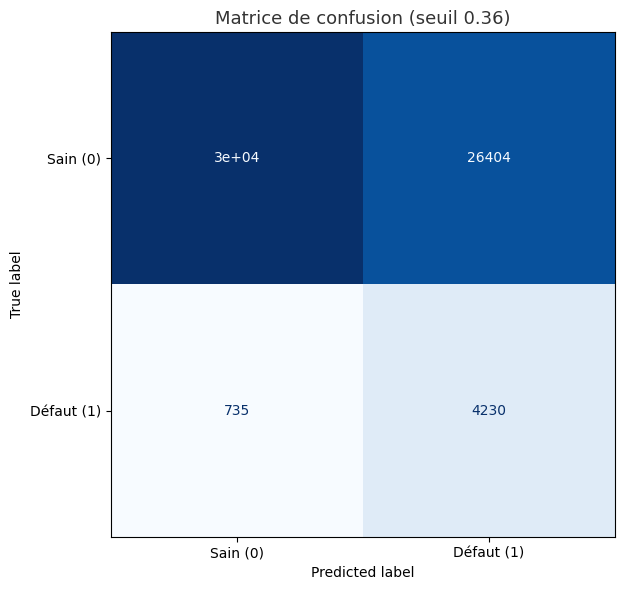

Vrais négatifs (bons clients acceptés)  : 30,134
Faux positifs (bons clients refusés)    : 26,404
Faux négatifs (défauts manqués)         : 735
Vrais positifs (défauts détectés)       : 4,230

Rappel : 85.2 %  (part des défauts détectés)
Précision : 13.8 %  (part de bons refus parmi les refus)


In [150]:
# Prédictions du modèle final au seuil optimisé
y_pred_final = (proba_final >= seuil_optimal).astype(int)
matrice = confusion_matrix(y_test, y_pred_final)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=matrice,
                              display_labels=["Sain (0)", "Défaut (1)"])
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matrice de confusion (seuil {seuil_optimal:.2f})", fontsize=13, color="#333333")
plt.tight_layout()
plt.show()

# Décomposition chiffrée
tn, fp, fn, tp = matrice.ravel()
print(f"Vrais négatifs (bons clients acceptés)  : {tn:,}")
print(f"Faux positifs (bons clients refusés)    : {fp:,}")
print(f"Faux négatifs (défauts manqués)         : {fn:,}")
print(f"Vrais positifs (défauts détectés)       : {tp:,}")

# Indicateurs métier : rappel et précision
rappel = tp / (tp + fn) * 100
precision = tp / (tp + fp) * 100
print(f"\nRappel : {rappel:.1f} %  (part des défauts détectés)")
print(f"Précision : {precision:.1f} %  (part de bons refus parmi les refus)")

**Analyse de la matrice de confusion (seuil 0,36) :**

Au seuil optimal de 0,36, le modèle détecte 4 230 défauts sur 4 965, soit un rappel de 85,2 pour cent. Il ne manque que 735 défauts. En contrepartie, il refuse 26 404 bons clients, et la précision s'établit à 13,8 pour cent.

Ce compromis traduit le choix d'un F-bêta avec bêta égal à la racine de dix, qui privilégie fortement le rappel. Le modèle répond ainsi à l'objectif prioritaire du crédit, ne pas manquer les défauts coûteux, au prix d'un nombre élevé de refus de bons clients. Le paramètre bêta constitue un curseur : une valeur plus faible remonterait la précision au détriment du rappel. Le choix de la racine de dix découle de l'hypothèse métier selon laquelle un défaut non détecté coûte environ dix fois un refus injustifié.

## Enregistrement du modèle final

Le modèle final optimisé est enregistré dans le registre de modèles MLflow, avec ses hyperparamètres, son seuil de décision et ses métriques, pour assurer la traçabilité et permettre son déploiement ultérieur.

In [151]:
# Enregistrement du modèle final dans le registre MLflow.
# La métrique d'optimisation est le F-bêta ; les hyperparamètres sont repris du GridSearch.
# Les métriques techniques (AUC, AP) sont ajoutées pour une vue complète.
BETA_VAL = BETA  # bêta retenu (racine de 10, environ 3,16)

# Métriques techniques du modèle final sur le jeu de test
auc_final = roc_auc_score(y_test, proba_final)
ap_final = average_precision_score(y_test, proba_final)

with mlflow.start_run(run_name="lightgbm_optimise_final") as run:
    mlflow.set_tag("etape", "modele_final")
    mlflow.set_tag("approche", "F-beta")
    mlflow.set_tag("mlflow.note.content",
                   "Modèle final : LightGBM optimisé par GridSearch sur le F-bêta, "
                   "avec seuil de décision optimisé.")

    # Hyperparamètres repris directement du GridSearch (pas de valeurs en dur)
    for nom_param, valeur in grid_search.best_params_.items():
        mlflow.log_param(nom_param, valeur)

    # Seuil de décision optimisé et bêta retenu
    mlflow.log_param("seuil_decision", round(float(seuil_optimal), 2))
    mlflow.log_param("beta", round(float(BETA_VAL), 2))

    # Métriques : F-bêta au seuil optimisé, plus les métriques techniques
    mlflow.log_metric("fbeta", float(fbeta_optimal))
    mlflow.log_metric("AUC", float(auc_final))
    mlflow.log_metric("AP", float(ap_final))

    # Modèle final
    mlflow.sklearn.log_model(modele_final, name="modele")
    run_id_final = run.info.run_id

# Enregistrement dans le registry, sous un nom distinct des autres notebooks
uri_modele = f"runs:/{run_id_final}/modele"
version = mlflow.register_model(model_uri=uri_modele, name="credit_scoring_lightgbm_fbeta")
print(f"Modèle final enregistré : {version.name}, version {version.version}")

2026/07/18 09:54:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/07/18 09:54:09 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Successfully registered model 'credit_scoring_lightgbm_fbeta'.
2026/07/18 09:54:09 WARNING mlflow.tracking._model_registry.fluent: Run with id fa729978ce69413f9bb84e8dca7cbc6e has no artifacts at artifact path 'modele', registering model based on models:/m-6de02804c7884463bd0ef1e82eb528da instead


Modèle final enregistré : credit_scoring_lightgbm_fbeta, version 1


Created version '1' of model 'credit_scoring_lightgbm_fbeta'.


**Enregistrement du modèle final**

Le modèle final, ses hyperparamètres (issus du GridSearch), son seuil de décision et son F-bêta sont enregistrés dans le registre MLflow, pour la traçabilité et un déploiement éventuel.

## Conclusion de l'étape 4

Les hyperparamètres de LightGBM ont été optimisés par recherche sur grille, en maximisant directement le F-bêta, avec bêta égal à la racine de dix (environ 3,16). Ce choix de bêta traduit l'hypothèse métier selon laquelle un faux négatif compte environ dix fois un faux positif, et privilégie donc la détection des défauts.

Le seuil de décision a ensuite été optimisé sur le modèle retenu, et s'établit à 0,36. Ce seuil, plus bas que la valeur par défaut, reflète la priorité donnée au rappel : le modèle détecte 85 pour cent des défauts.

Le gain par rapport au modèle de départ est modéré (4,6 pour cent sur le F-bêta), la pondération des classes ayant déjà calibré le modèle près de l'optimum. La démarche, entièrement guidée par le F-bêta, est cohérente de la sélection à l'optimisation du seuil. Le modèle final est enregistré dans le registre MLflow.